# 08 — Model Interpretability

## Healthcare Readmission Analytics

### Purpose

This notebook investigates how the locked HistGradientBoosting (HGB) development
model generates 30-day hospital readmission risk estimates.

The objective is not to improve model performance or select another model. Instead,
the analysis focuses on understanding the predictive information used by the existing
model and communicating those relationships responsibly.

Interpretability analyses will address four questions:

1. Which features contribute most strongly to predictive performance?
2. How do important features influence model predictions?
3. Can transformed and one-hot-encoded effects be translated back into
   understandable source-feature concepts?
4. How stable and trustworthy are the resulting explanations?

The notebook uses model-agnostic and model-specific interpretability techniques where
appropriate, including permutation importance and SHAP-based analysis.

Interpretability results describe **model behavior and predictive associations**.
They do not establish that a feature causes or prevents hospital readmission.

## M8A — Interpretability Boundary

Notebook 08 operates under the following methodological constraints.

### Model boundary

- The HistGradientBoosting model family is already selected.
- Hyperparameters remain locked from the development process.
- Notebook 08 does not perform additional model selection or hyperparameter tuning.
- Interpretability methods must explain the existing predictive system rather than
  optimize it.

### Data boundary

- Training and validation data may be used to reconstruct the development model and
  generate interpretability analyses.
- Patient identifiers are retained only for auditing and traceability and are not
  predictors.
- Source outcome variables and previously excluded leakage-prone variables remain
  outside the model feature contract.
- The held-out test partition is not used to choose features, explanations, thresholds,
  or interpretability methods.

### Explanation boundary

Feature importance and SHAP values describe how the fitted model uses available
information. They should not be interpreted as:

- causal treatment effects,
- evidence that changing a feature will change readmission risk,
- clinical recommendations,
- proof that a demographic characteristic causes an outcome,
- or evidence that a particular variable should be used for clinical intervention.

Correlated and redundant predictors may divide or redistribute apparent importance.
Engineered variables may also overlap with their underlying source variables.

### Evaluation relationship

Notebook 07 established patient-aware development robustness, calibration, threshold
behavior, and subgroup performance. Notebook 08 does not replace that validation.

The interpretability analysis therefore answers:

> **What predictive relationships has the locked model learned?**

rather than:

> **What causes 30-day readmission?**

## M8B — Environment and Interpretability Artifact Audit

Before generating model explanations, the project artifacts are audited to determine
exactly which fitted objects, feature contracts, and development outputs are available.

This step prevents interpretability from being performed against a model or
preprocessing representation that differs from the system evaluated previously.

The audit will verify:

- project and artifact paths,
- persisted feature-engineering contracts,
- the locked HGB development configuration,
- availability of the fitted HGB model,
- availability of the fitted preprocessing transformer,
- development train/validation partitions,
- Notebook 07 validation metadata,
- and the continued separation of the held-out test partition.

No model fitting, feature selection, or interpretability computation occurs during
this audit.

In [1]:
# M8B.1 — Environment and artifact-path audit

from pathlib import Path
import json
import sys

import joblib
import numpy as np
import pandas as pd
import sklearn

# ----------------------------------------------------------
# Resolve project root
# ----------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "notebooks").exists(), "Project root could not be resolved."


DATA_DIR = PROJECT_ROOT / "data" / "processed"

MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR = PROJECT_ROOT / "reports"


# ----------------------------------------------------------
# Required artifacts
# ----------------------------------------------------------

artifact_contract = {
    "train_data": DATA_DIR / "train.csv",
    "validation_data": DATA_DIR / "validation.csv",
    "test_data": DATA_DIR / "test.csv",
    "feature_registry": DATA_DIR / "feature_registry.json",
    "category_registry": REPORTS_DIR / "category_registry.json",
    "feature_engineering_metadata": REPORTS_DIR / "feature_engineering_metadata.json",
    "baseline_model_metadata": REPORTS_DIR / "baseline_model_metadata.json",
    "hgb_development_model": MODELS_DIR / "hist_gradient_boosting_development.joblib",
    "persisted_preprocessor": MODELS_DIR / "preprocessor.joblib",
    "notebook06_metadata": MODELS_DIR / "notebook06_optimization_metadata.json",
    "notebook07_metadata": REPORTS_DIR / "notebook07_validation_metadata.json",
}


print("NOTEBOOK 08 ENVIRONMENT & ARTIFACT AUDIT")

print("=" * 100)

print(f"Project root: {PROJECT_ROOT}")

print(f"Python: {sys.version.split()[0]}")

print(f"pandas: {pd.__version__}")

print(f"NumPy: {np.__version__}")

print(f"scikit-learn: {sklearn.__version__}")

print()


for name, path in artifact_contract.items():

    status = "FOUND" if path.exists() else "MISSING"

    print(f"{status:<8} " f"{name:<32} " f"{path}")


print("\nArtifact counts:")

print(
    "Found:",
    sum(path.exists() for path in artifact_contract.values()),
)

print(
    "Expected:",
    len(artifact_contract),
)

NOTEBOOK 08 ENVIRONMENT & ARTIFACT AUDIT
Project root: c:\Users\amohe.000\Downloads\healthcare-readmission-analytics
Python: 3.13.6
pandas: 3.0.5
NumPy: 2.5.2
scikit-learn: 1.9.0

FOUND    train_data                       c:\Users\amohe.000\Downloads\healthcare-readmission-analytics\data\processed\train.csv
FOUND    validation_data                  c:\Users\amohe.000\Downloads\healthcare-readmission-analytics\data\processed\validation.csv
FOUND    test_data                        c:\Users\amohe.000\Downloads\healthcare-readmission-analytics\data\processed\test.csv
FOUND    feature_registry                 c:\Users\amohe.000\Downloads\healthcare-readmission-analytics\data\processed\feature_registry.json
FOUND    category_registry                c:\Users\amohe.000\Downloads\healthcare-readmission-analytics\reports\category_registry.json
FOUND    feature_engineering_metadata     c:\Users\amohe.000\Downloads\healthcare-readmission-analytics\reports\feature_engineering_metadata.json
FOUND  

In [2]:
from pathlib import Path


# ----------------------------------------------------------
# Resolve repository root
#
# VS Code/Jupyter may launch this notebook either from the
# repository root or from the notebooks/ directory.
# Normalize the working directory so all relative artifact
# paths resolve consistently from the repository root.
# ----------------------------------------------------------

CURRENT_WORKING_DIR = Path.cwd().resolve()


if (
    (CURRENT_WORKING_DIR / "notebooks").exists()
    and (CURRENT_WORKING_DIR / "data").exists()
):
    PROJECT_ROOT = CURRENT_WORKING_DIR

elif (
    CURRENT_WORKING_DIR.name == "notebooks"
    and (CURRENT_WORKING_DIR.parent / "data").exists()
):
    PROJECT_ROOT = CURRENT_WORKING_DIR.parent

else:
    raise RuntimeError(
        "Unable to resolve healthcare-readmission-analytics "
        f"repository root from: {CURRENT_WORKING_DIR}"
    )


if Path.cwd().resolve() != PROJECT_ROOT:
    %cd $PROJECT_ROOT


print(
    f"Initial working directory: {CURRENT_WORKING_DIR}"
)

print(
    f"Resolved project root:      {PROJECT_ROOT}"
)

print(
    f"Active working directory:   {Path.cwd().resolve()}"
)

assert Path.cwd().resolve() == PROJECT_ROOT

print(
    "✓ Repository root resolved."
)

C:\Users\amohe.000\Downloads\healthcare-readmission-analytics
Initial working directory: C:\Users\amohe.000\Downloads\healthcare-readmission-analytics\notebooks
Resolved project root:      C:\Users\amohe.000\Downloads\healthcare-readmission-analytics
Active working directory:   C:\Users\amohe.000\Downloads\healthcare-readmission-analytics
✓ Repository root resolved.


### M8B.2 — Persisted Model and Preprocessing Contract

The persisted HGB model and preprocessing artifacts are inspected before explanation.

This audit determines whether the saved model and transformer form a compatible
development-model representation suitable for interpretability. Artifact existence
alone does not establish that two fitted objects were trained together, so their
feature dimensions, fitted state, metadata, and locked model parameters are checked
explicitly.

The held-out test dataset is not loaded during this audit.

In [3]:
# M8B.2 — Persisted model, metadata, and preprocessing audit

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer

# ----------------------------------------------------------
# Load metadata / contracts only
# ----------------------------------------------------------

with open(
    artifact_contract["feature_registry"],
    "r",
    encoding="utf-8",
) as f:
    feature_registry = json.load(f)


with open(
    artifact_contract["feature_engineering_metadata"],
    "r",
    encoding="utf-8",
) as f:
    feature_engineering_metadata = json.load(f)


with open(
    artifact_contract["notebook06_metadata"],
    "r",
    encoding="utf-8",
) as f:
    notebook06_metadata = json.load(f)


with open(
    artifact_contract["notebook07_metadata"],
    "r",
    encoding="utf-8",
) as f:
    notebook07_metadata = json.load(f)


# ----------------------------------------------------------
# Load persisted fitted objects
# ----------------------------------------------------------

persisted_hgb = joblib.load(artifact_contract["hgb_development_model"])

persisted_preprocessor = joblib.load(artifact_contract["persisted_preprocessor"])


# ----------------------------------------------------------
# Type / fitted-state audit
# ----------------------------------------------------------

assert isinstance(
    persisted_hgb,
    HistGradientBoostingClassifier,
)

assert isinstance(
    persisted_preprocessor,
    ColumnTransformer,
)

assert hasattr(
    persisted_hgb,
    "n_features_in_",
)

assert hasattr(
    persisted_preprocessor,
    "transformers_",
)


# ----------------------------------------------------------
# Locked HGB configuration
# ----------------------------------------------------------

LOCKED_HGB_PARAMS = {
    "learning_rate": 0.03,
    "max_iter": 400,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 40,
    "l2_regularization": 2.0,
}


persisted_hgb_params = persisted_hgb.get_params()


for param, expected_value in LOCKED_HGB_PARAMS.items():

    actual_value = persisted_hgb_params[param]

    assert np.isclose(
        actual_value,
        expected_value,
    ), (
        f"HGB parameter mismatch: "
        f"{param}={actual_value}, "
        f"expected {expected_value}"
    )


# Notebook 06 also intentionally fixed these.
assert persisted_hgb_params["random_state"] == 42

assert persisted_hgb_params["early_stopping"] is False


# ----------------------------------------------------------
# Preprocessor feature dimensions
# ----------------------------------------------------------

preprocessor_input_features = list(persisted_preprocessor.feature_names_in_)

transformed_feature_names = list(persisted_preprocessor.get_feature_names_out())

preprocessor_input_count = len(preprocessor_input_features)

transformed_feature_count = len(transformed_feature_names)

hgb_input_count = int(persisted_hgb.n_features_in_)


# ----------------------------------------------------------
# Feature-registry contract
# ----------------------------------------------------------

raw_model_features = list(feature_registry["model_features"])

target_column = feature_registry["target"]

identifier_columns = list(feature_registry["identifiers"])

source_outcome_columns = list(feature_registry["source_outcome"])


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("PERSISTED MODEL & PREPROCESSING CONTRACT AUDIT")

print("=" * 100)

print(f"HGB object: " f"{type(persisted_hgb).__name__}")

print(f"Preprocessor object: " f"{type(persisted_preprocessor).__name__}")

print()

print("Locked HGB parameters:")

for param in LOCKED_HGB_PARAMS:

    print(f"  {param:<24} " f"{persisted_hgb_params[param]}")

print(f"  {'random_state':<24} " f"{persisted_hgb_params['random_state']}")

print(f"  {'early_stopping':<24} " f"{persisted_hgb_params['early_stopping']}")

print()

print(f"Raw registry model features: " f"{len(raw_model_features)}")

print(f"Preprocessor input features: " f"{preprocessor_input_count}")

print(f"Transformed features: " f"{transformed_feature_count}")

print(f"HGB fitted input features: " f"{hgb_input_count}")

print()

print(f"Target: {target_column}")

print(f"Identifiers: {identifier_columns}")

print(f"Source outcome columns: " f"{source_outcome_columns}")

print()

print("Notebook 06 metadata top-level keys:")

print(sorted(notebook06_metadata.keys()))

print()

print("Notebook 07 metadata top-level keys:")

print(sorted(notebook07_metadata.keys()))

print()

print("First 10 preprocessor input features:")

for feature in preprocessor_input_features[:10]:

    print(f"  {feature}")

print()

print("First 15 transformed features:")

for feature in transformed_feature_names[:15]:

    print(f"  {feature}")

print()

print("✓ Persisted HGB is fitted.")

print("✓ Persisted preprocessor is fitted.")

print("✓ Locked HGB configuration verified.")

print("✓ Feature dimensions inspected.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset was not loaded.")

PERSISTED MODEL & PREPROCESSING CONTRACT AUDIT
HGB object: HistGradientBoostingClassifier
Preprocessor object: ColumnTransformer

Locked HGB parameters:
  learning_rate            0.03
  max_iter                 400
  max_leaf_nodes           31
  min_samples_leaf         40
  l2_regularization        2.0
  random_state             42
  early_stopping           False

Raw registry model features: 44
Preprocessor input features: 48
Transformed features: 213
HGB fitted input features: 213

Target: readmitted_30d
Identifiers: ['encounter_id', 'patient_nbr']
Source outcome columns: ['readmitted']

Notebook 06 metadata top-level keys:
['histogram_gradient_boosting', 'random_forest']

Notebook 07 metadata top-level keys:
['calibration', 'development_cohort', 'development_screening_threshold', 'evaluation_boundary', 'fairness_analysis', 'feature_contract', 'interpretation', 'locked_hgb_configuration', 'notebook', 'patient_bootstrap', 'pooled_oof_performance']

First 10 preprocessor input feat

### M8B.3 — Persisted Pipeline Provenance and Prediction Reproduction

Dimensional compatibility alone does not prove that a persisted preprocessing object
and fitted model belong to the same predictive pipeline.

The persisted development pipeline is therefore reconstructed using the original
feature-engineering and category-consolidation contracts and evaluated on the
development validation partition previously used in Notebook 06.

The resulting validation metrics are compared with the recorded Notebook 06 HGB
results. Successful reproduction provides stronger evidence that the persisted
preprocessor and HGB model represent the previously evaluated development system.

This is a provenance and reproducibility audit, not a new model evaluation.

The held-out test partition remains unloaded.

In [4]:
# M8B.3a — Inspect persisted Notebook 06 / feature-engineering metadata

print("NOTEBOOK 06 HGB METADATA")

print("=" * 90)

print(
    json.dumps(
        notebook06_metadata["histogram_gradient_boosting"],
        indent=2,
    )
)


print("\nFEATURE-ENGINEERING METADATA")

print("=" * 90)

print(
    json.dumps(
        feature_engineering_metadata,
        indent=2,
    )
)

NOTEBOOK 06 HGB METADATA
{
  "candidate": 3,
  "parameters": {
    "learning_rate": 0.03,
    "max_iter": 400,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 40,
    "l2_regularization": 2.0
  },
  "development_threshold": 0.08900000000000001,
  "validation_performance": {
    "roc_auc": 0.6342595753951608,
    "average_precision": 0.19067513259595711,
    "brier_score": 0.09534351457775374,
    "sensitivity": 0.7397342995169082,
    "specificity": 0.4400568394286142,
    "precision": 0.14061065197428835,
    "balanced_accuracy": 0.5898955694727612,
    "f1": 0.23630401234567902
  },
  "independent_test_evaluated": false,
  "status": "preferred_development_model"
}

FEATURE-ENGINEERING METADATA
{
  "random_state": 42,
  "target": "readmitted_30d",
  "rare_category_min_count": 100,
  "n_train": 71520,
  "n_validation": 15027,
  "n_test": 15219,
  "primary_predictor_count": 48,
  "numeric_feature_count": 13,
  "categorical_feature_count": 35,
  "transformed_feature_count": 213,
  "num

In [5]:
# M8B.3b — Feature-engineering function availability audit

required_engineering_functions = [
    "engineer_features",
    "apply_category_registry",
    "map_diagnosis_family",
]

print("FEATURE-ENGINEERING FUNCTION AVAILABILITY")

print("=" * 80)


for function_name in required_engineering_functions:

    if function_name in globals():

        obj = globals()[function_name]

        print(f"✓ {function_name:<30} " f"{type(obj).__name__}")

    else:

        print(f"✗ {function_name:<30} " "not defined")


print("\nNo data transformed and no model fitted.")

print("Held-out test dataset remains unloaded.")

FEATURE-ENGINEERING FUNCTION AVAILABILITY
✗ engineer_features              not defined
✗ apply_category_registry        not defined
✗ map_diagnosis_family           not defined

No data transformed and no model fitted.
Held-out test dataset remains unloaded.


### M8B.4 — Deterministic Feature Transformation Contract

The deterministic feature-engineering and category-consolidation logic used by the
development pipeline is reconstructed explicitly in Notebook 08.

The transformation sequence is:

1. Select the 44 registered raw model predictors.
2. Engineer eight deterministic utilization and diagnosis-family features.
3. Remove the four primary excluded predictors.
4. Retain the resulting 48-feature model contract.
5. Apply the category registry learned previously from training data.
6. Apply the persisted fitted preprocessing transformer.
7. Verify that the resulting representation contains the 213 features expected by
   the persisted HGB model.

No category rules are learned from validation data, and no model is fitted during
this reconstruction.

In [6]:
# M8B.4 — Reconstruct deterministic transformation functions

UTILIZATION_COLUMNS = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
]

DIAGNOSIS_COLUMNS = [
    "diag_1",
    "diag_2",
    "diag_3",
]


def map_diagnosis_family(value):
    """
    Map an ICD-9 diagnosis code to the broad clinical
    family used by the project feature-engineering contract.
    """

    if pd.isna(value):
        return "Other / Unclassified"

    code = str(value).strip().upper()

    if code in {"", "?", "NAN", "NONE"}:
        return "Other / Unclassified"

    # ICD-9 supplementary and external-cause codes.
    if code.startswith("V"):
        return "Supplementary factors"

    if code.startswith("E"):
        return "External causes"

    # Use integer portion before decimal.
    try:
        numeric_code = int(float(code))
    except ValueError:
        return "Other / Unclassified"

    if 1 <= numeric_code <= 139:
        return "Infectious & parasitic"

    elif 140 <= numeric_code <= 239:
        return "Neoplasms"

    elif 240 <= numeric_code <= 279:
        return "Endocrine, nutritional & metabolic"

    elif 280 <= numeric_code <= 289:
        return "Blood disorders"

    elif 290 <= numeric_code <= 319:
        return "Mental disorders"

    elif 320 <= numeric_code <= 389:
        return "Nervous system & sense organs"

    elif 390 <= numeric_code <= 459:
        return "Circulatory"

    elif 460 <= numeric_code <= 519:
        return "Respiratory"

    elif 520 <= numeric_code <= 579:
        return "Digestive"

    elif 580 <= numeric_code <= 629:
        return "Genitourinary"

    elif 630 <= numeric_code <= 679:
        return "Pregnancy & childbirth"

    elif 680 <= numeric_code <= 709:
        return "Skin & subcutaneous tissue"

    elif 710 <= numeric_code <= 739:
        return "Musculoskeletal & connective tissue"

    elif 740 <= numeric_code <= 759:
        return "Congenital anomalies"

    elif 760 <= numeric_code <= 779:
        return "Perinatal conditions"

    elif 780 <= numeric_code <= 799:
        return "Symptoms & ill-defined conditions"

    elif 800 <= numeric_code <= 999:
        return "Injury & poisoning"

    else:
        return "Other / Unclassified"


def engineer_clinical_features(df):
    """
    Reproduce the deterministic clinical feature engineering
    established previously in the project.
    """

    result = df.copy()

    # Aggregate prior utilization.
    result["prior_utilization_total"] = result[UTILIZATION_COLUMNS].sum(axis=1)

    # Log-transform skewed utilization variables.
    for col in UTILIZATION_COLUMNS:

        result[f"log1p_{col}"] = np.log1p(result[col])

    result["log1p_prior_utilization_total"] = np.log1p(
        result["prior_utilization_total"]
    )

    # Broad diagnosis families.
    for col in DIAGNOSIS_COLUMNS:

        result[f"{col}_family"] = result[col].map(map_diagnosis_family)

    return result


def apply_category_registry(
    df,
    categorical_features,
    registry,
):
    """
    Apply training-derived category rules to new data.
    """

    result = df.copy()

    for col in categorical_features:

        normalized = result[col].astype("string").fillna("Missing")

        result[col] = normalized.where(
            normalized.isin(registry[col]),
            "Other",
        )

    return result

In [7]:
# M8B.5 — Validation transformation-contract integrity audit

# ----------------------------------------------------------
# Load persisted training-derived category registry
# ----------------------------------------------------------

with open(
    artifact_contract["category_registry"],
    "r",
    encoding="utf-8",
) as f:
    persisted_category_registry = json.load(f)


# ----------------------------------------------------------
# Load DEVELOPMENT validation partition only
# ----------------------------------------------------------

validation_df = pd.read_csv(artifact_contract["validation_data"])


# ----------------------------------------------------------
# Recover persisted feature contracts
# ----------------------------------------------------------

FINAL_NUMERIC_FEATURES = list(feature_engineering_metadata["numeric_features"])

FINAL_CATEGORICAL_FEATURES = list(feature_engineering_metadata["categorical_features"])

PRIMARY_MODEL_EXCLUSIONS = list(
    feature_engineering_metadata["primary_model_exclusions"]
)

# This numeric + categorical construction is used for
# feature-membership auditing only. It is NOT assumed to be
# the authoritative fitted input order.
FINAL_MODEL_FEATURES = FINAL_NUMERIC_FEATURES + FINAL_CATEGORICAL_FEATURES


# ----------------------------------------------------------
# Validate feature-contract counts
# ----------------------------------------------------------

assert len(FINAL_NUMERIC_FEATURES) == 13

assert len(FINAL_CATEGORICAL_FEATURES) == 35

assert len(FINAL_MODEL_FEATURES) == 48

assert set(FINAL_NUMERIC_FEATURES).isdisjoint(FINAL_CATEGORICAL_FEATURES)


# ----------------------------------------------------------
# Confirm primary exclusions
# ----------------------------------------------------------

assert set(PRIMARY_MODEL_EXCLUSIONS) == {
    "diag_1",
    "diag_2",
    "diag_3",
    "discharge_disposition_description",
}


# ----------------------------------------------------------
# 44 raw registered predictors
# ----------------------------------------------------------

X_validation_raw = validation_df[raw_model_features].copy()

assert X_validation_raw.shape[1] == 44


# ----------------------------------------------------------
# Deterministic engineering: 44 -> 52
# ----------------------------------------------------------

X_validation_engineered = engineer_clinical_features(X_validation_raw)

assert X_validation_engineered.shape[1] == 52


# ----------------------------------------------------------
# Recover authoritative fitted input order
# ----------------------------------------------------------

PERSISTED_MODEL_FEATURE_ORDER = list(persisted_preprocessor.feature_names_in_)

assert len(PERSISTED_MODEL_FEATURE_ORDER) == 48


# Membership must match even though numeric + categorical
# metadata ordering differs from fitted DataFrame ordering.
assert set(PERSISTED_MODEL_FEATURE_ORDER) == set(FINAL_MODEL_FEATURES), (
    "Persisted and reconstructed " "feature membership differs."
)


# ----------------------------------------------------------
# Select final 48 predictors using persisted fitted order
# ----------------------------------------------------------

X_validation_final = X_validation_engineered[PERSISTED_MODEL_FEATURE_ORDER].copy()

assert X_validation_final.shape[1] == 48

assert list(X_validation_final.columns) == PERSISTED_MODEL_FEATURE_ORDER


# ----------------------------------------------------------
# Verify exclusions are absent from final model matrix
# ----------------------------------------------------------

assert not (set(PRIMARY_MODEL_EXCLUSIONS) & set(X_validation_final.columns)), (
    "A primary excluded feature entered " "the final model matrix."
)


# ----------------------------------------------------------
# Apply TRAINING-DERIVED category registry
# ----------------------------------------------------------

assert set(FINAL_CATEGORICAL_FEATURES).issubset(persisted_category_registry.keys()), (
    "Category registry does not contain " "all categorical model features."
)


X_validation_consolidated = apply_category_registry(
    X_validation_final,
    FINAL_CATEGORICAL_FEATURES,
    persisted_category_registry,
)


assert X_validation_consolidated.shape == X_validation_final.shape

assert list(X_validation_consolidated.columns) == PERSISTED_MODEL_FEATURE_ORDER


# ----------------------------------------------------------
# Persisted preprocessing: 48 -> 213
# ----------------------------------------------------------

X_validation_transformed = persisted_preprocessor.transform(X_validation_consolidated)


assert X_validation_transformed.shape[0] == len(validation_df)

assert X_validation_transformed.shape[1] == 213

assert X_validation_transformed.shape[1] == persisted_hgb.n_features_in_


# ----------------------------------------------------------
# Sparse / numeric representation audit
# ----------------------------------------------------------

from scipy import sparse

print("TRANSFORMED MATRIX REPRESENTATION")

print("=" * 90)

print(f"Python type:                  " f"{type(X_validation_transformed).__name__}")

print(f"Shape:                        " f"{X_validation_transformed.shape}")

print(f"dtype:                        " f"{X_validation_transformed.dtype}")

print(f"Sparse matrix:                " f"{sparse.issparse(X_validation_transformed)}")


if sparse.issparse(X_validation_transformed):

    # A sparse matrix stores only nonzero values in .data.
    # Implicit entries are exactly zero and therefore finite.
    assert np.isfinite(X_validation_transformed.data).all()

    transformed_nonzero_count = X_validation_transformed.nnz

    transformed_density = transformed_nonzero_count / (
        X_validation_transformed.shape[0] * X_validation_transformed.shape[1]
    )

    print(f"Stored nonzero values:        " f"{transformed_nonzero_count:,}")

    print(f"Matrix density:               " f"{transformed_density:.4f}")

    print("✓ Sparse matrix stored values " "are finite.")

else:

    assert np.isfinite(X_validation_transformed).all()

    print("✓ Dense matrix values are finite.")


# ----------------------------------------------------------
# Development validation target only
# ----------------------------------------------------------

y_validation = validation_df[target_column].astype(int).to_numpy()


assert len(y_validation) == len(validation_df)

assert set(np.unique(y_validation)).issubset({0, 1})


# ----------------------------------------------------------
# Final integrity report
# ----------------------------------------------------------

print()

print("VALIDATION TRANSFORMATION CONTRACT AUDIT")

print("=" * 90)

print(f"Validation encounters:          " f"{len(validation_df):,}")

print(f"Raw registered predictors:      " f"{X_validation_raw.shape[1]}")

print(f"After feature engineering:      " f"{X_validation_engineered.shape[1]}")

print(f"Primary exclusions:             " f"{len(PRIMARY_MODEL_EXCLUSIONS)}")

print(f"Final model predictors:         " f"{X_validation_final.shape[1]}")

print(f"  Numeric:                      " f"{len(FINAL_NUMERIC_FEATURES)}")

print(f"  Categorical:                  " f"{len(FINAL_CATEGORICAL_FEATURES)}")

print(f"Transformed predictors:         " f"{X_validation_transformed.shape[1]}")

print(f"HGB expected predictors:        " f"{persisted_hgb.n_features_in_}")

print(f"Validation prevalence:          " f"{y_validation.mean():.4f}")

print()

print("✓ 44 → 52 → 48 → 213 " "transformation contract verified.")

print("✓ Final 48-feature membership " "matches persisted preprocessing contract.")

print("✓ Persisted fitted feature order preserved.")

print("✓ Primary excluded predictors remain absent.")

print("✓ Training-derived category registry " "applied without refitting.")

print(
    "✓ Transformed matrix verified as finite numeric data "
    "without unnecessary densification."
)

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

TRANSFORMED MATRIX REPRESENTATION
Python type:                  csr_matrix
Shape:                        (15027, 213)
dtype:                        float64
Sparse matrix:                True
Stored nonzero values:        721,294
Matrix density:               0.2254
✓ Sparse matrix stored values are finite.

VALIDATION TRANSFORMATION CONTRACT AUDIT
Validation encounters:          15,027
Raw registered predictors:      44
After feature engineering:      52
Primary exclusions:             4
Final model predictors:         48
  Numeric:                      13
  Categorical:                  35
Transformed predictors:         213
HGB expected predictors:        213
Validation prevalence:          0.1102

✓ 44 → 52 → 48 → 213 transformation contract verified.
✓ Final 48-feature membership matches persisted preprocessing contract.
✓ Persisted fitted feature order preserved.
✓ Primary excluded predictors remain absent.
✓ Training-derived category registry applied without refitting.
✓ Transfor

### M8B.6 — Persisted Development-Model Prediction Fingerprint

The reconstructed validation representation is passed through the persisted HGB
development model to verify model provenance.

The resulting probability-based metrics are compared directly with the values recorded
when the preferred HGB development model was selected in Notebook 06.

This serves as a prediction fingerprint: reproducing the recorded metrics demonstrates
that the persisted feature-engineering contract, training-derived category rules,
preprocessor, transformed feature representation, and HGB model are operating
consistently with the previously evaluated development pipeline.

No model fitting, threshold selection, calibration, or test-set evaluation occurs here.

In [8]:
# M8B.6 — Persisted HGB validation prediction fingerprint

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

# ----------------------------------------------------------
# Recorded Notebook 06 validation fingerprint
# ----------------------------------------------------------

recorded_hgb_validation = notebook06_metadata["histogram_gradient_boosting"][
    "validation_performance"
]

EXPECTED_ROC_AUC = float(recorded_hgb_validation["roc_auc"])

EXPECTED_AVERAGE_PRECISION = float(recorded_hgb_validation["average_precision"])

EXPECTED_BRIER_SCORE = float(recorded_hgb_validation["brier_score"])


# ----------------------------------------------------------
# Persisted-model probability predictions
# ----------------------------------------------------------
# HistGradientBoostingClassifier requires dense input.
# The persisted preprocessing representation remains sparse
# until this model-interface boundary.

X_validation_hgb = (
    X_validation_transformed.toarray()
    if sparse.issparse(X_validation_transformed)
    else X_validation_transformed
)


assert X_validation_hgb.shape == (
    len(validation_df),
    persisted_hgb.n_features_in_,
)

assert np.isfinite(X_validation_hgb).all()


validation_hgb_probability = persisted_hgb.predict_proba(X_validation_hgb)[:, 1]


assert len(validation_hgb_probability) == len(y_validation)

assert np.isfinite(validation_hgb_probability).all()

assert ((validation_hgb_probability >= 0.0) & (validation_hgb_probability <= 1.0)).all()


# ----------------------------------------------------------
# Reproduced probability metrics
# ----------------------------------------------------------

reproduced_roc_auc = roc_auc_score(
    y_validation,
    validation_hgb_probability,
)

reproduced_average_precision = average_precision_score(
    y_validation,
    validation_hgb_probability,
)

reproduced_brier_score = brier_score_loss(
    y_validation,
    validation_hgb_probability,
)


# ----------------------------------------------------------
# Numerical differences
# ----------------------------------------------------------

roc_difference = reproduced_roc_auc - EXPECTED_ROC_AUC

ap_difference = reproduced_average_precision - EXPECTED_AVERAGE_PRECISION

brier_difference = reproduced_brier_score - EXPECTED_BRIER_SCORE


# Tight tolerance because the same persisted model and
# validation pipeline should reproduce the recorded values.
FINGERPRINT_TOLERANCE = 1e-12


roc_match = np.isclose(
    reproduced_roc_auc,
    EXPECTED_ROC_AUC,
    atol=FINGERPRINT_TOLERANCE,
    rtol=0.0,
)

ap_match = np.isclose(
    reproduced_average_precision,
    EXPECTED_AVERAGE_PRECISION,
    atol=FINGERPRINT_TOLERANCE,
    rtol=0.0,
)

brier_match = np.isclose(
    reproduced_brier_score,
    EXPECTED_BRIER_SCORE,
    atol=FINGERPRINT_TOLERANCE,
    rtol=0.0,
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("PERSISTED HGB VALIDATION PREDICTION FINGERPRINT")

print("=" * 100)

print(
    f"{'Metric':<22}"
    f"{'Recorded':>18}"
    f"{'Reproduced':>18}"
    f"{'Difference':>18}"
    f"{'Match':>12}"
)

print("-" * 100)

print(
    f"{'ROC-AUC':<22}"
    f"{EXPECTED_ROC_AUC:>18.12f}"
    f"{reproduced_roc_auc:>18.12f}"
    f"{roc_difference:>18.3e}"
    f"{str(roc_match):>12}"
)

print(
    f"{'Average Precision':<22}"
    f"{EXPECTED_AVERAGE_PRECISION:>18.12f}"
    f"{reproduced_average_precision:>18.12f}"
    f"{ap_difference:>18.3e}"
    f"{str(ap_match):>12}"
)

print(
    f"{'Brier Score':<22}"
    f"{EXPECTED_BRIER_SCORE:>18.12f}"
    f"{reproduced_brier_score:>18.12f}"
    f"{brier_difference:>18.3e}"
    f"{str(brier_match):>12}"
)


print()

print(f"Validation probabilities:      " f"{len(validation_hgb_probability):,}")

print(f"Minimum probability:           " f"{validation_hgb_probability.min():.6f}")

print(f"Maximum probability:           " f"{validation_hgb_probability.max():.6f}")

print(f"Mean probability:              " f"{validation_hgb_probability.mean():.6f}")

print(f"Observed prevalence:           " f"{y_validation.mean():.6f}")

print()


assert roc_match, "ROC-AUC does not reproduce " "Notebook 06."

assert ap_match, "Average precision does not " "reproduce Notebook 06."

assert brier_match, "Brier score does not reproduce " "Notebook 06."


print("✓ Persisted HGB reproduces the recorded " "Notebook 06 ROC-AUC.")

print("✓ Persisted HGB reproduces the recorded " "Notebook 06 average precision.")

print("✓ Persisted HGB reproduces the recorded " "Notebook 06 Brier score.")

print(
    "✓ Persisted preprocessing and HGB artifacts "
    "form a reproducible development pipeline."
)

print("✓ No model fitting or threshold optimization performed.")

print("✓ Held-out test dataset remains unloaded.")

PERSISTED HGB VALIDATION PREDICTION FINGERPRINT
Metric                          Recorded        Reproduced        Difference       Match
----------------------------------------------------------------------------------------------------
ROC-AUC                   0.634259575395    0.634259575395         0.000e+00        True
Average Precision         0.190675132596    0.190675132596         0.000e+00        True
Brier Score               0.095343514578    0.095343514578         0.000e+00        True

Validation probabilities:      15,027
Minimum probability:           0.011089
Maximum probability:           0.578207
Mean probability:              0.109387
Observed prevalence:           0.110202

✓ Persisted HGB reproduces the recorded Notebook 06 ROC-AUC.
✓ Persisted HGB reproduces the recorded Notebook 06 average precision.
✓ Persisted HGB reproduces the recorded Notebook 06 Brier score.
✓ Persisted preprocessing and HGB artifacts form a reproducible development pipeline.
✓ No model f

## M8C — Transformed Feature Lineage

The HGB model operates on a 213-column transformed representation generated from
48 model-level predictors.

Numeric predictors generally retain one transformed column, while categorical
predictors expand into multiple one-hot-encoded columns. Directly ranking all
transformed columns can therefore fragment the apparent importance of categorical
features and make explanations difficult to communicate.

Notebook 08 establishes explicit lineage between:

1. the 213 transformed model inputs,
2. the 48 model-level predictors,
3. engineered versus source predictors,
4. and broader analytical feature families.

This lineage will later support aggregation of permutation- and SHAP-based
interpretability results without treating individual one-hot indicators as unrelated
features.

Feature aggregation is an interpretability operation only. It does not alter or
refit the predictive model.

In [9]:
# M8C.2 — Build transformed-to-source feature lineage

transformed_feature_names = list(persisted_preprocessor.get_feature_names_out())


assert len(transformed_feature_names) == 213


# ----------------------------------------------------------
# Helper: recover original model feature
# ----------------------------------------------------------


def recover_source_feature(
    transformed_name,
    numeric_features,
    categorical_features,
):
    """
    Map a transformed ColumnTransformer feature name
    back to its original model-level predictor.
    """

    if transformed_name.startswith("numeric__"):

        source_feature = transformed_name.replace(
            "numeric__",
            "",
            1,
        )

        if source_feature not in numeric_features:
            raise ValueError(
                "Unrecognized numeric transformed " f"feature: {transformed_name}"
            )

        return source_feature

    if transformed_name.startswith("categorical__"):

        encoded_name = transformed_name.replace(
            "categorical__",
            "",
            1,
        )

        # Match longest feature names first so that
        # overlapping prefixes cannot be assigned
        # incorrectly.
        candidate_features = sorted(
            categorical_features,
            key=len,
            reverse=True,
        )

        for feature in candidate_features:

            prefix = f"{feature}_"

            if encoded_name.startswith(prefix):
                return feature

        raise ValueError(
            "Unable to map categorical transformed " f"feature: {transformed_name}"
        )

    raise ValueError("Unexpected transformed feature namespace: " f"{transformed_name}")


# ----------------------------------------------------------
# Recover source feature for every transformed column
# ----------------------------------------------------------

transformed_lineage_records = []


for transformed_index, transformed_name in enumerate(transformed_feature_names):

    source_feature = recover_source_feature(
        transformed_name,
        FINAL_NUMERIC_FEATURES,
        FINAL_CATEGORICAL_FEATURES,
    )

    transformed_lineage_records.append(
        {
            "transformed_index": transformed_index,
            "transformed_feature": transformed_name,
            "source_feature": source_feature,
            "source_type": (
                "numeric" if source_feature in FINAL_NUMERIC_FEATURES else "categorical"
            ),
        }
    )


feature_lineage_df = pd.DataFrame(transformed_lineage_records)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert len(feature_lineage_df) == 213

assert feature_lineage_df["transformed_index"].is_unique

assert feature_lineage_df["transformed_feature"].is_unique

assert feature_lineage_df["source_feature"].nunique() == 48

assert set(feature_lineage_df["source_feature"]) == set(FINAL_MODEL_FEATURES)


# ----------------------------------------------------------
# Count transformed columns per source predictor
# ----------------------------------------------------------

source_expansion_df = (
    feature_lineage_df.groupby(
        [
            "source_feature",
            "source_type",
        ],
        as_index=False,
    )
    .agg(
        transformed_columns=(
            "transformed_feature",
            "count",
        )
    )
    .sort_values(
        [
            "transformed_columns",
            "source_feature",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("TRANSFORMED FEATURE LINEAGE AUDIT")

print("=" * 90)

print(
    f"Model-level predictors:       "
    f"{feature_lineage_df['source_feature'].nunique()}"
)

print(f"Transformed predictors:       " f"{len(feature_lineage_df)}")

print(f"Numeric source predictors:    " f"{len(FINAL_NUMERIC_FEATURES)}")

print(f"Categorical source predictors:" f" {len(FINAL_CATEGORICAL_FEATURES)}")

print()

print("Largest one-hot expansions:")

print(source_expansion_df.head(15).to_string(index=False))

print()

print("✓ Every transformed feature maps " "to exactly one model-level predictor.")

print("✓ All 48 model-level predictors " "are represented.")

print("✓ All 213 transformed predictors " "are accounted for.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

TRANSFORMED FEATURE LINEAGE AUDIT
Model-level predictors:       48
Transformed predictors:       213
Numeric source predictors:    13
Categorical source predictors: 35

Largest one-hot expansions:
              source_feature source_type  transformed_columns
           medical_specialty categorical                   25
               diag_2_family categorical                   19
               diag_3_family categorical                   19
               diag_1_family categorical                   17
                  payer_code categorical                   14
admission_source_description categorical                   10
                         age categorical                   10
  admission_type_description categorical                    7
                        race categorical                    6
                   A1Cresult categorical                    4
                 glimepiride categorical                    4
                   glipizide categorical                   

### M8C.3 — Source-Feature Taxonomy and Conceptual Families

Model-level predictors are further organized into interpretable analytical groups.

This taxonomy distinguishes:

- original source predictors,
- engineered predictors,
- demographic variables,
- utilization history,
- encounter characteristics,
- laboratory indicators,
- medication variables,
- and diagnosis-family variables.

The purpose is to support grouped interpretation later in the notebook.

Grouped importance does not imply that all variables within a family have equivalent
effects, nor does it establish causal relationships. It is an explanatory abstraction
used to summarize model behavior at a more interpretable level.

In [10]:
# M8C.3 — Build source-feature taxonomy

ENGINEERED_FEATURES = {
    "prior_utilization_total",
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
    "diag_1_family",
    "diag_2_family",
    "diag_3_family",
}


FEATURE_FAMILIES = {
    # Demographics
    "race": "Demographics",
    "gender": "Demographics",
    "age": "Demographics",
    # Encounter characteristics
    "time_in_hospital": "Encounter characteristics",
    "payer_code": "Encounter characteristics",
    "medical_specialty": "Encounter characteristics",
    "admission_type_description": "Encounter characteristics",
    "admission_source_description": "Encounter characteristics",
    # Clinical workload / complexity
    "num_lab_procedures": "Clinical complexity",
    "num_procedures": "Clinical complexity",
    "num_medications": "Clinical complexity",
    "number_diagnoses": "Clinical complexity",
    # Prior utilization
    "number_outpatient": "Prior utilization",
    "number_emergency": "Prior utilization",
    "number_inpatient": "Prior utilization",
    "prior_utilization_total": "Prior utilization",
    "log1p_number_outpatient": "Prior utilization",
    "log1p_number_emergency": "Prior utilization",
    "log1p_number_inpatient": "Prior utilization",
    "log1p_prior_utilization_total": "Prior utilization",
    # Laboratory / glycemic indicators
    "max_glu_serum": "Laboratory / glycemic",
    "A1Cresult": "Laboratory / glycemic",
    # Medication-management indicators
    "change": "Medication management",
    "diabetesMed": "Medication management",
    # Diagnosis families
    "diag_1_family": "Diagnosis family",
    "diag_2_family": "Diagnosis family",
    "diag_3_family": "Diagnosis family",
}


# ----------------------------------------------------------
# Add medication variables programmatically
# ----------------------------------------------------------

medication_features = [
    feature for feature in FINAL_CATEGORICAL_FEATURES if feature not in FEATURE_FAMILIES
]


for feature in medication_features:
    FEATURE_FAMILIES[feature] = "Diabetes medication"


# ----------------------------------------------------------
# Integrity: every source feature must have exactly one family
# ----------------------------------------------------------

unmapped_features = sorted(set(FINAL_MODEL_FEATURES) - set(FEATURE_FAMILIES))

unexpected_mapped_features = sorted(set(FEATURE_FAMILIES) - set(FINAL_MODEL_FEATURES))


assert unmapped_features == [], f"Unmapped model features: {unmapped_features}"

assert unexpected_mapped_features == [], (
    "Taxonomy contains non-model features: " f"{unexpected_mapped_features}"
)


# ----------------------------------------------------------
# Build source-level taxonomy table
# ----------------------------------------------------------

source_taxonomy_df = source_expansion_df.copy()


source_taxonomy_df["feature_origin"] = source_taxonomy_df["source_feature"].map(
    lambda feature: "engineered" if feature in ENGINEERED_FEATURES else "source"
)


source_taxonomy_df["feature_family"] = source_taxonomy_df["source_feature"].map(
    FEATURE_FAMILIES
)


# ----------------------------------------------------------
# Merge taxonomy back onto transformed lineage
# ----------------------------------------------------------

feature_lineage_df = feature_lineage_df.merge(
    source_taxonomy_df[
        [
            "source_feature",
            "feature_origin",
            "feature_family",
        ]
    ],
    on="source_feature",
    how="left",
    validate="many_to_one",
)


# ----------------------------------------------------------
# Final integrity checks
# ----------------------------------------------------------

assert feature_lineage_df["feature_origin"].notna().all()

assert feature_lineage_df["feature_family"].notna().all()

assert source_taxonomy_df["source_feature"].nunique() == 48


# ----------------------------------------------------------
# Summary tables
# ----------------------------------------------------------

family_summary_df = (
    source_taxonomy_df.groupby(
        "feature_family",
        as_index=False,
    )
    .agg(
        source_features=(
            "source_feature",
            "count",
        ),
        transformed_features=(
            "transformed_columns",
            "sum",
        ),
        engineered_features=(
            "feature_origin",
            lambda s: (s == "engineered").sum(),
        ),
    )
    .sort_values(
        [
            "transformed_features",
            "source_features",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)


print("SOURCE-FEATURE TAXONOMY AUDIT")

print("=" * 90)

print(f"Model-level predictors:       " f"{len(source_taxonomy_df)}")

print(
    f"Source predictors:            "
    f"{(source_taxonomy_df['feature_origin'] == 'source').sum()}"
)

print(
    f"Engineered predictors:        "
    f"{(source_taxonomy_df['feature_origin'] == 'engineered').sum()}"
)

print(
    f"Conceptual feature families:  "
    f"{source_taxonomy_df['feature_family'].nunique()}"
)

print()

print("Feature-family summary:")

print(family_summary_df.to_string(index=False))

print()

print("Engineered predictors:")

print(
    source_taxonomy_df.loc[
        source_taxonomy_df["feature_origin"] == "engineered",
        [
            "source_feature",
            "source_type",
            "feature_family",
            "transformed_columns",
        ],
    ]
    .sort_values("source_feature")
    .to_string(index=False)
)

print()

print("✓ All 48 model-level predictors assigned " "to exactly one conceptual family.")

print("✓ Engineered and source predictors explicitly distinguished.")

print("✓ Transformed lineage now supports " "source- and family-level aggregation.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

SOURCE-FEATURE TAXONOMY AUDIT
Model-level predictors:       48
Source predictors:            40
Engineered predictors:        8
Conceptual feature families:  8

Feature-family summary:
           feature_family  source_features  transformed_features  engineered_features
      Diabetes medication               21                    58                    0
Encounter characteristics                5                    57                    0
         Diagnosis family                3                    55                    3
             Demographics                3                    19                    0
        Prior utilization                8                     8                    5
    Laboratory / glycemic                2                     8                    0
      Clinical complexity                4                     4                    0
    Medication management                2                     4                    0

Engineered predictors:
               so

## M8D — Global Permutation Importance

Permutation importance evaluates how strongly the fitted development model depends on
each predictor by measuring the deterioration in predictive performance after that
predictor's values are randomly permuted.

The model itself remains unchanged.

### Primary analysis

Permutation is performed at the **48-feature model-input level before preprocessing**.

For categorical predictors, this means that a source feature such as
`medical_specialty` is permuted once and its complete one-hot representation is then
regenerated by the persisted preprocessor. This avoids fragmenting a categorical
predictor across many encoded columns.

For numeric predictors, the original model-level value is permuted before the
persisted preprocessing transformation.

### Metrics

Two probability-ranking metrics are evaluated:

- ROC-AUC decrease — primary permutation-importance measure.
- Average-precision decrease — secondary measure appropriate for the imbalanced
  readmission outcome.

Positive importance indicates that permutation reduced predictive performance.
Values near zero indicate little measurable dependence under the current validation
distribution. Negative values can occur because of sampling variation, feature
redundancy, interactions, or chance improvement after permutation.

### Interpretation boundary

Permutation importance measures **predictive dependence**, not causal effect.

Importance may also be diluted when correlated or engineered predictors contain
overlapping information. This is particularly relevant to the prior-utilization
variables, where raw counts, log transformations, and aggregate utilization features
coexist.

The analysis uses the previously evaluated development validation partition. It does
not constitute a new independent generalization estimate, and the held-out test
partition remains unused.

In [11]:
# M8D.2 — Source-level persisted-pipeline prediction wrapper


def predict_persisted_hgb_from_model_features(
    model_feature_frame,
):
    """
    Generate probabilities from the persisted development
    pipeline starting from the final 48 model-level features.

    No feature engineering or model fitting occurs here.
    The input is expected to already contain the final
    engineered 48-feature contract.
    """

    # ------------------------------------------------------
    # Contract validation
    # ------------------------------------------------------

    missing_features = set(PERSISTED_MODEL_FEATURE_ORDER) - set(
        model_feature_frame.columns
    )

    if missing_features:
        raise ValueError("Missing model features: " f"{sorted(missing_features)}")

    X = model_feature_frame[PERSISTED_MODEL_FEATURE_ORDER].copy()

    # ------------------------------------------------------
    # Apply persisted TRAINING-derived category rules
    # ------------------------------------------------------

    X = apply_category_registry(
        X,
        FINAL_CATEGORICAL_FEATURES,
        persisted_category_registry,
    )

    # ------------------------------------------------------
    # Persisted preprocessing
    # ------------------------------------------------------

    X_transformed = persisted_preprocessor.transform(X)

    assert X_transformed.shape[1] == persisted_hgb.n_features_in_

    # ------------------------------------------------------
    # HGB dense-model interface
    # ------------------------------------------------------

    if sparse.issparse(X_transformed):
        X_hgb = X_transformed.toarray()
    else:
        X_hgb = np.asarray(X_transformed)

    probabilities = persisted_hgb.predict_proba(X_hgb)[:, 1]

    return probabilities


# ----------------------------------------------------------
# Wrapper reproduction audit
# ----------------------------------------------------------

wrapper_validation_probability = predict_persisted_hgb_from_model_features(
    X_validation_final
)


assert np.allclose(
    wrapper_validation_probability,
    validation_hgb_probability,
    atol=1e-15,
    rtol=0.0,
)


wrapper_roc_auc = roc_auc_score(
    y_validation,
    wrapper_validation_probability,
)

wrapper_average_precision = average_precision_score(
    y_validation,
    wrapper_validation_probability,
)


print("SOURCE-LEVEL PREDICTION WRAPPER AUDIT")

print("=" * 90)

print(f"Encounters:                   " f"{len(wrapper_validation_probability):,}")

print(f"Model-level predictors:       " f"{X_validation_final.shape[1]}")

print(f"ROC-AUC:                      " f"{wrapper_roc_auc:.12f}")

print(f"Average precision:            " f"{wrapper_average_precision:.12f}")

print(
    f"Maximum probability delta:    "
    f"{np.max(np.abs(wrapper_validation_probability - validation_hgb_probability)):.3e}"
)

print()

print(
    "✓ Source-level prediction wrapper exactly "
    "reproduces persisted-pipeline probabilities."
)

print("✓ Wrapper is ready for permutation-based analysis.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

SOURCE-LEVEL PREDICTION WRAPPER AUDIT
Encounters:                   15,027
Model-level predictors:       48
ROC-AUC:                      0.634259575395
Average precision:            0.190675132596
Maximum probability delta:    0.000e+00

✓ Source-level prediction wrapper exactly reproduces persisted-pipeline probabilities.
✓ Wrapper is ready for permutation-based analysis.
✓ No model fitting performed.
✓ Held-out test dataset remains unloaded.


### M8D.3 — Single-Feature Permutation Integrity Audit

Before computing repeated permutation importance across all model predictors, a
single-feature experiment verifies the permutation procedure.

`number_inpatient` is used as the audit feature. Its values are randomly reassigned
across validation encounters while all other model-level predictors remain unchanged.

A valid permutation must:

- preserve the number of observations,
- preserve the feature's marginal distribution exactly,
- alter its encounter-level ordering,
- leave every non-permuted predictor unchanged,
- and pass successfully through the persisted category-registry, preprocessing,
  and HGB prediction pipeline.

Any resulting performance change in this audit is illustrative only. Formal feature
importance will be estimated later using repeated permutations.

In [12]:
# M8D.3 — Single-feature permutation integrity audit

PERMUTATION_AUDIT_FEATURE = "number_inpatient"

PERMUTATION_AUDIT_SEED = 42


# ----------------------------------------------------------
# Create controlled permutation
# ----------------------------------------------------------

permutation_rng = np.random.default_rng(PERMUTATION_AUDIT_SEED)


X_validation_permuted_audit = X_validation_final.copy()


original_values = X_validation_permuted_audit[PERMUTATION_AUDIT_FEATURE].to_numpy(
    copy=True
)


permuted_values = permutation_rng.permutation(original_values)


X_validation_permuted_audit[PERMUTATION_AUDIT_FEATURE] = permuted_values


# ----------------------------------------------------------
# Structural integrity
# ----------------------------------------------------------

assert X_validation_permuted_audit.shape == X_validation_final.shape

assert list(X_validation_permuted_audit.columns) == list(X_validation_final.columns)


# ----------------------------------------------------------
# Marginal-distribution preservation
# ----------------------------------------------------------
# Sorting both arrays verifies that permutation changed only
# row assignment, not the collection of feature values.

original_sorted = np.sort(original_values)

permuted_sorted = np.sort(permuted_values)


assert np.array_equal(
    original_sorted,
    permuted_sorted,
    equal_nan=True,
)


# ----------------------------------------------------------
# Verify ordering actually changed
# ----------------------------------------------------------

changed_mask = ~(pd.Series(original_values).eq(pd.Series(permuted_values)).to_numpy())


changed_rows = int(changed_mask.sum())

changed_fraction = changed_rows / len(original_values)


assert changed_rows > 0


# ----------------------------------------------------------
# Verify all other 47 predictors remain unchanged
# ----------------------------------------------------------

non_permuted_features = [
    feature
    for feature in PERSISTED_MODEL_FEATURE_ORDER
    if feature != PERMUTATION_AUDIT_FEATURE
]


pd.testing.assert_frame_equal(
    X_validation_permuted_audit[non_permuted_features],
    X_validation_final[non_permuted_features],
    check_dtype=True,
    check_exact=True,
)


# ----------------------------------------------------------
# Generate predictions through persisted pipeline
# ----------------------------------------------------------

permuted_audit_probability = predict_persisted_hgb_from_model_features(
    X_validation_permuted_audit
)


assert len(permuted_audit_probability) == len(y_validation)

assert np.isfinite(permuted_audit_probability).all()

assert ((permuted_audit_probability >= 0.0) & (permuted_audit_probability <= 1.0)).all()


# ----------------------------------------------------------
# Calculate illustrative metric deterioration
# ----------------------------------------------------------

permuted_audit_roc_auc = roc_auc_score(
    y_validation,
    permuted_audit_probability,
)

permuted_audit_ap = average_precision_score(
    y_validation,
    permuted_audit_probability,
)


audit_roc_decrease = wrapper_roc_auc - permuted_audit_roc_auc

audit_ap_decrease = wrapper_average_precision - permuted_audit_ap


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("SINGLE-FEATURE PERMUTATION INTEGRITY AUDIT")

print("=" * 90)

print(f"Audit feature:                " f"{PERMUTATION_AUDIT_FEATURE}")

print(f"Random seed:                  " f"{PERMUTATION_AUDIT_SEED}")

print(f"Validation encounters:        " f"{len(X_validation_final):,}")

print(f"Rows receiving new value:     " f"{changed_rows:,}")

print(f"Fraction changed:             " f"{changed_fraction:.4f}")

print(f"Other predictors unchanged:   " f"{len(non_permuted_features)} / 47")

print()

print("ROC-AUC")

print(f"  Baseline:                   " f"{wrapper_roc_auc:.6f}")

print(f"  Permuted:                   " f"{permuted_audit_roc_auc:.6f}")

print(f"  Decrease:                   " f"{audit_roc_decrease:.6f}")

print()

print("AVERAGE PRECISION")

print(f"  Baseline:                   " f"{wrapper_average_precision:.6f}")

print(f"  Permuted:                   " f"{permuted_audit_ap:.6f}")

print(f"  Decrease:                   " f"{audit_ap_decrease:.6f}")

print()

print("✓ Permutation preserves the feature's " "marginal distribution.")

print("✓ Encounter-level feature ordering changed.")

print("✓ All other 47 model predictors remain unchanged.")

print("✓ Permuted data passes through the persisted pipeline.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

SINGLE-FEATURE PERMUTATION INTEGRITY AUDIT
Audit feature:                number_inpatient
Random seed:                  42
Validation encounters:        15,027
Rows receiving new value:     7,565
Fraction changed:             0.5034
Other predictors unchanged:   47 / 47

ROC-AUC
  Baseline:                   0.634260
  Permuted:                   0.585475
  Decrease:                   0.048785

AVERAGE PRECISION
  Baseline:                   0.190675
  Permuted:                   0.142363
  Decrease:                   0.048312

✓ Permutation preserves the feature's marginal distribution.
✓ Encounter-level feature ordering changed.
✓ All other 47 model predictors remain unchanged.
✓ Permuted data passes through the persisted pipeline.
✓ No model fitting performed.
✓ Held-out test dataset remains unloaded.


### M8D.4 — Repeated Source-Level Permutation Importance

The validated single-feature permutation procedure is extended to all 48 model-level
predictors.

Each predictor is independently permuted 10 times using reproducible random
permutations. After each permutation, the unchanged persisted category-registry,
preprocessor, and HGB model are used to generate validation probabilities.

For each predictor, importance is summarized as the mean decrease in:

- ROC-AUC, the primary ranking metric;
- average precision, the secondary imbalance-sensitive ranking metric.

The standard deviation, minimum, maximum, and proportion of repeats producing a
positive performance decrease are also retained.

These repeated values quantify **permutation variability**, not statistical confidence
intervals for the underlying population effect.

Because correlated or redundant predictors can substitute for one another, low
individual permutation importance does not necessarily imply absence of useful
predictive information. This limitation is especially relevant to the related
prior-utilization features included in the model.

In [13]:
# M8D.4 — Repeated source-level permutation importance

PERMUTATION_REPEATS = 10
PERMUTATION_RANDOM_STATE = 42


# ----------------------------------------------------------
# Baseline metrics
# ----------------------------------------------------------

permutation_baseline_roc_auc = roc_auc_score(
    y_validation,
    wrapper_validation_probability,
)

permutation_baseline_ap = average_precision_score(
    y_validation,
    wrapper_validation_probability,
)


# ----------------------------------------------------------
# Reproducible RNG
# ----------------------------------------------------------

permutation_rng = np.random.default_rng(PERMUTATION_RANDOM_STATE)


# ----------------------------------------------------------
# Run repeated source-level permutations
# ----------------------------------------------------------

permutation_records = []


print("RUNNING REPEATED SOURCE-LEVEL PERMUTATION IMPORTANCE")

print("=" * 90)

print(f"Features:                     " f"{len(PERSISTED_MODEL_FEATURE_ORDER)}")

print(f"Repeats per feature:          " f"{PERMUTATION_REPEATS}")

print(
    f"Total permutation runs:       "
    f"{len(PERSISTED_MODEL_FEATURE_ORDER) * PERMUTATION_REPEATS}"
)

print()


for feature_number, feature in enumerate(
    PERSISTED_MODEL_FEATURE_ORDER,
    start=1,
):

    original_values = X_validation_final[feature].to_numpy(copy=True)

    for repeat in range(
        1,
        PERMUTATION_REPEATS + 1,
    ):

        # --------------------------------------------------
        # Create independent row permutation
        # --------------------------------------------------

        permutation_indices = permutation_rng.permutation(len(original_values))

        X_permuted = X_validation_final.copy()

        X_permuted[feature] = original_values[permutation_indices]

        # --------------------------------------------------
        # Persisted pipeline prediction
        # --------------------------------------------------

        permuted_probability = predict_persisted_hgb_from_model_features(X_permuted)

        # --------------------------------------------------
        # Metrics
        # --------------------------------------------------

        permuted_roc_auc = roc_auc_score(
            y_validation,
            permuted_probability,
        )

        permuted_ap = average_precision_score(
            y_validation,
            permuted_probability,
        )

        roc_auc_decrease = permutation_baseline_roc_auc - permuted_roc_auc

        average_precision_decrease = permutation_baseline_ap - permuted_ap

        permutation_records.append(
            {
                "source_feature": feature,
                "repeat": repeat,
                "permuted_roc_auc": permuted_roc_auc,
                "roc_auc_decrease": roc_auc_decrease,
                "permuted_average_precision": permuted_ap,
                "average_precision_decrease": average_precision_decrease,
            }
        )

    print(
        f"[{feature_number:02d}/"
        f"{len(PERSISTED_MODEL_FEATURE_ORDER):02d}] "
        f"{feature}"
    )


# ----------------------------------------------------------
# Detailed repeated-permutation results
# ----------------------------------------------------------

permutation_repeats_df = pd.DataFrame(permutation_records)


expected_rows = len(PERSISTED_MODEL_FEATURE_ORDER) * PERMUTATION_REPEATS


assert len(permutation_repeats_df) == expected_rows

assert permutation_repeats_df["source_feature"].nunique() == 48

assert (
    permutation_repeats_df.groupby("source_feature")
    .size()
    .eq(PERMUTATION_REPEATS)
    .all()
)


# ----------------------------------------------------------
# Aggregate permutation importance
# ----------------------------------------------------------

permutation_importance_df = permutation_repeats_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    roc_auc_importance_mean=(
        "roc_auc_decrease",
        "mean",
    ),
    roc_auc_importance_std=(
        "roc_auc_decrease",
        "std",
    ),
    roc_auc_importance_min=(
        "roc_auc_decrease",
        "min",
    ),
    roc_auc_importance_max=(
        "roc_auc_decrease",
        "max",
    ),
    roc_auc_positive_fraction=(
        "roc_auc_decrease",
        lambda values: (values > 0).mean(),
    ),
    ap_importance_mean=(
        "average_precision_decrease",
        "mean",
    ),
    ap_importance_std=(
        "average_precision_decrease",
        "std",
    ),
    ap_importance_min=(
        "average_precision_decrease",
        "min",
    ),
    ap_importance_max=(
        "average_precision_decrease",
        "max",
    ),
    ap_positive_fraction=(
        "average_precision_decrease",
        lambda values: (values > 0).mean(),
    ),
)


# ----------------------------------------------------------
# Add established feature taxonomy
# ----------------------------------------------------------

permutation_importance_df = permutation_importance_df.merge(
    source_taxonomy_df[
        [
            "source_feature",
            "source_type",
            "feature_origin",
            "feature_family",
            "transformed_columns",
        ]
    ],
    on="source_feature",
    how="left",
    validate="one_to_one",
)


assert permutation_importance_df["feature_family"].notna().all()


# ----------------------------------------------------------
# Primary ranking: mean ROC-AUC decrease
# ----------------------------------------------------------

permutation_importance_df = permutation_importance_df.sort_values(
    [
        "roc_auc_importance_mean",
        "ap_importance_mean",
    ],
    ascending=[
        False,
        False,
    ],
).reset_index(drop=True)


permutation_importance_df["roc_auc_rank"] = np.arange(
    1,
    len(permutation_importance_df) + 1,
)


# ----------------------------------------------------------
# Secondary AP ranking
# ----------------------------------------------------------

ap_rank_map = permutation_importance_df.sort_values(
    "ap_importance_mean",
    ascending=False,
).reset_index(drop=True)


ap_rank_map["ap_rank"] = np.arange(
    1,
    len(ap_rank_map) + 1,
)


permutation_importance_df = permutation_importance_df.merge(
    ap_rank_map[
        [
            "source_feature",
            "ap_rank",
        ]
    ],
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# ----------------------------------------------------------
# Final integrity checks
# ----------------------------------------------------------

assert len(permutation_importance_df) == 48

assert permutation_importance_df["source_feature"].is_unique

assert np.isfinite(
    permutation_importance_df[
        [
            "roc_auc_importance_mean",
            "roc_auc_importance_std",
            "ap_importance_mean",
            "ap_importance_std",
        ]
    ].to_numpy()
).all()


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print()

print("REPEATED SOURCE-LEVEL PERMUTATION IMPORTANCE")

print("=" * 110)

print(f"Baseline ROC-AUC:             " f"{permutation_baseline_roc_auc:.6f}")

print(f"Baseline average precision:   " f"{permutation_baseline_ap:.6f}")

print(f"Features evaluated:           " f"{len(permutation_importance_df)}")

print(f"Repeats per feature:          " f"{PERMUTATION_REPEATS}")

print(f"Completed permutation runs:   " f"{len(permutation_repeats_df):,}")

print()

print("TOP 15 FEATURES — MEAN ROC-AUC DECREASE")

print("-" * 110)

print(
    permutation_importance_df[
        [
            "roc_auc_rank",
            "source_feature",
            "feature_family",
            "feature_origin",
            "roc_auc_importance_mean",
            "roc_auc_importance_std",
            "ap_importance_mean",
            "ap_rank",
        ]
    ]
    .head(15)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print()

print("✓ All 48 model-level predictors evaluated.")

print("✓ Each predictor independently permuted " f"{PERMUTATION_REPEATS} times.")

print("✓ ROC-AUC and average-precision deterioration retained.")

print("✓ Feature taxonomy attached to importance results.")

print("✓ Model and preprocessing artifacts remained unchanged.")

print("✓ No model fitting or threshold optimization performed.")

print("✓ Held-out test dataset remains unloaded.")

RUNNING REPEATED SOURCE-LEVEL PERMUTATION IMPORTANCE
Features:                     48
Repeats per feature:          10
Total permutation runs:       480

[01/48] race
[02/48] gender
[03/48] age
[04/48] time_in_hospital
[05/48] payer_code
[06/48] medical_specialty
[07/48] num_lab_procedures
[08/48] num_procedures
[09/48] num_medications
[10/48] number_outpatient
[11/48] number_emergency
[12/48] number_inpatient
[13/48] number_diagnoses
[14/48] max_glu_serum
[15/48] A1Cresult
[16/48] metformin
[17/48] repaglinide
[18/48] nateglinide
[19/48] chlorpropamide
[20/48] glimepiride
[21/48] acetohexamide
[22/48] glipizide
[23/48] glyburide
[24/48] tolbutamide
[25/48] pioglitazone
[26/48] rosiglitazone
[27/48] acarbose
[28/48] miglitol
[29/48] troglitazone
[30/48] tolazamide
[31/48] insulin
[32/48] glyburide-metformin
[33/48] glipizide-metformin
[34/48] glimepiride-pioglitazone
[35/48] metformin-rosiglitazone
[36/48] metformin-pioglitazone
[37/48] change
[38/48] diabetesMed
[39/48] admission_type

### M8D.5 — Grouped Conceptual-Family Permutation Importance

Individual-feature permutation can understate predictive dependence when multiple
predictors encode overlapping information.

This concern is particularly important in the present model because several predictors
are deterministic transformations or summaries of related source information. For
example, prior utilization is represented by raw encounter counts, logarithmic
transformations, and an aggregate utilization total.

To evaluate broader information dependence, groups of related predictors are permuted
together.

For each grouped permutation, the **same encounter-level row permutation is applied to
every feature in that group**. This preserves the joint relationships among features
within the group while breaking the association between the grouped information and the
outcome.

Two levels of grouped analysis are performed:

1. all eight predefined conceptual feature families;
2. targeted composite groups designed to investigate redundancy within utilization,
   diagnosis, medication, and encounter information.

Grouped permutation importance is not additive. The importance of a feature family
should therefore not be interpreted as the sum of its individual feature importances.

As with individual permutation importance, these values measure predictive dependence
of the fitted development model rather than causal effects.

In [14]:
# M8D.5 — Grouped conceptual-family permutation importance

GROUPED_PERMUTATION_REPEATS = 10
GROUPED_PERMUTATION_RANDOM_STATE = 42


# ----------------------------------------------------------
# Primary groups: all 8 conceptual feature families
# ----------------------------------------------------------

conceptual_family_groups = {
    family: sorted(
        source_taxonomy_df.loc[
            source_taxonomy_df["feature_family"] == family,
            "source_feature",
        ].tolist()
    )
    for family in sorted(source_taxonomy_df["feature_family"].unique())
}


# ----------------------------------------------------------
# Targeted composite groups
# ----------------------------------------------------------
# These groups address overlapping or closely related
# representations that can dilute individual permutation
# importance.
# ----------------------------------------------------------

targeted_groups = {
    # Entire utilization representation
    "Prior utilization — all representations": [
        "number_outpatient",
        "number_emergency",
        "number_inpatient",
        "prior_utilization_total",
        "log1p_number_outpatient",
        "log1p_number_emergency",
        "log1p_number_inpatient",
        "log1p_prior_utilization_total",
    ],
    # Raw utilization counts only
    "Prior utilization — raw counts": [
        "number_outpatient",
        "number_emergency",
        "number_inpatient",
    ],
    # Inpatient source + deterministic transform
    "Inpatient utilization — raw + log": [
        "number_inpatient",
        "log1p_number_inpatient",
    ],
    # Outpatient source + deterministic transform
    "Outpatient utilization — raw + log": [
        "number_outpatient",
        "log1p_number_outpatient",
    ],
    # Emergency source + deterministic transform
    "Emergency utilization — raw + log": [
        "number_emergency",
        "log1p_number_emergency",
    ],
    # Aggregate utilization pair
    "Total utilization — raw + log": [
        "prior_utilization_total",
        "log1p_prior_utilization_total",
    ],
    # Diagnosis representation
    "All diagnosis-family information": [
        "diag_1_family",
        "diag_2_family",
        "diag_3_family",
    ],
    # All medication-related information
    "All medication information": sorted(
        source_taxonomy_df.loc[
            source_taxonomy_df["feature_family"].isin(
                [
                    "Diabetes medication",
                    "Medication management",
                ]
            ),
            "source_feature",
        ].tolist()
    ),
    # Admission-context information
    "Admission context": [
        "admission_type_description",
        "admission_source_description",
    ],
    # Encounter context excluding utilization history
    "Encounter context — extended": [
        "time_in_hospital",
        "payer_code",
        "medical_specialty",
        "admission_type_description",
        "admission_source_description",
    ],
}


# ----------------------------------------------------------
# Combine primary and targeted analyses
# ----------------------------------------------------------

group_definitions = {}


for family, features in conceptual_family_groups.items():

    group_definitions[f"Family — {family}"] = {
        "group_type": "conceptual_family",
        "features": features,
    }


for group_name, features in targeted_groups.items():

    group_definitions[group_name] = {
        "group_type": "targeted_composite",
        "features": features,
    }


# ----------------------------------------------------------
# Group-definition integrity audit
# ----------------------------------------------------------

all_model_feature_set = set(PERSISTED_MODEL_FEATURE_ORDER)


for group_name, group_info in group_definitions.items():

    group_features = group_info["features"]

    assert len(group_features) > 0, f"Empty group: {group_name}"

    assert len(group_features) == len(set(group_features)), (
        f"Duplicate features in group: " f"{group_name}"
    )

    missing_group_features = set(group_features) - all_model_feature_set

    assert not missing_group_features, (
        f"{group_name} contains unknown "
        f"features: "
        f"{sorted(missing_group_features)}"
    )


# ----------------------------------------------------------
# Verify conceptual families cover all 48 predictors once
# ----------------------------------------------------------

conceptual_family_feature_list = [
    feature for features in conceptual_family_groups.values() for feature in features
]


assert len(conceptual_family_feature_list) == 48

assert len(set(conceptual_family_feature_list)) == 48

assert set(conceptual_family_feature_list) == all_model_feature_set


# ----------------------------------------------------------
# Reproducible RNG
# ----------------------------------------------------------

grouped_rng = np.random.default_rng(GROUPED_PERMUTATION_RANDOM_STATE)


grouped_permutation_records = []


print("RUNNING GROUPED PERMUTATION IMPORTANCE")

print("=" * 100)

print(f"Conceptual families:           " f"{len(conceptual_family_groups)}")

print(f"Targeted composite groups:     " f"{len(targeted_groups)}")

print(f"Total groups:                  " f"{len(group_definitions)}")

print(f"Repeats per group:             " f"{GROUPED_PERMUTATION_REPEATS}")

print(
    f"Total grouped runs:            "
    f"{len(group_definitions) * GROUPED_PERMUTATION_REPEATS}"
)

print()


# ----------------------------------------------------------
# Repeated grouped permutations
# ----------------------------------------------------------

for group_number, (
    group_name,
    group_info,
) in enumerate(
    group_definitions.items(),
    start=1,
):

    group_features = group_info["features"]

    group_type = group_info["group_type"]

    for repeat in range(
        1,
        GROUPED_PERMUTATION_REPEATS + 1,
    ):

        # --------------------------------------------------
        # One synchronized row permutation for entire group
        # --------------------------------------------------

        permutation_indices = grouped_rng.permutation(len(X_validation_final))

        X_group_permuted = X_validation_final.copy()

        # --------------------------------------------------
        # Apply SAME row permutation to all group features
        # --------------------------------------------------

        for feature in group_features:

            original_values = X_validation_final[feature].to_numpy(copy=True)

            X_group_permuted[feature] = original_values[permutation_indices]

        # --------------------------------------------------
        # Persisted-pipeline probabilities
        # --------------------------------------------------

        grouped_probability = predict_persisted_hgb_from_model_features(
            X_group_permuted
        )

        # --------------------------------------------------
        # Performance after grouped permutation
        # --------------------------------------------------

        grouped_roc_auc = roc_auc_score(
            y_validation,
            grouped_probability,
        )

        grouped_ap = average_precision_score(
            y_validation,
            grouped_probability,
        )

        grouped_permutation_records.append(
            {
                "group_name": group_name,
                "group_type": group_type,
                "feature_count": len(group_features),
                "repeat": repeat,
                "permuted_roc_auc": grouped_roc_auc,
                "roc_auc_decrease": (permutation_baseline_roc_auc - grouped_roc_auc),
                "permuted_average_precision": grouped_ap,
                "average_precision_decrease": (permutation_baseline_ap - grouped_ap),
            }
        )

    print(
        f"[{group_number:02d}/"
        f"{len(group_definitions):02d}] "
        f"{group_name} "
        f"({len(group_features)} features)"
    )


# ----------------------------------------------------------
# Detailed results
# ----------------------------------------------------------

grouped_permutation_repeats_df = pd.DataFrame(grouped_permutation_records)


expected_grouped_rows = len(group_definitions) * GROUPED_PERMUTATION_REPEATS


assert len(grouped_permutation_repeats_df) == expected_grouped_rows


assert (
    grouped_permutation_repeats_df.groupby("group_name")
    .size()
    .eq(GROUPED_PERMUTATION_REPEATS)
    .all()
)


# ----------------------------------------------------------
# Aggregate grouped importance
# ----------------------------------------------------------

grouped_permutation_importance_df = (
    grouped_permutation_repeats_df.groupby(
        [
            "group_name",
            "group_type",
            "feature_count",
        ],
        as_index=False,
    )
    .agg(
        roc_auc_importance_mean=(
            "roc_auc_decrease",
            "mean",
        ),
        roc_auc_importance_std=(
            "roc_auc_decrease",
            "std",
        ),
        roc_auc_importance_min=(
            "roc_auc_decrease",
            "min",
        ),
        roc_auc_importance_max=(
            "roc_auc_decrease",
            "max",
        ),
        roc_auc_positive_fraction=(
            "roc_auc_decrease",
            lambda values: (values > 0).mean(),
        ),
        ap_importance_mean=(
            "average_precision_decrease",
            "mean",
        ),
        ap_importance_std=(
            "average_precision_decrease",
            "std",
        ),
        ap_importance_min=(
            "average_precision_decrease",
            "min",
        ),
        ap_importance_max=(
            "average_precision_decrease",
            "max",
        ),
        ap_positive_fraction=(
            "average_precision_decrease",
            lambda values: (values > 0).mean(),
        ),
    )
    .sort_values(
        [
            "roc_auc_importance_mean",
            "ap_importance_mean",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Rankings
# ----------------------------------------------------------

grouped_permutation_importance_df["roc_auc_rank"] = np.arange(
    1,
    len(grouped_permutation_importance_df) + 1,
)


ap_group_rank = grouped_permutation_importance_df.sort_values(
    "ap_importance_mean",
    ascending=False,
)[
    [
        "group_name",
    ]
].reset_index(
    drop=True
)


ap_group_rank["ap_rank"] = np.arange(
    1,
    len(ap_group_rank) + 1,
)


grouped_permutation_importance_df = grouped_permutation_importance_df.merge(
    ap_group_rank,
    on="group_name",
    how="left",
    validate="one_to_one",
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert np.isfinite(
    grouped_permutation_importance_df[
        [
            "roc_auc_importance_mean",
            "roc_auc_importance_std",
            "ap_importance_mean",
            "ap_importance_std",
        ]
    ].to_numpy()
).all()


# ----------------------------------------------------------
# Report all groups
# ----------------------------------------------------------

print()

print("GROUPED PERMUTATION IMPORTANCE")

print("=" * 125)

print(f"Baseline ROC-AUC:             " f"{permutation_baseline_roc_auc:.6f}")

print(f"Baseline average precision:   " f"{permutation_baseline_ap:.6f}")

print()


display_columns = [
    "roc_auc_rank",
    "group_name",
    "group_type",
    "feature_count",
    "roc_auc_importance_mean",
    "roc_auc_importance_std",
    "ap_importance_mean",
    "ap_importance_std",
    "ap_rank",
]


print(
    grouped_permutation_importance_df[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("✓ All 8 conceptual feature families evaluated.")

print("✓ Targeted redundancy-sensitive groups evaluated.")

print("✓ One synchronized permutation used within each group.")

print("✓ Within-group feature relationships preserved " "during permutation.")

print("✓ Grouped importance estimated from repeated " "ROC-AUC and AP deterioration.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

RUNNING GROUPED PERMUTATION IMPORTANCE
Conceptual families:           8
Targeted composite groups:     10
Total groups:                  18
Repeats per group:             10
Total grouped runs:            180

[01/18] Family — Clinical complexity (4 features)
[02/18] Family — Demographics (3 features)
[03/18] Family — Diabetes medication (21 features)
[04/18] Family — Diagnosis family (3 features)
[05/18] Family — Encounter characteristics (5 features)
[06/18] Family — Laboratory / glycemic (2 features)
[07/18] Family — Medication management (2 features)
[08/18] Family — Prior utilization (8 features)
[09/18] Prior utilization — all representations (8 features)
[10/18] Prior utilization — raw counts (3 features)
[11/18] Inpatient utilization — raw + log (2 features)
[12/18] Outpatient utilization — raw + log (2 features)
[13/18] Emergency utilization — raw + log (2 features)
[14/18] Total utilization — raw + log (2 features)
[15/18] All diagnosis-family information (3 features)
[16/18]

### M8D.6 — Feature-Family Concentration and Redundancy Diagnostics

Grouped and individual permutation results are combined to examine how predictive
dependence is distributed within each conceptual feature family.

For each family, the analysis compares:

- direct grouped permutation importance;
- the strongest individual predictor;
- the sum of individual permutation-importance estimates;
- the fraction of the summed individual importance represented by the strongest
  predictor;
- and the number of individual predictors with consistently positive permutation
  importance.

The sum of individual permutation importances is used only as a descriptive reference.
Permutation importance is not additive, especially when predictors are correlated,
interacting, duplicated, or deterministic transformations of one another.

Accordingly, differences between grouped and summed individual importance should not
be interpreted as formal interaction effects or causal decomposition.

In [15]:
# M8D.6 — Family concentration and redundancy diagnostics

# ----------------------------------------------------------
# Individual-feature family summaries
# ----------------------------------------------------------

family_individual_summary_df = permutation_importance_df.groupby(
    "feature_family",
    as_index=False,
).agg(
    feature_count=(
        "source_feature",
        "count",
    ),
    individual_roc_sum=(
        "roc_auc_importance_mean",
        "sum",
    ),
    individual_ap_sum=(
        "ap_importance_mean",
        "sum",
    ),
    individual_roc_mean=(
        "roc_auc_importance_mean",
        "mean",
    ),
    individual_ap_mean=(
        "ap_importance_mean",
        "mean",
    ),
    positive_roc_features=(
        "roc_auc_importance_mean",
        lambda values: (values > 0).sum(),
    ),
    positive_ap_features=(
        "ap_importance_mean",
        lambda values: (values > 0).sum(),
    ),
    stable_positive_roc_features=(
        "roc_auc_positive_fraction",
        lambda values: (values == 1.0).sum(),
    ),
    stable_positive_ap_features=(
        "ap_positive_fraction",
        lambda values: (values == 1.0).sum(),
    ),
)


# ----------------------------------------------------------
# Identify strongest individual predictor within each family
# ----------------------------------------------------------

family_top_feature_df = (
    permutation_importance_df.sort_values(
        [
            "feature_family",
            "roc_auc_importance_mean",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        "feature_family",
        as_index=False,
    )
    .first()[
        [
            "feature_family",
            "source_feature",
            "roc_auc_importance_mean",
            "ap_importance_mean",
        ]
    ]
    .rename(
        columns={
            "source_feature": "top_individual_feature",
            "roc_auc_importance_mean": "top_individual_roc_importance",
            "ap_importance_mean": "top_individual_ap_importance",
        }
    )
)


# ----------------------------------------------------------
# Extract the 8 direct conceptual-family permutation results
# ----------------------------------------------------------

family_grouped_importance_df = grouped_permutation_importance_df.loc[
    grouped_permutation_importance_df["group_type"] == "conceptual_family"
].copy()


family_grouped_importance_df["feature_family"] = family_grouped_importance_df[
    "group_name"
].str.replace(
    "Family — ",
    "",
    regex=False,
)


family_grouped_importance_df = family_grouped_importance_df[
    [
        "feature_family",
        "roc_auc_importance_mean",
        "roc_auc_importance_std",
        "ap_importance_mean",
        "ap_importance_std",
    ]
].rename(
    columns={
        "roc_auc_importance_mean": "grouped_roc_importance",
        "roc_auc_importance_std": "grouped_roc_std",
        "ap_importance_mean": "grouped_ap_importance",
        "ap_importance_std": "grouped_ap_std",
    }
)


# ----------------------------------------------------------
# Combine family diagnostics
# ----------------------------------------------------------

family_concentration_df = family_individual_summary_df.merge(
    family_top_feature_df,
    on="feature_family",
    how="left",
    validate="one_to_one",
).merge(
    family_grouped_importance_df,
    on="feature_family",
    how="left",
    validate="one_to_one",
)


# ----------------------------------------------------------
# Descriptive concentration measures
# ----------------------------------------------------------

family_concentration_df["top_feature_share_of_positive_roc_sum"] = np.where(
    family_concentration_df["individual_roc_sum"] > 0,
    family_concentration_df["top_individual_roc_importance"]
    / family_concentration_df["individual_roc_sum"],
    np.nan,
)


family_concentration_df["grouped_minus_individual_sum_roc"] = (
    family_concentration_df["grouped_roc_importance"]
    - family_concentration_df["individual_roc_sum"]
)


family_concentration_df["grouped_minus_top_feature_roc"] = (
    family_concentration_df["grouped_roc_importance"]
    - family_concentration_df["top_individual_roc_importance"]
)


family_concentration_df["grouped_minus_individual_sum_ap"] = (
    family_concentration_df["grouped_ap_importance"]
    - family_concentration_df["individual_ap_sum"]
)


# ----------------------------------------------------------
# Rank by directly measured grouped importance
# ----------------------------------------------------------

family_concentration_df = family_concentration_df.sort_values(
    "grouped_roc_importance",
    ascending=False,
).reset_index(drop=True)


family_concentration_df["grouped_roc_rank"] = np.arange(
    1,
    len(family_concentration_df) + 1,
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert len(family_concentration_df) == 8

assert family_concentration_df["feature_family"].is_unique

assert family_concentration_df["grouped_roc_importance"].notna().all()


# ----------------------------------------------------------
# Focused utilization escalation table
# ----------------------------------------------------------

utilization_escalation_names = [
    "Inpatient utilization — raw + log",
    "Prior utilization — raw counts",
    "Total utilization — raw + log",
    "Outpatient utilization — raw + log",
    "Emergency utilization — raw + log",
    "Prior utilization — all representations",
]


utilization_escalation_df = grouped_permutation_importance_df.loc[
    grouped_permutation_importance_df["group_name"].isin(utilization_escalation_names),
    [
        "group_name",
        "feature_count",
        "roc_auc_importance_mean",
        "roc_auc_importance_std",
        "ap_importance_mean",
        "ap_importance_std",
    ],
].copy()


utilization_order = {
    name: index for index, name in enumerate(utilization_escalation_names)
}


utilization_escalation_df["_display_order"] = utilization_escalation_df[
    "group_name"
].map(utilization_order)


utilization_escalation_df = (
    utilization_escalation_df.sort_values("_display_order")
    .drop(columns="_display_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("FEATURE-FAMILY CONCENTRATION AND REDUNDANCY DIAGNOSTICS")

print("=" * 135)

print(
    family_concentration_df[
        [
            "grouped_roc_rank",
            "feature_family",
            "feature_count",
            "top_individual_feature",
            "top_individual_roc_importance",
            "individual_roc_sum",
            "grouped_roc_importance",
            "grouped_minus_top_feature_roc",
            "stable_positive_roc_features",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("PRIOR-UTILIZATION ESCALATION AUDIT")

print("-" * 120)

print(
    utilization_escalation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print()


# ----------------------------------------------------------
# Individual utilization features
# ----------------------------------------------------------

print("INDIVIDUAL PRIOR-UTILIZATION FEATURES")

print("-" * 120)

print(
    permutation_importance_df.loc[
        permutation_importance_df["feature_family"] == "Prior utilization",
        [
            "source_feature",
            "feature_origin",
            "roc_auc_importance_mean",
            "roc_auc_importance_std",
            "roc_auc_positive_fraction",
            "ap_importance_mean",
            "ap_importance_std",
            "ap_positive_fraction",
        ],
    ]
    .sort_values(
        "roc_auc_importance_mean",
        ascending=False,
    )
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("✓ Direct grouped importance compared with " "individual-feature dependence.")

print("✓ Within-family concentration quantified.")

print("✓ Prior-utilization redundancy examined at " "multiple information resolutions.")

print("✓ Individual importance sums retained only " "as descriptive diagnostics.")

print("✓ No additive or causal interpretation imposed.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

FEATURE-FAMILY CONCENTRATION AND REDUNDANCY DIAGNOSTICS
 grouped_roc_rank            feature_family  feature_count top_individual_feature  top_individual_roc_importance  individual_roc_sum  grouped_roc_importance  grouped_minus_top_feature_roc  stable_positive_roc_features
                1         Prior utilization              8       number_inpatient                       0.049161            0.055653                0.071507                       0.022346                             3
                2 Encounter characteristics              5       time_in_hospital                       0.013746            0.025686                0.024858                       0.011112                             5
                3          Diagnosis family              3          diag_1_family                       0.011278            0.016089                0.015521                       0.004243                             2
                4       Clinical complexity              4        num_me

## M8E — SHAP Method Selection and Compatibility Audit

Permutation importance identifies which information the fitted model depends on, but it
does not describe the direction or encounter-level contribution of individual model
inputs.

SHAP-based analysis is considered as a complementary interpretability method for the
locked HistGradientBoosting development model.

Before computing explanations, Notebook 08 audits the installed SHAP environment and
model compatibility. No package installation, model refitting, feature selection, or
test-set access occurs during this step.

If the installed SHAP implementation does not reliably support the persisted model and
current software environment, the notebook will use an alternative interpretation
strategy rather than modifying the validated modeling pipeline solely to accommodate an
explanation library.

In [16]:
# M8E.1 — SHAP environment and model-compatibility audit

import importlib.util
import platform
import scipy
import sklearn

print("SHAP ENVIRONMENT AND COMPATIBILITY AUDIT")

print("=" * 90)

print(f"Python:                       " f"{platform.python_version()}")

print(f"NumPy:                        " f"{np.__version__}")

print(f"pandas:                       " f"{pd.__version__}")

print(f"SciPy:                        " f"{scipy.__version__}")

print(f"scikit-learn:                 " f"{sklearn.__version__}")

print(f"Persisted model class:        " f"{type(persisted_hgb).__name__}")

print(f"Model input features:         " f"{persisted_hgb.n_features_in_}")

print()


# ----------------------------------------------------------
# Detect SHAP without installing or modifying environment
# ----------------------------------------------------------

shap_spec = importlib.util.find_spec("shap")

SHAP_AVAILABLE = shap_spec is not None

print(f"SHAP installed:               " f"{SHAP_AVAILABLE}")


if SHAP_AVAILABLE:

    import shap

    print(f"SHAP version:                 " f"{shap.__version__}")

    print(f"Explainer available:          " f"{hasattr(shap, 'Explainer')}")

    print(f"TreeExplainer available:      " f"{hasattr(shap, 'TreeExplainer')}")

else:

    shap = None

    print("SHAP version:                 " "not installed")

    print("Explainer available:          " "False")

    print("TreeExplainer available:      " "False")


print()

print("MODEL REPRESENTATION")

print("-" * 90)

print(f"Validation encounters:        " f"{len(validation_df):,}")

print(f"Model-level predictors:       " f"{X_validation_final.shape[1]}")

print(f"Transformed predictors:       " f"{X_validation_transformed.shape[1]}")

print(f"Transformed representation:   " f"{type(X_validation_transformed).__name__}")

print(f"Transformed dtype:            " f"{X_validation_transformed.dtype}")

print(f"Sparse representation:        " f"{sparse.issparse(X_validation_transformed)}")


# ----------------------------------------------------------
# Confirm transformed feature-name contract
# ----------------------------------------------------------

assert len(transformed_feature_names) == persisted_hgb.n_features_in_

assert len(feature_lineage_df) == persisted_hgb.n_features_in_


print()

print("✓ Persisted model and 213-column feature lineage " "remain aligned.")

print("✓ SHAP availability inspected without changing " "the environment.")

print("✓ No explanation values computed yet.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

SHAP ENVIRONMENT AND COMPATIBILITY AUDIT
Python:                       3.13.6
NumPy:                        2.5.2
pandas:                       3.0.5
SciPy:                        1.18.1
scikit-learn:                 1.9.0
Persisted model class:        HistGradientBoostingClassifier
Model input features:         213

SHAP installed:               False
SHAP version:                 not installed
Explainer available:          False
TreeExplainer available:      False

MODEL REPRESENTATION
------------------------------------------------------------------------------------------
Validation encounters:        15,027
Model-level predictors:       48
Transformed predictors:       213
Transformed representation:   csr_matrix
Transformed dtype:            float64
Sparse representation:        True

✓ Persisted model and 213-column feature lineage remain aligned.
✓ SHAP availability inspected without changing the environment.
✓ No explanation values computed yet.
✓ No model fitting performed.


### M8E.2 — Directionality Feature Selection

SHAP is not installed in the current project environment. Rather than modifying the
validated environment immediately, the interpretation workflow proceeds first with
model-agnostic and scikit-learn-native methods.

Permutation importance answers which predictors the locked model depends on, but it
does not show the direction or shape of those learned relationships. Partial dependence
analysis is therefore used as the next complementary method.

Features are selected for directionality analysis from the completed permutation
importance results rather than from inspection of partial-dependence curves.

The analysis prioritizes:

1. the highest-ranking quantitative predictors;
2. clinically and operationally interpretable predictors among those rankings;
3. representation of multiple predictive information families;
4. avoidance of unnecessary analysis of variables showing negligible model dependence.

Partial dependence describes relationships learned by the fitted model. It does not
estimate causal effects, treatment effects, or effects of interventions. Interpretation
must also account for correlated predictors and potentially unrealistic feature
combinations created when a feature is varied independently of related predictors.

In [17]:
# M8E.2 — Select quantitative features for directionality analysis

# ----------------------------------------------------------
# Join permutation importance with model feature types
# ----------------------------------------------------------

directionality_candidates_df = (
    permutation_importance_df.loc[
        permutation_importance_df["source_feature"].isin(FINAL_NUMERIC_FEATURES)
    ]
    .copy()
    .sort_values(
        "roc_auc_importance_mean",
        ascending=False,
    )
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Rank quantitative predictors
# ----------------------------------------------------------

directionality_candidates_df["numeric_importance_rank"] = np.arange(
    1,
    len(directionality_candidates_df) + 1,
)


# ----------------------------------------------------------
# Identify deterministic utilization transforms
# ----------------------------------------------------------

DETERMINISTIC_UTILIZATION_TRANSFORMS = [
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
]


directionality_candidates_df["deterministic_log_transform"] = (
    directionality_candidates_df["source_feature"].isin(
        DETERMINISTIC_UTILIZATION_TRANSFORMS
    )
)


# ----------------------------------------------------------
# Primary PDP candidates
# ----------------------------------------------------------
# Selection is intentionally based on permutation importance.
# Log duplicates with zero measured dependence are excluded
# from primary directionality analysis.
# ----------------------------------------------------------

PRIMARY_DIRECTIONALITY_FEATURES = (
    directionality_candidates_df.loc[
        (directionality_candidates_df["roc_auc_importance_mean"] > 0)
        & (~directionality_candidates_df["deterministic_log_transform"]),
        "source_feature",
    ]
    .head(8)
    .tolist()
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert set(PRIMARY_DIRECTIONALITY_FEATURES).issubset(set(FINAL_NUMERIC_FEATURES))

assert not (
    set(PRIMARY_DIRECTIONALITY_FEATURES) & set(DETERMINISTIC_UTILIZATION_TRANSFORMS)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("DIRECTIONALITY FEATURE-SELECTION AUDIT")

print("=" * 110)

print(f"Numeric model predictors:     " f"{len(FINAL_NUMERIC_FEATURES)}")

print(f"Primary PDP features:         " f"{len(PRIMARY_DIRECTIONALITY_FEATURES)}")

print()

print(
    directionality_candidates_df[
        [
            "numeric_importance_rank",
            "source_feature",
            "feature_family",
            "feature_origin",
            "roc_auc_importance_mean",
            "roc_auc_importance_std",
            "ap_importance_mean",
            "deterministic_log_transform",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print()

print("PRIMARY DIRECTIONALITY FEATURES")

print("-" * 70)

for rank, feature in enumerate(
    PRIMARY_DIRECTIONALITY_FEATURES,
    start=1,
):

    print(f"{rank:>2}. {feature}")


print()

print("✓ Feature selection derived from completed " "permutation analysis.")

print("✓ Selection restricted to quantitative predictors.")

print(
    "✓ Zero-importance deterministic log duplicates "
    "excluded from primary PDP analysis."
)

print("✓ No partial-dependence results inspected during " "feature selection.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

DIRECTIONALITY FEATURE-SELECTION AUDIT
Numeric model predictors:     13
Primary PDP features:         8

 numeric_importance_rank                source_feature            feature_family feature_origin  roc_auc_importance_mean  roc_auc_importance_std  ap_importance_mean  deterministic_log_transform
                       1              number_inpatient         Prior utilization         source                 0.049161                0.001396            0.050338                        False
                       2              time_in_hospital Encounter characteristics         source                 0.013746                0.002263            0.006102                        False
                       3               num_medications       Clinical complexity         source                 0.006312                0.000838            0.004673                        False
                       4       prior_utilization_total         Prior utilization     engineered                 0.00501

### M8E.3 — Coherent Raw-to-Model Directionality Contract

Several model inputs are deterministic transformations of earlier source predictors.

In particular, prior-utilization totals and logarithmic utilization variables are
derived from the original outpatient, emergency, and inpatient encounter counts.
Directly varying one of these model-level variables while holding its deterministic
companions fixed would create internally inconsistent feature combinations.

Directionality analysis therefore operates from the pre-engineering 44-feature
predictor representation:

1. modify an eligible source predictor;
2. rerun the locked deterministic feature-engineering function;
3. restore the persisted 48-feature model-input order;
4. apply the training-derived category registry;
5. apply the persisted preprocessor;
6. generate probabilities from the locked HGB model.

This allows utilization-source variables such as `number_inpatient` to update all of
their dependent engineered representations coherently.

The engineered aggregate `prior_utilization_total` is retained in permutation
interpretation but is excluded from independent partial-dependence analysis because it
cannot be varied independently while preserving its deterministic relationship with
the three utilization components.

In [18]:
# M8E.3 — Coherent raw-to-model prediction wrapper

# ----------------------------------------------------------
# Raw-source prediction wrapper
# ----------------------------------------------------------


def predict_persisted_hgb_from_raw_features(
    raw_feature_frame,
):
    """
    Generate locked HGB probabilities starting from the
    44-feature pre-engineering predictor representation.

    No fitting occurs.
    """

    expected_raw_features = set(feature_registry["model_features"])

    received_raw_features = set(raw_feature_frame.columns)

    missing_raw_features = expected_raw_features - received_raw_features

    if missing_raw_features:

        raise ValueError(
            "Missing raw model features: " f"{sorted(missing_raw_features)}"
        )

    # ------------------------------------------------------
    # Preserve locked raw-feature membership
    # ------------------------------------------------------

    X_raw = raw_feature_frame[feature_registry["model_features"]].copy()

    # ------------------------------------------------------
    # Deterministic feature engineering
    # ------------------------------------------------------

    X_engineered = engineer_clinical_features(X_raw)

    # ------------------------------------------------------
    # Restore persisted 48-feature model-input contract
    # ------------------------------------------------------

    missing_model_features = set(PERSISTED_MODEL_FEATURE_ORDER) - set(
        X_engineered.columns
    )

    if missing_model_features:

        raise ValueError(
            "Engineered frame is missing "
            "persisted model features: "
            f"{sorted(missing_model_features)}"
        )

    X_model = X_engineered[PERSISTED_MODEL_FEATURE_ORDER].copy()

    # ------------------------------------------------------
    # Use existing persisted-pipeline wrapper
    # ------------------------------------------------------

    probabilities = predict_persisted_hgb_from_model_features(X_model)

    return probabilities


# ----------------------------------------------------------
# Reproduce validation predictions from raw 44 features
# ----------------------------------------------------------

raw_wrapper_validation_probability = predict_persisted_hgb_from_raw_features(
    X_validation_raw
)


# ----------------------------------------------------------
# Exact fingerprint against existing persisted predictions
# ----------------------------------------------------------

raw_wrapper_max_probability_delta = np.max(
    np.abs(raw_wrapper_validation_probability - wrapper_validation_probability)
)


raw_wrapper_roc_auc = roc_auc_score(
    y_validation,
    raw_wrapper_validation_probability,
)


raw_wrapper_average_precision = average_precision_score(
    y_validation,
    raw_wrapper_validation_probability,
)


raw_wrapper_brier = brier_score_loss(
    y_validation,
    raw_wrapper_validation_probability,
)


# ----------------------------------------------------------
# Coherent PDP feature contract
# ----------------------------------------------------------

DIRECT_RAW_DIRECTIONALITY_FEATURES = [
    "number_inpatient",
    "time_in_hospital",
    "num_medications",
    "number_diagnoses",
    "num_lab_procedures",
    "num_procedures",
    "number_outpatient",
]


DERIVED_DIRECTIONALITY_EXCLUSIONS = [
    "prior_utilization_total",
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
]


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert len(feature_registry["model_features"]) == 44

assert X_validation_raw.shape[1] == 44

assert len(raw_wrapper_validation_probability) == len(y_validation)

assert np.isfinite(raw_wrapper_validation_probability).all()

assert raw_wrapper_max_probability_delta < 1e-12

assert set(DIRECT_RAW_DIRECTIONALITY_FEATURES).issubset(
    set(feature_registry["model_features"])
)

assert not (
    set(DIRECT_RAW_DIRECTIONALITY_FEATURES) & set(DERIVED_DIRECTIONALITY_EXCLUSIONS)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("COHERENT RAW-TO-MODEL PREDICTION AUDIT")

print("=" * 95)

print(f"Raw predictor contract:       " f"{X_validation_raw.shape[1]}")

print(f"Persisted model predictors:   " f"{len(PERSISTED_MODEL_FEATURE_ORDER)}")

print(f"Transformed predictors:       " f"{persisted_hgb.n_features_in_}")

print(f"Validation encounters:        " f"{len(y_validation):,}")

print()

print(f"ROC-AUC:                      " f"{raw_wrapper_roc_auc:.12f}")

print(f"Average precision:            " f"{raw_wrapper_average_precision:.12f}")

print(f"Brier score:                  " f"{raw_wrapper_brier:.12f}")

print(f"Max probability delta:        " f"{raw_wrapper_max_probability_delta:.3e}")

print()

print("COHERENT PRIMARY PDP FEATURES")

print("-" * 70)

for rank, feature in enumerate(
    DIRECT_RAW_DIRECTIONALITY_FEATURES,
    start=1,
):

    print(f"{rank:>2}. {feature}")


print()

print("DERIVED FEATURES EXCLUDED FROM INDEPENDENT PDP")

print("-" * 70)

for feature in DERIVED_DIRECTIONALITY_EXCLUSIONS:

    print(f" - {feature}")


print()

print("✓ Prediction starts from the locked 44-feature raw contract.")

print("✓ Deterministic engineered features are regenerated automatically.")

print("✓ Persisted 48-feature order and preprocessing remain unchanged.")

print("✓ Raw-wrapper probabilities exactly reproduce the locked model.")

print("✓ Deterministic aggregate/log variables excluded from independent PDP.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

COHERENT RAW-TO-MODEL PREDICTION AUDIT
Raw predictor contract:       44
Persisted model predictors:   48
Transformed predictors:       213
Validation encounters:        15,027

ROC-AUC:                      0.634259575395
Average precision:            0.190675132596
Brier score:                  0.095343514578
Max probability delta:        0.000e+00

COHERENT PRIMARY PDP FEATURES
----------------------------------------------------------------------
 1. number_inpatient
 2. time_in_hospital
 3. num_medications
 4. number_diagnoses
 5. num_lab_procedures
 6. num_procedures
 7. number_outpatient

DERIVED FEATURES EXCLUDED FROM INDEPENDENT PDP
----------------------------------------------------------------------
 - prior_utilization_total
 - log1p_number_outpatient
 - log1p_number_emergency
 - log1p_number_inpatient
 - log1p_prior_utilization_total

✓ Prediction starts from the locked 44-feature raw contract.
✓ Deterministic engineered features are regenerated automatically.
✓ Persisted 

### M8E.4 — Observed-Support Directionality Grids

Partial-dependence grids are constructed from the observed validation distribution
rather than from arbitrary equally spaced numerical ranges.

The selected quantitative predictors are discrete encounter or utilization measures.
Interpolating values such as 2.4 inpatient encounters or 7.6 diagnoses would therefore
create values that are not represented in the source data.

Grid construction follows these rules:

1. only values actually observed in the validation cohort are eligible;
2. predictors with modest cardinality retain all observed values;
3. higher-cardinality predictors use empirical quantiles that are snapped to the
   nearest observed value;
4. the primary plotting range is restricted to the central 98% of observed values
   for high-cardinality predictors to reduce sensitivity to sparse extremes;
5. observed frequency and empirical percentile information are retained for every
   selected grid point.

These choices improve interpretability but do not eliminate the standard partial-
dependence limitation that varying one predictor can create combinations that are rare
with respect to other correlated predictors.

In [19]:
# M8E.4 — Build observed-support PDP grids

PDP_FULL_SUPPORT_MAX_UNIQUE = 25
PDP_HIGH_CARDINALITY_GRID_POINTS = 19
PDP_LOWER_QUANTILE = 0.01
PDP_UPPER_QUANTILE = 0.99


# ----------------------------------------------------------
# Helper: nearest observed value
# ----------------------------------------------------------


def nearest_observed_value(
    target_value,
    observed_values,
):
    observed_values = np.asarray(
        observed_values,
        dtype=float,
    )

    nearest_index = np.argmin(np.abs(observed_values - target_value))

    return observed_values[nearest_index]


# ----------------------------------------------------------
# Helper: construct one observed-support grid
# ----------------------------------------------------------


def build_observed_support_grid(
    series,
    feature_name,
):
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).dropna()

    if values.empty:
        raise ValueError(f"No numeric observations available for " f"{feature_name}.")

    observed_unique = np.sort(values.unique())

    n_unique = len(observed_unique)

    # ------------------------------------------------------
    # Low/modest cardinality:
    # retain complete observed support
    # ------------------------------------------------------

    if n_unique <= PDP_FULL_SUPPORT_MAX_UNIQUE:

        grid_values = observed_unique.copy()

        grid_strategy = "all_observed_values"

    # ------------------------------------------------------
    # Higher cardinality:
    # quantile grid snapped to observed support
    # ------------------------------------------------------

    else:

        quantile_levels = np.linspace(
            PDP_LOWER_QUANTILE,
            PDP_UPPER_QUANTILE,
            PDP_HIGH_CARDINALITY_GRID_POINTS,
        )

        quantile_values = values.quantile(quantile_levels).to_numpy()

        snapped_values = [
            nearest_observed_value(
                target_value,
                observed_unique,
            )
            for target_value in quantile_values
        ]

        grid_values = np.unique(snapped_values)

        grid_strategy = "quantiles_snapped_to_observed"

    # ------------------------------------------------------
    # Build support metadata
    # ------------------------------------------------------

    value_counts = values.value_counts()

    support_records = []

    for grid_value in grid_values:

        exact_count = int(
            value_counts.get(
                grid_value,
                0,
            )
        )

        exact_fraction = exact_count / len(values)

        empirical_percentile = (values <= grid_value).mean()

        support_records.append(
            {
                "source_feature": feature_name,
                "grid_value": grid_value,
                "exact_observed_count": exact_count,
                "exact_observed_fraction": exact_fraction,
                "empirical_percentile": empirical_percentile,
                "grid_strategy": grid_strategy,
                "observed_unique_values": n_unique,
                "observed_min": values.min(),
                "observed_max": values.max(),
            }
        )

    return pd.DataFrame(support_records)


# ----------------------------------------------------------
# Construct grids for all coherent PDP predictors
# ----------------------------------------------------------

directionality_grid_frames = []


for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_grid_df = build_observed_support_grid(
        X_validation_raw[feature],
        feature,
    )

    directionality_grid_frames.append(feature_grid_df)


directionality_grid_df = pd.concat(
    directionality_grid_frames,
    ignore_index=True,
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert directionality_grid_df["source_feature"].nunique() == len(
    DIRECT_RAW_DIRECTIONALITY_FEATURES
)


assert set(directionality_grid_df["source_feature"].unique()) == set(
    DIRECT_RAW_DIRECTIONALITY_FEATURES
)


# Every proposed PDP value must actually exist
# in the validation cohort.

for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    observed_values = set(
        pd.to_numeric(
            X_validation_raw[feature],
            errors="coerce",
        )
        .dropna()
        .unique()
    )

    proposed_values = set(
        directionality_grid_df.loc[
            directionality_grid_df["source_feature"] == feature,
            "grid_value",
        ]
    )

    assert proposed_values.issubset(observed_values)


assert (directionality_grid_df["exact_observed_count"] > 0).all()


# ----------------------------------------------------------
# Grid summary
# ----------------------------------------------------------

directionality_grid_summary_df = directionality_grid_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    grid_points=(
        "grid_value",
        "count",
    ),
    grid_min=(
        "grid_value",
        "min",
    ),
    grid_max=(
        "grid_value",
        "max",
    ),
    observed_unique_values=(
        "observed_unique_values",
        "first",
    ),
    observed_min=(
        "observed_min",
        "first",
    ),
    observed_max=(
        "observed_max",
        "first",
    ),
    grid_strategy=(
        "grid_strategy",
        "first",
    ),
)


# Preserve original directionality ranking.

directionality_order = {
    feature: index for index, feature in enumerate(DIRECT_RAW_DIRECTIONALITY_FEATURES)
}


directionality_grid_summary_df["_order"] = directionality_grid_summary_df[
    "source_feature"
].map(directionality_order)


directionality_grid_summary_df = (
    directionality_grid_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("OBSERVED-SUPPORT DIRECTIONALITY GRID AUDIT")

print("=" * 110)

print(
    directionality_grid_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)


print()

print("GRID VALUES AND OBSERVED SUPPORT")

print("=" * 110)


for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_grid = directionality_grid_df.loc[
        directionality_grid_df["source_feature"] == feature,
        [
            "grid_value",
            "exact_observed_count",
            "exact_observed_fraction",
            "empirical_percentile",
        ],
    ]

    print()

    print(feature)

    print("-" * 70)

    print(
        feature_grid.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}",
        )
    )


print()

print("✓ Every PDP grid value occurs in the validation cohort.")

print(
    "✓ Discrete predictors retain observed values rather "
    "than artificial interpolated values."
)

print(
    "✓ High-cardinality grids use empirical quantiles " "snapped to observed support."
)

print(
    "✓ Sparse extreme values are not automatically "
    "included in primary high-cardinality grids."
)

print("✓ No predictions or explanations computed yet.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

OBSERVED-SUPPORT DIRECTIONALITY GRID AUDIT
    source_feature  grid_points  grid_min  grid_max  observed_unique_values  observed_min  observed_max                 grid_strategy
  number_inpatient           14    0.0000   13.0000                      14             0            13           all_observed_values
  time_in_hospital           14    1.0000   14.0000                      14             1            14           all_observed_values
   num_medications           19    3.0000   43.0000                      66             1            72 quantiles_snapped_to_observed
  number_diagnoses           14    1.0000   16.0000                      14             1            16           all_observed_values
num_lab_procedures           19    1.0000   85.0000                     106             1           114 quantiles_snapped_to_observed
    num_procedures            7    0.0000    6.0000                       7             0             6           all_observed_values
 number_outpatient 

### M8E.5 — Primary-Support Grid Refinement

Observed occurrence alone does not guarantee sufficient empirical support for reliable
directionality interpretation.

Several discrete utilization and diagnosis-count predictors contain extreme values that
occur in only a handful of validation encounters. Although these values are legitimate
observations, setting every validation encounter to such a rare value during partial
dependence would extrapolate the fitted model into combinations with weak empirical
support.

The complete observed-support grid is therefore retained for audit purposes, while a
primary interpretation grid is defined separately.

For discrete low-cardinality predictors, the primary grid retains observed values
through approximately the 99th percentile of the validation distribution. This removes
extremely sparse tail values without altering the underlying data or model.

For higher-cardinality predictors, the previously constructed quantile-based grids are
retained. Individual grid points in sparse tails remain explicitly identified by their
observed support.

This restriction affects only visualization and interpretation. It does not modify the
fitted model, validation cohort, preprocessing pipeline, or predictions.

In [20]:
# M8E.5 — Refine grids to empirically supported primary ranges

PRIMARY_SUPPORT_PERCENTILE = 0.99


# ----------------------------------------------------------
# Features requiring discrete-tail restriction
# ----------------------------------------------------------

DISCRETE_SUPPORT_RESTRICTED_FEATURES = [
    "number_inpatient",
    "number_diagnoses",
    "number_outpatient",
]


# ----------------------------------------------------------
# Begin from complete observed-support audit
# ----------------------------------------------------------

primary_directionality_grid_df = directionality_grid_df.copy()


primary_directionality_grid_df["primary_support"] = True


# ----------------------------------------------------------
# Restrict sparse discrete tails
# ----------------------------------------------------------

for feature in DISCRETE_SUPPORT_RESTRICTED_FEATURES:

    feature_values = pd.to_numeric(
        X_validation_raw[feature],
        errors="coerce",
    ).dropna()

    # Raw empirical 99th-percentile value
    percentile_value = feature_values.quantile(PRIMARY_SUPPORT_PERCENTILE)

    observed_unique = np.sort(feature_values.unique())

    # Use the largest actually observed value that
    # does not exceed the empirical percentile.
    supported_values = observed_unique[observed_unique <= percentile_value]

    if len(supported_values) == 0:

        raise ValueError(f"No supported values found for {feature}.")

    support_max = supported_values.max()

    feature_mask = primary_directionality_grid_df["source_feature"] == feature

    primary_directionality_grid_df.loc[
        feature_mask,
        "primary_support",
    ] = (
        primary_directionality_grid_df.loc[
            feature_mask,
            "grid_value",
        ]
        <= support_max
    )


# ----------------------------------------------------------
# Primary PDP grid only
# ----------------------------------------------------------

primary_pdp_grid_df = (
    primary_directionality_grid_df.loc[
        primary_directionality_grid_df["primary_support"]
    ]
    .copy()
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Add tail-support flag for all retained points
# ----------------------------------------------------------
# A point at/above the 95th empirical percentile is retained
# but explicitly marked as a tail interpretation point.

primary_pdp_grid_df["tail_point"] = primary_pdp_grid_df["empirical_percentile"] >= 0.95


# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

primary_grid_summary_df = primary_pdp_grid_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    primary_grid_points=(
        "grid_value",
        "count",
    ),
    primary_min=(
        "grid_value",
        "min",
    ),
    primary_max=(
        "grid_value",
        "max",
    ),
    max_empirical_percentile=(
        "empirical_percentile",
        "max",
    ),
    tail_points=(
        "tail_point",
        "sum",
    ),
)


# ----------------------------------------------------------
# Add complete-grid information for comparison
# ----------------------------------------------------------

complete_grid_counts = directionality_grid_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    complete_grid_points=(
        "grid_value",
        "count",
    ),
    complete_observed_max=(
        "observed_max",
        "first",
    ),
)


primary_grid_summary_df = primary_grid_summary_df.merge(
    complete_grid_counts,
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# ----------------------------------------------------------
# Preserve directionality order
# ----------------------------------------------------------

primary_grid_summary_df["_order"] = primary_grid_summary_df["source_feature"].map(
    directionality_order
)


primary_grid_summary_df = (
    primary_grid_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert primary_pdp_grid_df["source_feature"].nunique() == len(
    DIRECT_RAW_DIRECTIONALITY_FEATURES
)


assert (primary_pdp_grid_df["exact_observed_count"] > 0).all()


assert primary_pdp_grid_df["grid_value"].notna().all()


for feature in DISCRETE_SUPPORT_RESTRICTED_FEATURES:

    complete_n = directionality_grid_df.loc[
        directionality_grid_df["source_feature"] == feature
    ].shape[0]

    primary_n = primary_pdp_grid_df.loc[
        primary_pdp_grid_df["source_feature"] == feature
    ].shape[0]

    assert primary_n <= complete_n


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("PRIMARY PDP SUPPORT REFINEMENT")

print("=" * 115)

print(
    primary_grid_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)


print()

print("PRIMARY GRID VALUES")

print("=" * 100)


for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_primary = primary_pdp_grid_df.loc[
        primary_pdp_grid_df["source_feature"] == feature,
        [
            "grid_value",
            "exact_observed_count",
            "exact_observed_fraction",
            "empirical_percentile",
            "tail_point",
        ],
    ]

    print()

    print(feature)

    print("-" * 75)

    print(
        feature_primary.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}",
        )
    )


print()

print("✓ Complete observed-support grids retained separately.")

print("✓ Sparse discrete tails excluded from primary PDP interpretation.")

print("✓ Retained tail points explicitly identified.")

print("✓ Every primary grid value remains an observed validation value.")

print("✓ No predictions computed.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

PRIMARY PDP SUPPORT REFINEMENT
    source_feature  primary_grid_points  primary_min  primary_max  max_empirical_percentile  tail_points  complete_grid_points  complete_observed_max
  number_inpatient                    6       0.0000       5.0000                    0.9909            3                    14                     13
  time_in_hospital                   14       1.0000      14.0000                    1.0000            4                    14                     14
   num_medications                   19       3.0000      43.0000                    0.9902            1                    19                     72
  number_diagnoses                    9       1.0000       9.0000                    0.9995            1                    14                     16
num_lab_procedures                   19       1.0000      85.0000                    0.9913            1                    19                    114
    num_procedures                    7       0.0000       6.0000    

### M8E.6 — Coherent Partial Dependence Computation

Partial dependence is computed manually through the validated raw-to-model prediction
contract.

For each selected predictor and each empirically supported grid value, that source
predictor is assigned the grid value for every validation encounter. Deterministic
feature engineering is then rerun so that dependent engineered variables remain
internally consistent.

The unchanged training-derived category registry, persisted preprocessor, and locked
HistGradientBoosting model are subsequently used to generate probabilities.

The partial-dependence estimate at each grid value is the mean predicted 30-day
readmission probability across all validation encounters under that model-input
perturbation.

For interpretability, each estimate is reported both as an absolute mean predicted
probability and as its difference from the model's mean validation prediction.

These estimates describe the behavior of the fitted prediction function. They do not
represent causal effects, intervention effects, or expected changes in an individual
patient's outcome if a clinical characteristic were changed.

In [21]:
# M8E.6 — Coherent partial dependence computation

import time

# ----------------------------------------------------------
# Baseline model prediction level
# ----------------------------------------------------------

PDP_BASELINE_MEAN_PROBABILITY = float(np.mean(raw_wrapper_validation_probability))


pdp_records = []


total_pdp_runs = len(primary_pdp_grid_df)


completed_pdp_runs = 0


pdp_start_time = time.perf_counter()


print("RUNNING COHERENT PARTIAL DEPENDENCE")

print("=" * 95)

print(f"Validation encounters:        " f"{len(X_validation_raw):,}")

print(f"Features:                     " f"{len(DIRECT_RAW_DIRECTIONALITY_FEATURES)}")

print(f"Total grid evaluations:       " f"{total_pdp_runs}")

print(f"Baseline mean probability:    " f"{PDP_BASELINE_MEAN_PROBABILITY:.6f}")

print()


# ----------------------------------------------------------
# Compute one-feature PDP
# ----------------------------------------------------------

for feature_number, feature in enumerate(
    DIRECT_RAW_DIRECTIONALITY_FEATURES,
    start=1,
):

    feature_grid = (
        primary_pdp_grid_df.loc[primary_pdp_grid_df["source_feature"] == feature]
        .sort_values("grid_value")
        .copy()
    )

    feature_start_time = time.perf_counter()

    for _, grid_row in feature_grid.iterrows():

        grid_value = grid_row["grid_value"]

        # --------------------------------------------------
        # Begin from untouched raw validation predictors
        # --------------------------------------------------

        X_pdp_raw = X_validation_raw.copy()

        # --------------------------------------------------
        # Set source predictor to requested observed value
        # --------------------------------------------------

        X_pdp_raw[feature] = grid_value

        # --------------------------------------------------
        # Full coherent raw → engineered → persisted pipeline
        # --------------------------------------------------

        pdp_probability = predict_persisted_hgb_from_raw_features(X_pdp_raw)

        assert len(pdp_probability) == len(X_validation_raw)

        assert np.isfinite(pdp_probability).all()

        assert ((pdp_probability >= 0) & (pdp_probability <= 1)).all()

        # --------------------------------------------------
        # PDP summaries
        # --------------------------------------------------

        mean_probability = float(np.mean(pdp_probability))

        median_probability = float(np.median(pdp_probability))

        probability_q10 = float(
            np.quantile(
                pdp_probability,
                0.10,
            )
        )

        probability_q90 = float(
            np.quantile(
                pdp_probability,
                0.90,
            )
        )

        mean_probability_delta = mean_probability - PDP_BASELINE_MEAN_PROBABILITY

        pdp_records.append(
            {
                "source_feature": feature,
                "grid_value": grid_value,
                "mean_predicted_probability": mean_probability,
                "mean_probability_delta": mean_probability_delta,
                "median_predicted_probability": median_probability,
                "prediction_q10": probability_q10,
                "prediction_q90": probability_q90,
                "exact_observed_count": int(grid_row["exact_observed_count"]),
                "exact_observed_fraction": float(grid_row["exact_observed_fraction"]),
                "empirical_percentile": float(grid_row["empirical_percentile"]),
                "tail_point": bool(grid_row["tail_point"]),
            }
        )

        completed_pdp_runs += 1

    feature_elapsed = time.perf_counter() - feature_start_time

    print(
        f"[{feature_number:02d}/"
        f"{len(DIRECT_RAW_DIRECTIONALITY_FEATURES):02d}] "
        f"{feature:<22} "
        f"{len(feature_grid):>2} grid points | "
        f"{feature_elapsed:>7.2f}s"
    )


# ----------------------------------------------------------
# Results table
# ----------------------------------------------------------

pdp_results_df = pd.DataFrame(pdp_records)


pdp_elapsed_seconds = time.perf_counter() - pdp_start_time


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert completed_pdp_runs == total_pdp_runs

assert len(pdp_results_df) == total_pdp_runs

assert pdp_results_df["source_feature"].nunique() == len(
    DIRECT_RAW_DIRECTIONALITY_FEATURES
)

assert np.isfinite(
    pdp_results_df[
        [
            "mean_predicted_probability",
            "mean_probability_delta",
            "median_predicted_probability",
            "prediction_q10",
            "prediction_q90",
        ]
    ].to_numpy()
).all()


# ----------------------------------------------------------
# Directionality range summary
# ----------------------------------------------------------

pdp_directionality_summary_df = pdp_results_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    grid_points=(
        "grid_value",
        "count",
    ),
    minimum_pdp_probability=(
        "mean_predicted_probability",
        "min",
    ),
    maximum_pdp_probability=(
        "mean_predicted_probability",
        "max",
    ),
    minimum_delta=(
        "mean_probability_delta",
        "min",
    ),
    maximum_delta=(
        "mean_probability_delta",
        "max",
    ),
)


pdp_directionality_summary_df["pdp_probability_range"] = (
    pdp_directionality_summary_df["maximum_pdp_probability"]
    - pdp_directionality_summary_df["minimum_pdp_probability"]
)


# ----------------------------------------------------------
# Preserve feature-selection order
# ----------------------------------------------------------

pdp_directionality_summary_df["_order"] = pdp_directionality_summary_df[
    "source_feature"
].map(directionality_order)


pdp_directionality_summary_df = (
    pdp_directionality_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print()

print("COHERENT PARTIAL DEPENDENCE COMPLETE")

print("=" * 105)

print(f"Grid evaluations completed:   " f"{completed_pdp_runs}")

print(f"Elapsed time:                 " f"{pdp_elapsed_seconds:.2f} seconds")

print(f"Baseline mean probability:    " f"{PDP_BASELINE_MEAN_PROBABILITY:.6f}")

print()

print("DIRECTIONALITY RANGE SUMMARY")

print("-" * 105)

print(
    pdp_directionality_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("DETAILED PDP VALUES")

print("=" * 105)


for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_results = pdp_results_df.loc[
        pdp_results_df["source_feature"] == feature,
        [
            "grid_value",
            "mean_predicted_probability",
            "mean_probability_delta",
            "exact_observed_count",
            "empirical_percentile",
            "tail_point",
        ],
    ].sort_values("grid_value")

    print()

    print(feature)

    print("-" * 80)

    print(
        feature_results.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}",
        )
    )


print()

print("✓ Every PDP evaluation began from the raw " "44-feature validation contract.")

print(
    "✓ Deterministic engineered features regenerated "
    "after each source-feature perturbation."
)

print("✓ Persisted preprocessing and locked HGB used " "without refitting.")

print("✓ Absolute probability and baseline-relative " "directionality retained.")

print("✓ Empirical support metadata carried into PDP results.")

print("✓ Held-out test dataset remains unloaded.")

RUNNING COHERENT PARTIAL DEPENDENCE
Validation encounters:        15,027
Features:                     7
Total grid evaluations:       80
Baseline mean probability:    0.109387

[01/07] number_inpatient        6 grid points |    4.93s
[02/07] time_in_hospital       14 grid points |   12.15s
[03/07] num_medications        19 grid points |   16.21s
[04/07] number_diagnoses        9 grid points |    7.57s
[05/07] num_lab_procedures     19 grid points |   15.99s
[06/07] num_procedures          7 grid points |    6.00s
[07/07] number_outpatient       6 grid points |    5.18s

COHERENT PARTIAL DEPENDENCE COMPLETE
Grid evaluations completed:   80
Elapsed time:                 68.06 seconds
Baseline mean probability:    0.109387

DIRECTIONALITY RANGE SUMMARY
---------------------------------------------------------------------------------------------------------
    source_feature  grid_points  minimum_pdp_probability  maximum_pdp_probability  minimum_delta  maximum_delta  pdp_probability_rang

### M8E.7 — Directionality Shape Diagnostics

The partial-dependence results are summarized quantitatively before visualization.

For each predictor, the analysis identifies the grid values associated with the minimum
and maximum mean predicted probability, the overall probability range, the endpoint
change, and the direction of consecutive grid-to-grid changes.

A monotonicity diagnostic is also reported. This diagnostic describes the fitted
model's partial-dependence curve over the selected grid; it is not an assumption imposed
on the model and does not imply a causal dose-response relationship.

Because adjacent grid values may produce extremely small numerical differences, a
small tolerance is used when classifying increases, decreases, and effectively flat
segments.

Tail support remains part of interpretation. Apparent shape changes in sparsely
represented regions receive less interpretive weight than patterns supported by the
central validation distribution.

In [22]:
# M8E.7 — Quantify PDP directionality and shape

PDP_DIRECTION_TOLERANCE = 1e-6

shape_records = []
segment_records = []


for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_pdp = (
        pdp_results_df.loc[pdp_results_df["source_feature"] == feature]
        .sort_values("grid_value")
        .reset_index(drop=True)
        .copy()
    )

    grid_values = feature_pdp["grid_value"].to_numpy()

    probabilities = feature_pdp["mean_predicted_probability"].to_numpy()

    # ------------------------------------------------------
    # Consecutive changes
    # ------------------------------------------------------

    probability_changes = np.diff(probabilities)

    increasing_segments = int(np.sum(probability_changes > PDP_DIRECTION_TOLERANCE))

    decreasing_segments = int(np.sum(probability_changes < -PDP_DIRECTION_TOLERANCE))

    flat_segments = int(np.sum(np.abs(probability_changes) <= PDP_DIRECTION_TOLERANCE))

    total_segments = len(probability_changes)

    # ------------------------------------------------------
    # Shape classification
    # ------------------------------------------------------

    if increasing_segments == total_segments:

        shape_classification = "strictly increasing"

    elif decreasing_segments == total_segments:

        shape_classification = "strictly decreasing"

    elif decreasing_segments == 0:

        shape_classification = "non-decreasing"

    elif increasing_segments == 0:

        shape_classification = "non-increasing"

    else:

        shape_classification = "non-monotonic"

    # ------------------------------------------------------
    # Extrema
    # ------------------------------------------------------

    minimum_index = int(np.argmin(probabilities))

    maximum_index = int(np.argmax(probabilities))

    minimum_probability = float(probabilities[minimum_index])

    maximum_probability = float(probabilities[maximum_index])

    endpoint_change = float(probabilities[-1] - probabilities[0])

    probability_range = float(maximum_probability - minimum_probability)

    # ------------------------------------------------------
    # Record feature-level summary
    # ------------------------------------------------------

    shape_records.append(
        {
            "source_feature": feature,
            "grid_points": len(feature_pdp),
            "minimum_probability": minimum_probability,
            "minimum_at_value": grid_values[minimum_index],
            "maximum_probability": maximum_probability,
            "maximum_at_value": grid_values[maximum_index],
            "probability_range": probability_range,
            "endpoint_change": endpoint_change,
            "increasing_segments": increasing_segments,
            "decreasing_segments": decreasing_segments,
            "flat_segments": flat_segments,
            "shape_classification": shape_classification,
        }
    )

    # ------------------------------------------------------
    # Segment-level audit
    # ------------------------------------------------------

    for index, change in enumerate(probability_changes):

        if change > PDP_DIRECTION_TOLERANCE:

            segment_direction = "increase"

        elif change < -PDP_DIRECTION_TOLERANCE:

            segment_direction = "decrease"

        else:

            segment_direction = "flat"

        segment_records.append(
            {
                "source_feature": feature,
                "from_value": grid_values[index],
                "to_value": grid_values[index + 1],
                "from_probability": probabilities[index],
                "to_probability": probabilities[index + 1],
                "probability_change": change,
                "direction": segment_direction,
                "to_value_tail_point": bool(
                    feature_pdp.loc[
                        index + 1,
                        "tail_point",
                    ]
                ),
            }
        )


pdp_shape_summary_df = pd.DataFrame(shape_records)


pdp_segment_diagnostics_df = pd.DataFrame(segment_records)


# ----------------------------------------------------------
# Attach permutation importance for comparison
# ----------------------------------------------------------

importance_lookup_df = permutation_importance_df[
    [
        "source_feature",
        "roc_auc_importance_mean",
        "ap_importance_mean",
    ]
].copy()


pdp_shape_summary_df = pdp_shape_summary_df.merge(
    importance_lookup_df,
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# ----------------------------------------------------------
# Preserve original directionality ranking
# ----------------------------------------------------------

pdp_shape_summary_df["_order"] = pdp_shape_summary_df["source_feature"].map(
    directionality_order
)


pdp_shape_summary_df = (
    pdp_shape_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert len(pdp_shape_summary_df) == len(DIRECT_RAW_DIRECTIONALITY_FEATURES)


expected_segment_count = sum(
    (pdp_results_df["source_feature"] == feature).sum() - 1
    for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES
)


assert len(pdp_segment_diagnostics_df) == expected_segment_count


assert (
    (
        pdp_shape_summary_df["increasing_segments"]
        + pdp_shape_summary_df["decreasing_segments"]
        + pdp_shape_summary_df["flat_segments"]
    )
    == (pdp_shape_summary_df["grid_points"] - 1)
).all()


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("PDP DIRECTIONALITY AND SHAPE DIAGNOSTICS")

print("=" * 135)

print(
    pdp_shape_summary_df[
        [
            "source_feature",
            "grid_points",
            "minimum_probability",
            "minimum_at_value",
            "maximum_probability",
            "maximum_at_value",
            "probability_range",
            "endpoint_change",
            "increasing_segments",
            "decreasing_segments",
            "flat_segments",
            "shape_classification",
            "roc_auc_importance_mean",
            "ap_importance_mean",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("SEGMENT-LEVEL DIRECTION CHANGES")

print("=" * 110)


for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_segments = pdp_segment_diagnostics_df.loc[
        pdp_segment_diagnostics_df["source_feature"] == feature
    ]

    print()

    print(feature)

    print("-" * 80)

    print(
        feature_segments[
            [
                "from_value",
                "to_value",
                "probability_change",
                "direction",
                "to_value_tail_point",
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}",
        )
    )


print()

print("✓ PDP extrema and probability ranges quantified.")

print("✓ Consecutive direction changes classified explicitly.")

print("✓ Shape diagnostics linked back to permutation importance.")

print("✓ Tail transitions remain identifiable.")

print("✓ No causal interpretation imposed.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

PDP DIRECTIONALITY AND SHAPE DIAGNOSTICS
    source_feature  grid_points  minimum_probability  minimum_at_value  maximum_probability  maximum_at_value  probability_range  endpoint_change  increasing_segments  decreasing_segments  flat_segments shape_classification  roc_auc_importance_mean  ap_importance_mean
  number_inpatient            6             0.088177          0.000000             0.245096          5.000000           0.156919         0.156919                    5                    0              0  strictly increasing                 0.049161            0.050338
  time_in_hospital           14             0.094115          1.000000             0.121166          8.000000           0.027051         0.012569                   10                    3              0        non-monotonic                 0.013746            0.006102
   num_medications           19             0.101851          6.000000             0.113023         21.000000           0.011172         0.004347       

### M8E.8 — Partial-Dependence Directionality Visualizations

The directionality results are visualized using the coherently reconstructed
raw-to-model partial-dependence estimates.

Each plot shows the model's mean predicted 30-day readmission probability as the
selected source predictor is varied across its primary empirically supported grid.
The horizontal reference line represents the model's mean validation prediction.

Observed support is retained alongside each grid value. Tail observations are marked
separately so that visually prominent curve behavior in sparsely represented regions
is not interpreted with the same confidence as behavior in the central data
distribution.

The plots describe the fitted model's prediction function. They do not represent
causal effects or expected outcomes from clinical interventions.

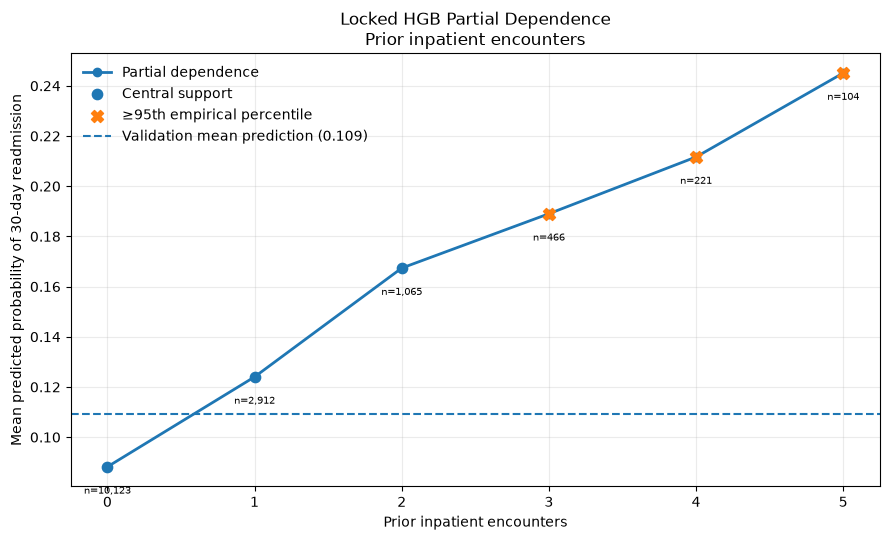

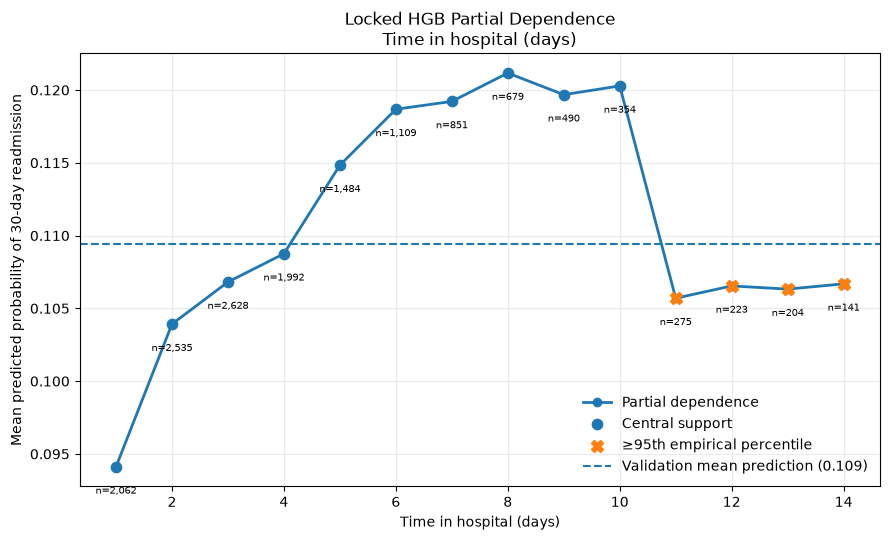

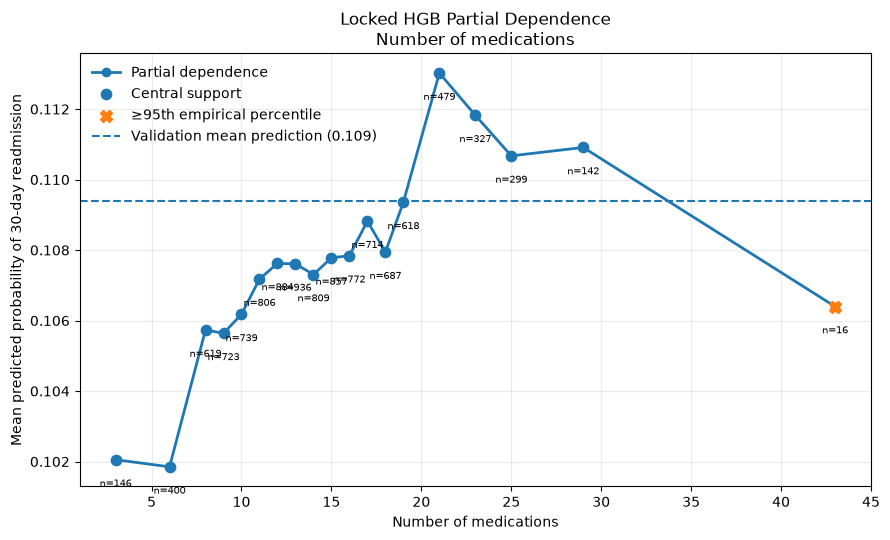

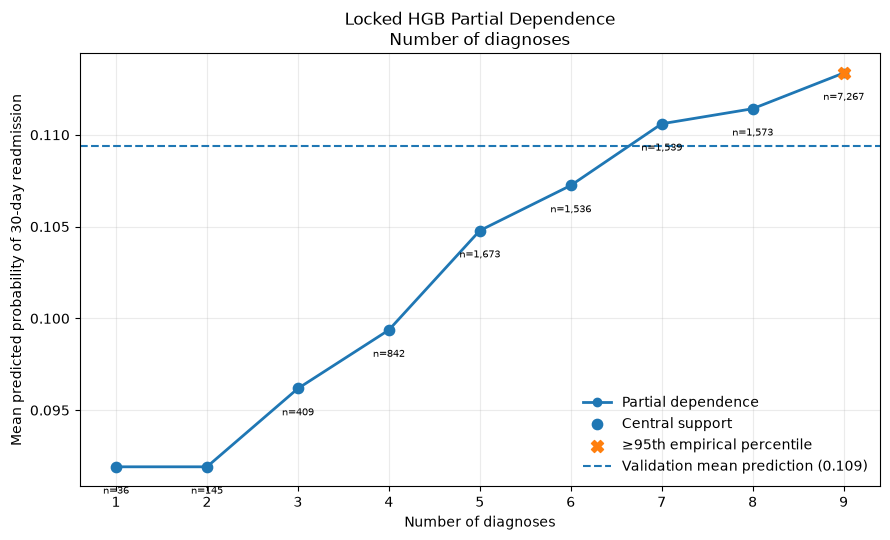

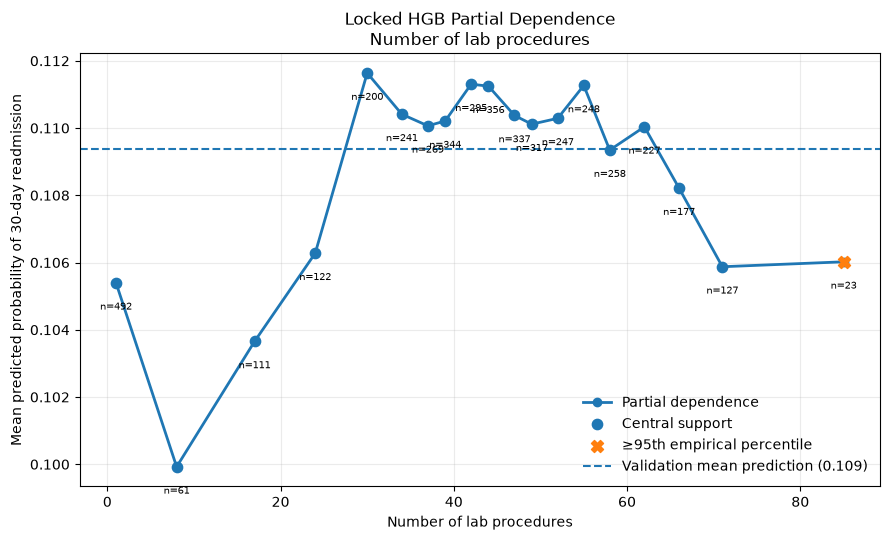

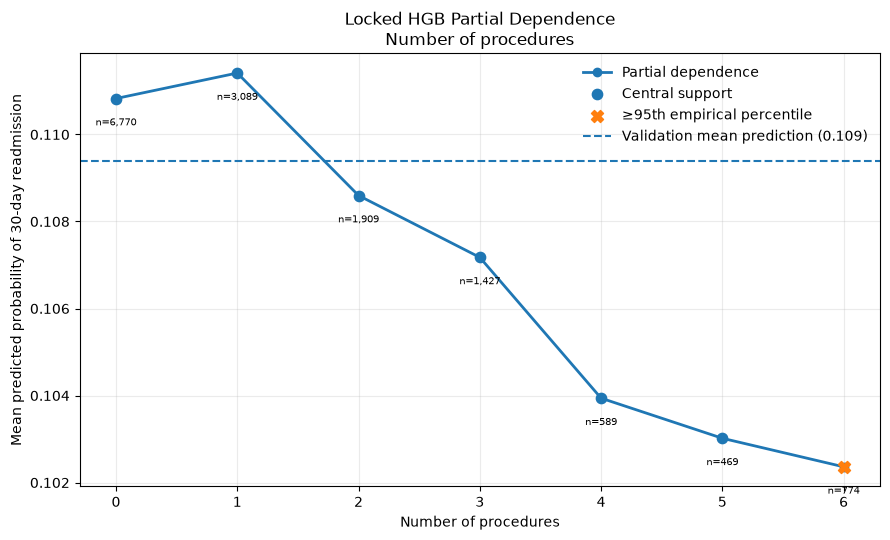

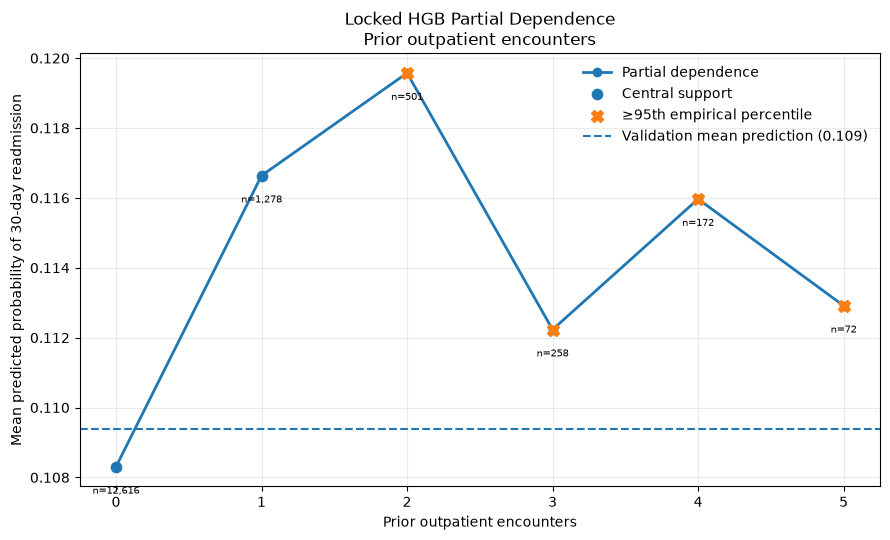

PDP VISUALIZATION ARTIFACT AUDIT
Figures created:              7

✓ reports\figures\notebook08\pdp_number_inpatient.png
✓ reports\figures\notebook08\pdp_time_in_hospital.png
✓ reports\figures\notebook08\pdp_num_medications.png
✓ reports\figures\notebook08\pdp_number_diagnoses.png
✓ reports\figures\notebook08\pdp_num_lab_procedures.png
✓ reports\figures\notebook08\pdp_num_procedures.png
✓ reports\figures\notebook08\pdp_number_outpatient.png

✓ One figure saved per directionality feature.
✓ Baseline model prediction shown as reference.
✓ Tail-support points distinguished from central support.
✓ Observed validation counts retained on plots.
✓ No model fitting performed.
✓ Held-out test dataset remains unloaded.


In [23]:
# M8E.8 — Save one coherent PDP figure per source feature

from pathlib import Path
import matplotlib.pyplot as plt

INTERPRETABILITY_FIGURE_DIR = Path("reports") / "figures" / "notebook08"

INTERPRETABILITY_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


saved_pdp_figures = []


# ----------------------------------------------------------
# Friendly labels
# ----------------------------------------------------------

PDP_FEATURE_LABELS = {
    "number_inpatient": "Prior inpatient encounters",
    "time_in_hospital": "Time in hospital (days)",
    "num_medications": "Number of medications",
    "number_diagnoses": "Number of diagnoses",
    "num_lab_procedures": "Number of lab procedures",
    "num_procedures": "Number of procedures",
    "number_outpatient": "Prior outpatient encounters",
}


# ----------------------------------------------------------
# Generate one figure per feature
# ----------------------------------------------------------

for feature in DIRECT_RAW_DIRECTIONALITY_FEATURES:

    feature_results = (
        pdp_results_df.loc[pdp_results_df["source_feature"] == feature]
        .sort_values("grid_value")
        .copy()
    )

    central_results = feature_results.loc[~feature_results["tail_point"]]

    tail_results = feature_results.loc[feature_results["tail_point"]]

    fig, ax = plt.subplots(figsize=(9, 5.5))

    # ------------------------------------------------------
    # Main PDP curve
    # ------------------------------------------------------

    ax.plot(
        feature_results["grid_value"],
        feature_results["mean_predicted_probability"],
        marker="o",
        linewidth=2,
        label="Partial dependence",
    )

    # ------------------------------------------------------
    # Central-support points
    # ------------------------------------------------------

    ax.scatter(
        central_results["grid_value"],
        central_results["mean_predicted_probability"],
        s=55,
        label="Central support",
        zorder=3,
    )

    # ------------------------------------------------------
    # Tail points
    # ------------------------------------------------------

    if not tail_results.empty:

        ax.scatter(
            tail_results["grid_value"],
            tail_results["mean_predicted_probability"],
            s=75,
            marker="X",
            label="≥95th empirical percentile",
            zorder=4,
        )

    # ------------------------------------------------------
    # Baseline mean prediction
    # ------------------------------------------------------

    ax.axhline(
        PDP_BASELINE_MEAN_PROBABILITY,
        linestyle="--",
        linewidth=1.5,
        label=("Validation mean prediction " f"({PDP_BASELINE_MEAN_PROBABILITY:.3f})"),
    )

    # ------------------------------------------------------
    # Labels
    # ------------------------------------------------------

    ax.set_title("Locked HGB Partial Dependence\n" f"{PDP_FEATURE_LABELS[feature]}")

    ax.set_xlabel(PDP_FEATURE_LABELS[feature])

    ax.set_ylabel("Mean predicted probability " "of 30-day readmission")

    ax.grid(alpha=0.25)

    ax.legend(frameon=False)

    # ------------------------------------------------------
    # Support counts under points
    # ------------------------------------------------------

    probability_span = (
        feature_results["mean_predicted_probability"].max()
        - feature_results["mean_predicted_probability"].min()
    )

    annotation_offset = max(
        probability_span * 0.07,
        0.0015,
    )

    for _, row in feature_results.iterrows():

        ax.annotate(
            f"n={int(row['exact_observed_count']):,}",
            (
                row["grid_value"],
                row["mean_predicted_probability"],
            ),
            xytext=(
                0,
                -14,
            ),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=7,
        )

    # ------------------------------------------------------
    # Save
    # ------------------------------------------------------

    output_path = INTERPRETABILITY_FIGURE_DIR / f"pdp_{feature}.png"

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    plt.close(fig)

    saved_pdp_figures.append(output_path)


# ----------------------------------------------------------
# Audit
# ----------------------------------------------------------

print("PDP VISUALIZATION ARTIFACT AUDIT")

print("=" * 90)

print(f"Figures created:              " f"{len(saved_pdp_figures)}")

print()


for path in saved_pdp_figures:

    print(f"✓ {path}")


assert len(saved_pdp_figures) == len(DIRECT_RAW_DIRECTIONALITY_FEATURES)


assert all(path.exists() for path in saved_pdp_figures)


print()

print("✓ One figure saved per directionality feature.")

print("✓ Baseline model prediction shown as reference.")

print("✓ Tail-support points distinguished from central support.")

print("✓ Observed validation counts retained on plots.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

## M8F — Categorical Model Behavior

Numeric partial dependence captures only one portion of the locked model's learned
prediction function. Several important predictors are categorical, including diagnosis
families, encounter context, demographic variables, and treatment-related attributes.

Categorical interpretation requires additional care because categories are not ordered
numeric quantities and may differ substantially in empirical support.

This section therefore begins by auditing categorical predictors against their
permutation importance and validation support before computing category-level model
profiles.

Category-level predictions will describe the behavior of the fitted model under
model-input perturbations. They will not be interpreted as causal effects, treatment
effects, or evidence that membership in a demographic or clinical category causes
readmission.

In [24]:
# M8F.1 — Rank categorical predictors and audit validation support

# ----------------------------------------------------------
# Categorical permutation ranking
# ----------------------------------------------------------

categorical_importance_df = permutation_importance_df.loc[
    permutation_importance_df["source_type"] == "categorical"
].copy()


categorical_importance_df = categorical_importance_df.sort_values(
    [
        "roc_auc_importance_mean",
        "ap_importance_mean",
    ],
    ascending=False,
).reset_index(drop=True)


categorical_importance_df["categorical_importance_rank"] = np.arange(
    1,
    len(categorical_importance_df) + 1,
)


# ----------------------------------------------------------
# Validation category support
# ----------------------------------------------------------

categorical_support_records = []


for feature in FINAL_CATEGORICAL_FEATURES:

    feature_values = X_validation_final[feature].astype("string").fillna("Missing")

    counts = feature_values.value_counts(dropna=False)

    for category_value, count in counts.items():

        categorical_support_records.append(
            {
                "source_feature": feature,
                "category": str(category_value),
                "validation_count": int(count),
                "validation_fraction": float(count / len(X_validation_final)),
            }
        )


categorical_support_df = pd.DataFrame(categorical_support_records)


# ----------------------------------------------------------
# Feature-level support summary
# ----------------------------------------------------------

categorical_support_summary_df = categorical_support_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    validation_categories=(
        "category",
        "nunique",
    ),
    minimum_category_count=(
        "validation_count",
        "min",
    ),
    maximum_category_count=(
        "validation_count",
        "max",
    ),
    smallest_category_fraction=(
        "validation_fraction",
        "min",
    ),
    largest_category_fraction=(
        "validation_fraction",
        "max",
    ),
)


# ----------------------------------------------------------
# Combine support + permutation evidence
# ----------------------------------------------------------

categorical_audit_df = categorical_importance_df.merge(
    categorical_support_summary_df,
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert len(categorical_audit_df) == len(FINAL_CATEGORICAL_FEATURES)


assert categorical_audit_df["source_feature"].nunique() == len(
    FINAL_CATEGORICAL_FEATURES
)


assert categorical_audit_df["validation_categories"].notna().all()


# ----------------------------------------------------------
# Report top categorical predictors
# ----------------------------------------------------------

CATEGORICAL_AUDIT_TOP_N = 15


print("CATEGORICAL INTERPRETABILITY AUDIT")

print("=" * 135)

print(f"Categorical predictors:       " f"{len(FINAL_CATEGORICAL_FEATURES)}")

print(f"Validation encounters:        " f"{len(X_validation_final):,}")

print()

print(
    f"TOP {CATEGORICAL_AUDIT_TOP_N} "
    "CATEGORICAL PREDICTORS BY ROC-AUC PERMUTATION IMPORTANCE"
)

print("-" * 135)


print(
    categorical_audit_df[
        [
            "categorical_importance_rank",
            "source_feature",
            "feature_family",
            "feature_origin",
            "roc_auc_importance_mean",
            "roc_auc_importance_std",
            "ap_importance_mean",
            "validation_categories",
            "minimum_category_count",
            "maximum_category_count",
            "smallest_category_fraction",
            "largest_category_fraction",
        ]
    ]
    .head(CATEGORICAL_AUDIT_TOP_N)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ----------------------------------------------------------
# Detailed category support for strongest predictors
# ----------------------------------------------------------

TOP_CATEGORICAL_SUPPORT_FEATURES = (
    categorical_audit_df["source_feature"].head(8).tolist()
)


print()

print("CATEGORY SUPPORT — TOP 8 CATEGORICAL PREDICTORS")

print("=" * 100)


for feature in TOP_CATEGORICAL_SUPPORT_FEATURES:

    feature_support = (
        categorical_support_df.loc[categorical_support_df["source_feature"] == feature]
        .sort_values(
            "validation_count",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    print()

    print(feature)

    print("-" * 75)

    print(
        feature_support.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}",
        )
    )


print()

print("✓ Categorical predictors ranked using completed " "permutation analysis.")

print("✓ Validation category support audited before " "category-level perturbation.")

print("✓ No categorical effect profiles computed yet.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

CATEGORICAL INTERPRETABILITY AUDIT
Categorical predictors:       35
Validation encounters:        15,027

TOP 15 CATEGORICAL PREDICTORS BY ROC-AUC PERMUTATION IMPORTANCE
---------------------------------------------------------------------------------------------------------------------------------------
 categorical_importance_rank               source_feature            feature_family feature_origin  roc_auc_importance_mean  roc_auc_importance_std  ap_importance_mean  validation_categories  minimum_category_count  maximum_category_count  smallest_category_fraction  largest_category_fraction
                           1                diag_1_family          Diagnosis family     engineered                 0.011278                0.001628            0.009883                     19                       1                    4472                    0.000067                   0.297598
                           2                          age              Demographics         source        

### M8F.2 — Categorical Profiling Scope and Support Contract

Categorical model-behavior profiles are restricted before inspecting category-level
prediction estimates.

Primary profiling focuses on categorical predictors that combine permutation evidence
with substantive interpretability:

- primary diagnosis family;
- age band;
- medical specialty;
- secondary diagnosis family;
- admission source;
- diabetes-medication indicator.

For general categorical predictors, a category requires at least 100 validation
encounters to enter the primary interpretation profile. This threshold matches the
rare-category support rule used during feature engineering and reduces emphasis on
extremely sparse categories.

Age is treated separately because it is also a prespecified responsible-evaluation
dimension from Notebook 07. All observed age bands are retained, but bands with fewer
than 100 validation encounters are explicitly flagged as low-support.

`Unknown` is retained when it is a model input because missingness itself may have been
used predictively. It is interpreted only as an unknown/missing-information category,
not as a coherent clinical or demographic group.

The support contract is fixed before category-level prediction profiles are computed.

In [25]:
# M8F.2 — Lock categorical profiling scope and eligible categories

PRIMARY_CATEGORICAL_PROFILE_FEATURES = [
    "diag_1_family",
    "age",
    "medical_specialty",
    "diag_2_family",
    "admission_source_description",
    "diabetesMed",
]

CATEGORICAL_PRIMARY_MIN_COUNT = 100
AGE_FEATURE = "age"


# ----------------------------------------------------------
# Contract checks
# ----------------------------------------------------------

assert set(PRIMARY_CATEGORICAL_PROFILE_FEATURES).issubset(
    set(FINAL_CATEGORICAL_FEATURES)
)

assert len(PRIMARY_CATEGORICAL_PROFILE_FEATURES) == len(
    set(PRIMARY_CATEGORICAL_PROFILE_FEATURES)
)


# ----------------------------------------------------------
# Build eligibility table
# ----------------------------------------------------------

categorical_profile_support_df = categorical_support_df.loc[
    categorical_support_df["source_feature"].isin(PRIMARY_CATEGORICAL_PROFILE_FEATURES)
].copy()


categorical_profile_support_df["meets_standard_support"] = (
    categorical_profile_support_df["validation_count"] >= CATEGORICAL_PRIMARY_MIN_COUNT
)


categorical_profile_support_df["primary_profile_eligible"] = (
    categorical_profile_support_df["meets_standard_support"]
)


# Preserve all age bands, but flag weak support.

age_mask = categorical_profile_support_df["source_feature"] == AGE_FEATURE


categorical_profile_support_df.loc[
    age_mask,
    "primary_profile_eligible",
] = True


categorical_profile_support_df["low_support_flag"] = ~categorical_profile_support_df[
    "meets_standard_support"
]


categorical_profile_support_df["unknown_category_flag"] = (
    categorical_profile_support_df["category"]
    .str.strip()
    .str.lower()
    .isin(
        [
            "unknown",
            "missing",
            "not available",
            "not mapped",
            "other / unclassified",
        ]
    )
)


# ----------------------------------------------------------
# Primary categories
# ----------------------------------------------------------

primary_categorical_grid_df = (
    categorical_profile_support_df.loc[
        categorical_profile_support_df["primary_profile_eligible"]
    ]
    .copy()
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

categorical_scope_summary_df = categorical_profile_support_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    observed_categories=(
        "category",
        "nunique",
    ),
    primary_categories=(
        "primary_profile_eligible",
        "sum",
    ),
    low_support_categories=(
        "low_support_flag",
        "sum",
    ),
    unknown_categories=(
        "unknown_category_flag",
        "sum",
    ),
    validation_count=(
        "validation_count",
        "sum",
    ),
)


# Preserve declared feature order.

categorical_profile_order = {
    feature: index for index, feature in enumerate(PRIMARY_CATEGORICAL_PROFILE_FEATURES)
}


categorical_scope_summary_df["_order"] = categorical_scope_summary_df[
    "source_feature"
].map(categorical_profile_order)


categorical_scope_summary_df = (
    categorical_scope_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert (
    categorical_scope_summary_df["validation_count"] == len(X_validation_final)
).all()


assert (primary_categorical_grid_df["primary_profile_eligible"]).all()


non_age_primary = primary_categorical_grid_df.loc[
    primary_categorical_grid_df["source_feature"] != AGE_FEATURE
]


assert (non_age_primary["validation_count"] >= CATEGORICAL_PRIMARY_MIN_COUNT).all()


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("LOCKED CATEGORICAL PROFILING SCOPE")

print("=" * 110)

print(categorical_scope_summary_df.to_string(index=False))


print()

print("PRIMARY CATEGORY GRIDS")

print("=" * 110)


for feature in PRIMARY_CATEGORICAL_PROFILE_FEATURES:

    feature_grid = primary_categorical_grid_df.loc[
        primary_categorical_grid_df["source_feature"] == feature,
        [
            "category",
            "validation_count",
            "validation_fraction",
            "low_support_flag",
            "unknown_category_flag",
        ],
    ].sort_values(
        "validation_count",
        ascending=False,
    )

    print()

    print(feature)

    print("-" * 80)

    print(
        feature_grid.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}",
        )
    )


print()

print("✓ Categorical profiling features locked before effect estimation.")

print(
    "✓ Standard primary-category minimum support = "
    f"{CATEGORICAL_PRIMARY_MIN_COUNT} validation encounters."
)

print("✓ All age bands retained under the prespecified fairness exception.")

print("✓ Low-support and unknown-information categories explicitly flagged.")

print("✓ No category-level predictions computed.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

LOCKED CATEGORICAL PROFILING SCOPE
              source_feature  observed_categories  primary_categories  low_support_categories  unknown_categories  validation_count
               diag_1_family                   19                  16                       3                   1             15027
                         age                   10                  10                       1                   0             15027
           medical_specialty                   57                  14                      43                   1             15027
               diag_2_family                   19                  16                       3                   1             15027
admission_source_description                   14                   7                       7                   3             15027
                 diabetesMed                    2                   2                       0                   0             15027

PRIMARY CATEGORY GRIDS

diag_1_family
--

### M8F.3 — Training-Registry Compatibility and Perturbation Routes

The validation-support filter does not by itself establish that a category enters the
locked model as a distinct level.

Categorical values are passed through the rare-category registry learned from the
training partition. Categories not retained by that registry are mapped to `Other`
before the persisted preprocessor is applied.

The locked categorical profiling grid is therefore audited against the persisted
training-derived category registry before any model-effect estimates are computed.

Two perturbation routes are distinguished:

1. **Raw-contract categorical profiles** — age, medical specialty, admission source,
   and diabetes-medication status exist directly in the 44-feature raw predictor
   contract. Their values can be modified before deterministic feature engineering,
   after which the complete locked pipeline is rerun.

2. **Engineered model-input profiles** — primary and secondary diagnosis families are
   derived from ICD-9 diagnosis codes. Assigning a diagnosis-family label does not
   correspond to a unique raw ICD-9 code. These predictors are therefore perturbed
   only in the final 48-feature model-input representation.

Diagnosis-family profiles describe dependence of the fitted model on those engineered
inputs. They are not interpreted as simulations of changing a patient's diagnosis.

In [26]:
# M8F.3 — Audit training-registry compatibility and perturbation routes

RAW_CATEGORICAL_PROFILE_FEATURES = [
    "age",
    "medical_specialty",
    "admission_source_description",
    "diabetesMed",
]

ENGINEERED_CATEGORICAL_PROFILE_FEATURES = [
    "diag_1_family",
    "diag_2_family",
]


# ----------------------------------------------------------
# Route contract
# ----------------------------------------------------------

assert set(
    RAW_CATEGORICAL_PROFILE_FEATURES + ENGINEERED_CATEGORICAL_PROFILE_FEATURES
) == set(PRIMARY_CATEGORICAL_PROFILE_FEATURES)


assert set(RAW_CATEGORICAL_PROFILE_FEATURES).issubset(
    set(feature_registry["model_features"])
)


assert not set(ENGINEERED_CATEGORICAL_PROFILE_FEATURES).intersection(
    set(feature_registry["model_features"])
)


assert set(ENGINEERED_CATEGORICAL_PROFILE_FEATURES).issubset(
    set(PERSISTED_MODEL_FEATURE_ORDER)
)


# ----------------------------------------------------------
# Registry compatibility audit
# ----------------------------------------------------------

registry_audit_records = []


for _, row in primary_categorical_grid_df.iterrows():

    feature = row["source_feature"]

    category = str(row["category"])

    retained_categories = set(
        str(value) for value in persisted_category_registry[feature]
    )

    retained_by_training_registry = category in retained_categories

    model_category = category if retained_by_training_registry else "Other"

    if feature in (RAW_CATEGORICAL_PROFILE_FEATURES):

        perturbation_route = "raw_44_feature_contract"

    elif feature in (ENGINEERED_CATEGORICAL_PROFILE_FEATURES):

        perturbation_route = "engineered_48_feature_input"

    else:

        raise ValueError(f"Unassigned categorical perturbation route: " f"{feature}")

    registry_audit_records.append(
        {
            "source_feature": feature,
            "category": category,
            "validation_count": int(row["validation_count"]),
            "validation_fraction": float(row["validation_fraction"]),
            "low_support_flag": bool(row["low_support_flag"]),
            "unknown_category_flag": bool(row["unknown_category_flag"]),
            "retained_by_training_registry": retained_by_training_registry,
            "model_category_after_registry": model_category,
            "perturbation_route": perturbation_route,
        }
    )


categorical_registry_audit_df = pd.DataFrame(registry_audit_records)


# ----------------------------------------------------------
# Determine whether any distinct requested categories
# collapse to the same model input through "Other"
# ----------------------------------------------------------

registry_collision_df = categorical_registry_audit_df.groupby(
    [
        "source_feature",
        "model_category_after_registry",
    ],
    as_index=False,
).agg(
    requested_categories=(
        "category",
        "nunique",
    ),
    validation_count_sum=(
        "validation_count",
        "sum",
    ),
)


registry_collision_df["category_collision"] = (
    registry_collision_df["requested_categories"] > 1
)


# ----------------------------------------------------------
# Feature-level summary
# ----------------------------------------------------------

categorical_registry_summary_df = categorical_registry_audit_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    requested_primary_categories=(
        "category",
        "nunique",
    ),
    retained_primary_categories=(
        "retained_by_training_registry",
        "sum",
    ),
    mapped_to_other=(
        "retained_by_training_registry",
        lambda x: int((~x).sum()),
    ),
    perturbation_route=(
        "perturbation_route",
        "first",
    ),
)


categorical_registry_summary_df["_order"] = categorical_registry_summary_df[
    "source_feature"
].map(categorical_profile_order)


categorical_registry_summary_df = (
    categorical_registry_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert categorical_registry_audit_df["source_feature"].nunique() == len(
    PRIMARY_CATEGORICAL_PROFILE_FEATURES
)


assert len(categorical_registry_audit_df) == len(primary_categorical_grid_df)


assert categorical_registry_audit_df["perturbation_route"].notna().all()


# Every model category resulting from a retained category
# should be the same literal category.

retained_rows = categorical_registry_audit_df.loc[
    categorical_registry_audit_df["retained_by_training_registry"]
]


assert (
    retained_rows["category"] == retained_rows["model_category_after_registry"]
).all()


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("TRAINING-REGISTRY COMPATIBILITY " "AND PERTURBATION ROUTE AUDIT")

print("=" * 125)

print(categorical_registry_summary_df.to_string(index=False))


print()

print("CATEGORY-LEVEL REGISTRY AUDIT")

print("=" * 125)


for feature in PRIMARY_CATEGORICAL_PROFILE_FEATURES:

    feature_audit = categorical_registry_audit_df.loc[
        categorical_registry_audit_df["source_feature"] == feature,
        [
            "category",
            "validation_count",
            "low_support_flag",
            "unknown_category_flag",
            "retained_by_training_registry",
            "model_category_after_registry",
            "perturbation_route",
        ],
    ].sort_values(
        "validation_count",
        ascending=False,
    )

    print()

    print(feature)

    print("-" * 100)

    print(feature_audit.to_string(index=False))


print()

print("REGISTRY COLLISION CHECK")

print("-" * 100)


collision_rows = registry_collision_df.loc[registry_collision_df["category_collision"]]


if collision_rows.empty:

    print("No requested primary categories collapse " "onto the same model category.")

else:

    print(collision_rows.to_string(index=False))


print()

print("✓ Raw and engineered categorical perturbation routes locked.")

print("✓ Primary categories audited against the training-derived registry.")

print("✓ Categories mapped to Other identified before effect estimation.")

print("✓ Registry collisions checked.")

print("✓ No category-level predictions computed.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

TRAINING-REGISTRY COMPATIBILITY AND PERTURBATION ROUTE AUDIT
              source_feature  requested_primary_categories  retained_primary_categories  mapped_to_other          perturbation_route
               diag_1_family                            16                           16                0 engineered_48_feature_input
                         age                            10                           10                0     raw_44_feature_contract
           medical_specialty                            14                           14                0     raw_44_feature_contract
               diag_2_family                            16                           16                0 engineered_48_feature_input
admission_source_description                             7                            7                0     raw_44_feature_contract
                 diabetesMed                             2                            2                0     raw_44_feature_contract

CATEGOR

### M8F.4 — Categorical Model-Behavior Profiles

Category-level model behavior is estimated using the perturbation routes locked in the
preceding audit.

For raw categorical predictors, each validation encounter is assigned a candidate
category in the original 44-feature predictor representation. Deterministic feature
engineering is then rerun and predictions are generated through the unchanged persisted
pipeline.

For engineered diagnosis-family predictors, the corresponding diagnosis-family input is
assigned directly in the final 48-feature model representation because no unique raw
ICD-9 code corresponds to a diagnosis-family label.

At each category, the reported profile is the mean predicted probability across all
validation encounters under that model-input assignment. Results are also expressed
relative to the locked model's mean validation prediction.

These estimates characterize dependence of the fitted prediction function on categorical
inputs. They do not estimate causal effects, treatment effects, or the outcome that would
result from changing a patient's demographic, clinical, or administrative category.

In [27]:
# M8F.4 — Compute categorical model-behavior profiles

import time

CATEGORICAL_BASELINE_MEAN_PROBABILITY = float(
    np.mean(raw_wrapper_validation_probability)
)


categorical_profile_records = []

total_category_evaluations = len(categorical_registry_audit_df)

completed_category_evaluations = 0

categorical_start_time = time.perf_counter()


print("RUNNING CATEGORICAL MODEL-BEHAVIOR PROFILES")

print("=" * 100)

print(f"Validation encounters:        " f"{len(X_validation_raw):,}")

print(f"Profile features:             " f"{len(PRIMARY_CATEGORICAL_PROFILE_FEATURES)}")

print(f"Category evaluations:         " f"{total_category_evaluations}")

print(f"Baseline mean probability:    " f"{CATEGORICAL_BASELINE_MEAN_PROBABILITY:.6f}")

print()


# ----------------------------------------------------------
# Evaluate each locked categorical feature
# ----------------------------------------------------------

for feature_number, feature in enumerate(
    PRIMARY_CATEGORICAL_PROFILE_FEATURES,
    start=1,
):

    feature_grid = (
        categorical_registry_audit_df.loc[
            categorical_registry_audit_df["source_feature"] == feature
        ]
        .sort_values(
            "validation_count",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    feature_start_time = time.perf_counter()

    for _, category_row in feature_grid.iterrows():

        category = str(category_row["category"])

        perturbation_route = category_row["perturbation_route"]

        # --------------------------------------------------
        # Route 1:
        # raw 44-feature categorical perturbation
        # --------------------------------------------------

        if perturbation_route == "raw_44_feature_contract":

            X_category_raw = X_validation_raw.copy()

            X_category_raw[feature] = category

            category_probability = predict_persisted_hgb_from_raw_features(
                X_category_raw
            )

        # --------------------------------------------------
        # Route 2:
        # engineered 48-feature model-input perturbation
        # --------------------------------------------------

        elif perturbation_route == "engineered_48_feature_input":

            X_category_model = X_validation_final.copy()

            X_category_model[feature] = category

            category_probability = predict_persisted_hgb_from_model_features(
                X_category_model
            )

        else:

            raise ValueError("Unknown perturbation route: " f"{perturbation_route}")

        # --------------------------------------------------
        # Prediction integrity
        # --------------------------------------------------

        assert len(category_probability) == len(X_validation_raw)

        assert np.isfinite(category_probability).all()

        assert ((category_probability >= 0) & (category_probability <= 1)).all()

        # --------------------------------------------------
        # Profile summaries
        # --------------------------------------------------

        mean_probability = float(np.mean(category_probability))

        median_probability = float(np.median(category_probability))

        probability_q10 = float(
            np.quantile(
                category_probability,
                0.10,
            )
        )

        probability_q90 = float(
            np.quantile(
                category_probability,
                0.90,
            )
        )

        mean_probability_delta = (
            mean_probability - CATEGORICAL_BASELINE_MEAN_PROBABILITY
        )

        categorical_profile_records.append(
            {
                "source_feature": feature,
                "category": category,
                "mean_predicted_probability": mean_probability,
                "mean_probability_delta": mean_probability_delta,
                "median_predicted_probability": median_probability,
                "prediction_q10": probability_q10,
                "prediction_q90": probability_q90,
                "validation_count": int(category_row["validation_count"]),
                "validation_fraction": float(category_row["validation_fraction"]),
                "low_support_flag": bool(category_row["low_support_flag"]),
                "unknown_category_flag": bool(category_row["unknown_category_flag"]),
                "perturbation_route": perturbation_route,
            }
        )

        completed_category_evaluations += 1

    feature_elapsed = time.perf_counter() - feature_start_time

    print(
        f"[{feature_number:02d}/"
        f"{len(PRIMARY_CATEGORICAL_PROFILE_FEATURES):02d}] "
        f"{feature:<30} "
        f"{len(feature_grid):>2} categories | "
        f"{feature_elapsed:>7.2f}s"
    )


# ----------------------------------------------------------
# Results
# ----------------------------------------------------------

categorical_profile_results_df = pd.DataFrame(categorical_profile_records)


categorical_elapsed_seconds = time.perf_counter() - categorical_start_time


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert completed_category_evaluations == total_category_evaluations


assert len(categorical_profile_results_df) == total_category_evaluations


assert categorical_profile_results_df["source_feature"].nunique() == len(
    PRIMARY_CATEGORICAL_PROFILE_FEATURES
)


assert np.isfinite(
    categorical_profile_results_df[
        [
            "mean_predicted_probability",
            "mean_probability_delta",
            "median_predicted_probability",
            "prediction_q10",
            "prediction_q90",
        ]
    ].to_numpy()
).all()


# ----------------------------------------------------------
# Feature-level profile ranges
# ----------------------------------------------------------

categorical_profile_summary_df = categorical_profile_results_df.groupby(
    "source_feature",
    as_index=False,
).agg(
    categories=(
        "category",
        "count",
    ),
    minimum_profile_probability=(
        "mean_predicted_probability",
        "min",
    ),
    maximum_profile_probability=(
        "mean_predicted_probability",
        "max",
    ),
    minimum_delta=(
        "mean_probability_delta",
        "min",
    ),
    maximum_delta=(
        "mean_probability_delta",
        "max",
    ),
)


categorical_profile_summary_df["profile_probability_range"] = (
    categorical_profile_summary_df["maximum_profile_probability"]
    - categorical_profile_summary_df["minimum_profile_probability"]
)


# Attach permutation evidence.

categorical_profile_summary_df = categorical_profile_summary_df.merge(
    categorical_importance_df[
        [
            "source_feature",
            "roc_auc_importance_mean",
            "ap_importance_mean",
        ]
    ],
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# Preserve locked order.

categorical_profile_summary_df["_order"] = categorical_profile_summary_df[
    "source_feature"
].map(categorical_profile_order)


categorical_profile_summary_df = (
    categorical_profile_summary_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print()

print("CATEGORICAL MODEL-BEHAVIOR PROFILES COMPLETE")

print("=" * 120)

print(f"Category evaluations completed: " f"{completed_category_evaluations}")

print(f"Elapsed time:                   " f"{categorical_elapsed_seconds:.2f} seconds")

print(
    f"Baseline mean probability:      " f"{CATEGORICAL_BASELINE_MEAN_PROBABILITY:.6f}"
)

print()

print("FEATURE-LEVEL PROFILE RANGE SUMMARY")

print("-" * 120)

print(
    categorical_profile_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("DETAILED CATEGORY PROFILES")

print("=" * 120)


for feature in PRIMARY_CATEGORICAL_PROFILE_FEATURES:

    feature_results = categorical_profile_results_df.loc[
        categorical_profile_results_df["source_feature"] == feature,
        [
            "category",
            "mean_predicted_probability",
            "mean_probability_delta",
            "validation_count",
            "validation_fraction",
            "low_support_flag",
            "unknown_category_flag",
            "perturbation_route",
        ],
    ].sort_values(
        "mean_predicted_probability",
        ascending=False,
    )

    print()

    print(feature)

    print("-" * 105)

    print(
        feature_results.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}",
        )
    )


print()

print(
    "✓ Raw categorical predictors evaluated through "
    "the coherent 44-feature pipeline."
)

print(
    "✓ Diagnosis-family predictors evaluated only at "
    "their engineered 48-feature model-input level."
)

print("✓ Training-derived registry and persisted " "preprocessing remained unchanged.")

print("✓ Support and unknown-category flags retained.")

print("✓ Category profiles represent model dependence, " "not causal effects.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

RUNNING CATEGORICAL MODEL-BEHAVIOR PROFILES
Validation encounters:        15,027
Profile features:             6
Category evaluations:         65
Baseline mean probability:    0.109387

[01/06] diag_1_family                  16 categories |   13.27s
[02/06] age                            10 categories |    8.33s
[03/06] medical_specialty              14 categories |   11.65s
[04/06] diag_2_family                  16 categories |   12.33s
[05/06] admission_source_description    7 categories |    6.12s
[06/06] diabetesMed                     2 categories |    1.72s

CATEGORICAL MODEL-BEHAVIOR PROFILES COMPLETE
Category evaluations completed: 65
Elapsed time:                   53.44 seconds
Baseline mean probability:      0.109387

FEATURE-LEVEL PROFILE RANGE SUMMARY
------------------------------------------------------------------------------------------------------------------------
              source_feature  categories  minimum_profile_probability  maximum_profile_probability  mini

### M8F.5 — Support-Aware Categorical Profile Diagnostics

Categorical profile ranges can be disproportionately influenced by categories with
relatively small empirical support.

To distinguish broad model behavior from sparse-category extremes, each categorical
profile is summarized at multiple validation-support thresholds:

- the complete prespecified profile;
- categories represented by at least 100 validation encounters;
- categories represented by at least 500 validation encounters.

The 100-encounter threshold corresponds to the previously declared primary categorical
support rule. The 500-encounter summary is an additional sensitivity diagnostic rather
than a replacement selection rule.

For each support level, the probability range and its minimum and maximum categories are
reported. This makes it possible to determine whether an apparent model-dependence
pattern persists among comparatively well-represented categories.

These diagnostics describe stability with respect to empirical category support and do
not constitute statistical confidence intervals or causal comparisons.

In [28]:
# M8F.5 — Support-aware categorical profile diagnostics

CATEGORICAL_SUPPORT_THRESHOLDS = [
    0,
    100,
    500,
]


support_diagnostic_records = []


for feature in PRIMARY_CATEGORICAL_PROFILE_FEATURES:

    feature_results = categorical_profile_results_df.loc[
        categorical_profile_results_df["source_feature"] == feature
    ].copy()

    for minimum_support in CATEGORICAL_SUPPORT_THRESHOLDS:

        supported = feature_results.loc[
            feature_results["validation_count"] >= minimum_support
        ].copy()

        if supported.empty:

            continue

        minimum_index = supported["mean_predicted_probability"].idxmin()

        maximum_index = supported["mean_predicted_probability"].idxmax()

        minimum_row = supported.loc[minimum_index]

        maximum_row = supported.loc[maximum_index]

        minimum_probability = float(minimum_row["mean_predicted_probability"])

        maximum_probability = float(maximum_row["mean_predicted_probability"])

        support_diagnostic_records.append(
            {
                "source_feature": feature,
                "minimum_support": minimum_support,
                "categories_retained": len(supported),
                "validation_coverage": float(supported["validation_fraction"].sum()),
                "minimum_category": minimum_row["category"],
                "minimum_probability": minimum_probability,
                "minimum_category_count": int(minimum_row["validation_count"]),
                "maximum_category": maximum_row["category"],
                "maximum_probability": maximum_probability,
                "maximum_category_count": int(maximum_row["validation_count"]),
                "profile_probability_range": (
                    maximum_probability - minimum_probability
                ),
            }
        )


categorical_support_diagnostics_df = pd.DataFrame(support_diagnostic_records)


# ----------------------------------------------------------
# Wide comparison of probability ranges
# ----------------------------------------------------------

categorical_range_sensitivity_df = categorical_support_diagnostics_df.pivot(
    index="source_feature",
    columns="minimum_support",
    values="profile_probability_range",
).reset_index()


categorical_range_sensitivity_df.columns.name = None


categorical_range_sensitivity_df = categorical_range_sensitivity_df.rename(
    columns={
        0: "range_all_profiled",
        100: "range_support_ge_100",
        500: "range_support_ge_500",
    }
)


# Attach permutation evidence.

categorical_range_sensitivity_df = categorical_range_sensitivity_df.merge(
    categorical_importance_df[
        [
            "source_feature",
            "roc_auc_importance_mean",
            "ap_importance_mean",
        ]
    ],
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# Preserve locked order.

categorical_range_sensitivity_df["_order"] = categorical_range_sensitivity_df[
    "source_feature"
].map(categorical_profile_order)


categorical_range_sensitivity_df = (
    categorical_range_sensitivity_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert (categorical_support_diagnostics_df["profile_probability_range"] >= 0).all()


assert (categorical_support_diagnostics_df["validation_coverage"] <= 1 + 1e-12).all()


# Raising the support threshold cannot increase
# the number of retained categories.

for feature in PRIMARY_CATEGORICAL_PROFILE_FEATURES:

    feature_diag = categorical_support_diagnostics_df.loc[
        categorical_support_diagnostics_df["source_feature"] == feature
    ].sort_values("minimum_support")

    retained_counts = feature_diag["categories_retained"].to_numpy()

    assert (np.diff(retained_counts) <= 0).all()


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("SUPPORT-AWARE CATEGORICAL PROFILE DIAGNOSTICS")

print("=" * 145)

print(
    categorical_range_sensitivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("SUPPORT-LEVEL EXTREMA")

print("=" * 145)


for feature in PRIMARY_CATEGORICAL_PROFILE_FEATURES:

    feature_diagnostics = categorical_support_diagnostics_df.loc[
        categorical_support_diagnostics_df["source_feature"] == feature
    ][
        [
            "minimum_support",
            "categories_retained",
            "validation_coverage",
            "minimum_category",
            "minimum_probability",
            "minimum_category_count",
            "maximum_category",
            "maximum_probability",
            "maximum_category_count",
            "profile_probability_range",
        ]
    ]

    print()

    print(feature)

    print("-" * 120)

    print(
        feature_diagnostics.to_string(
            index=False,
            float_format=lambda x: f"{x:.6f}",
        )
    )


print()

print("✓ Complete and support-restricted categorical ranges compared.")

print("✓ Category extrema retain their validation counts.")

print("✓ ≥500-encounter analysis treated as sensitivity diagnostic only.")

print("✓ No categories removed from the locked model or primary results.")

print("✓ No additional model predictions required.")

print("✓ No model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

SUPPORT-AWARE CATEGORICAL PROFILE DIAGNOSTICS
              source_feature  range_all_profiled  range_support_ge_100  range_support_ge_500  roc_auc_importance_mean  ap_importance_mean
               diag_1_family            0.021906              0.021906              0.021906                 0.011278            0.009883
                         age            0.052485              0.023193              0.021008                 0.005400            0.002286
           medical_specialty            0.037175              0.037175              0.021905                 0.004579            0.001359
               diag_2_family            0.034268              0.034268              0.008737                 0.003564            0.005281
admission_source_description            0.014324              0.014324              0.007514                 0.002838            0.002443
                 diabetesMed            0.012462              0.012462              0.012462                 0.002545         

### M8F.6 — Selected Support-Aware Categorical Visualizations

Categorical visualizations are restricted to four prespecified results that provide
complementary interpretability value:

- `diag_1_family` — the strongest categorical permutation predictor and a profile whose
  range remains stable under increasingly strict support thresholds;
- `age` — a responsible-evaluation dimension with substantial model heterogeneity, while
  retaining explicit support warnings for sparse age bands;
- `medical_specialty` — an important encounter-context feature whose profile is partly
  sensitive to category support and includes a large `Unknown` group;
- `diabetesMed` — a compact, well-supported medication-management contrast.

Secondary diagnosis family and admission source remain in the complete tabular results
but are not promoted to primary figures because their apparent profile ranges are more
support-sensitive or comparatively modest.

Figures display model-predicted probabilities under categorical perturbation and the
validation count associated with each category. The vertical reference line is the
locked model's original mean validation prediction.

These are prediction-function visualizations, not causal or clinical effect estimates.

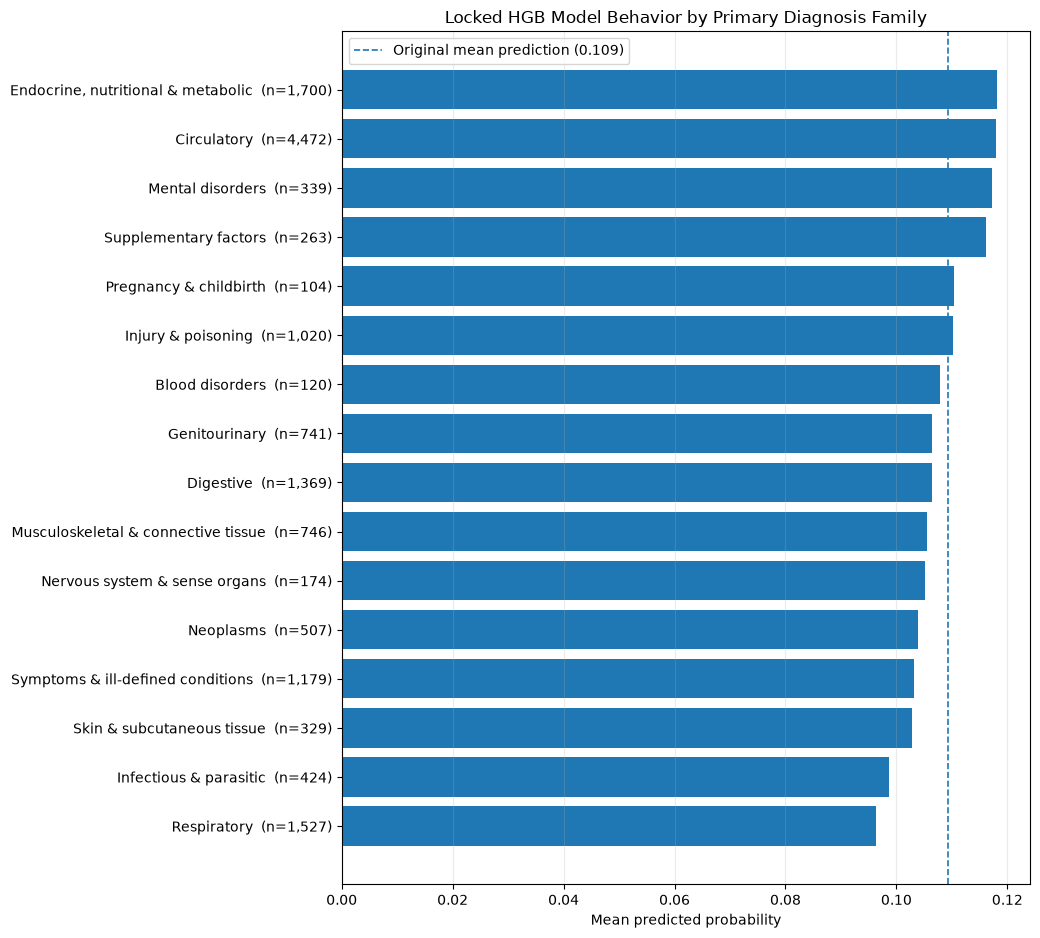

Saved: reports\figures\notebook08\categorical_profile_diag_1_family.png


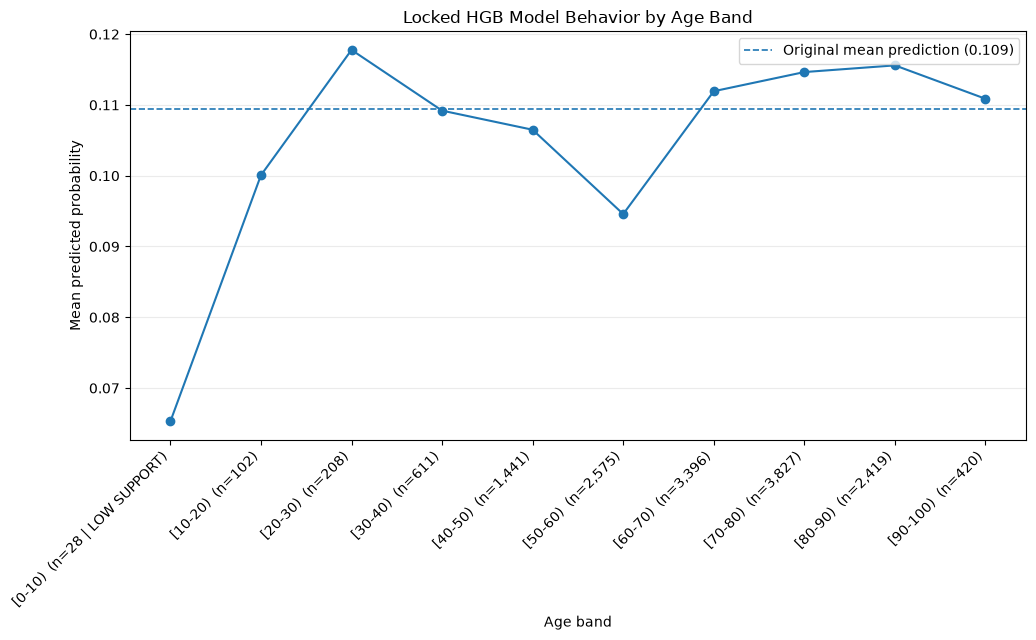

Saved: reports\figures\notebook08\categorical_profile_age.png


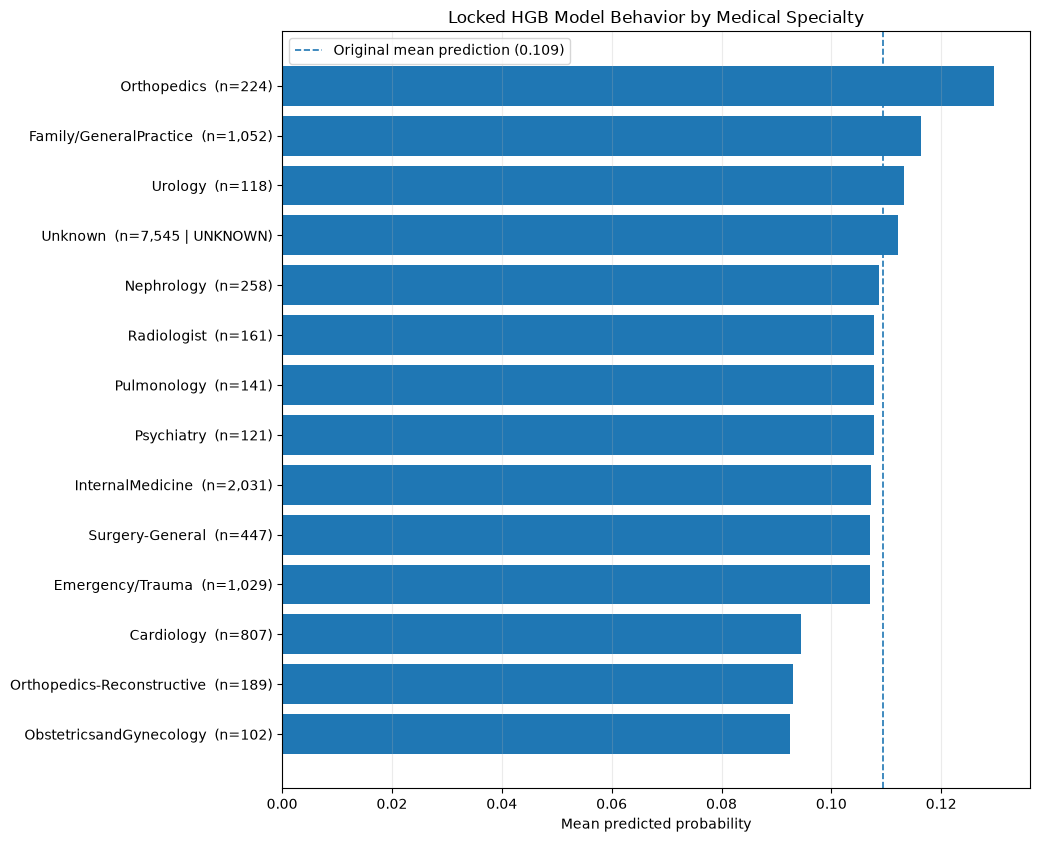

Saved: reports\figures\notebook08\categorical_profile_medical_specialty.png


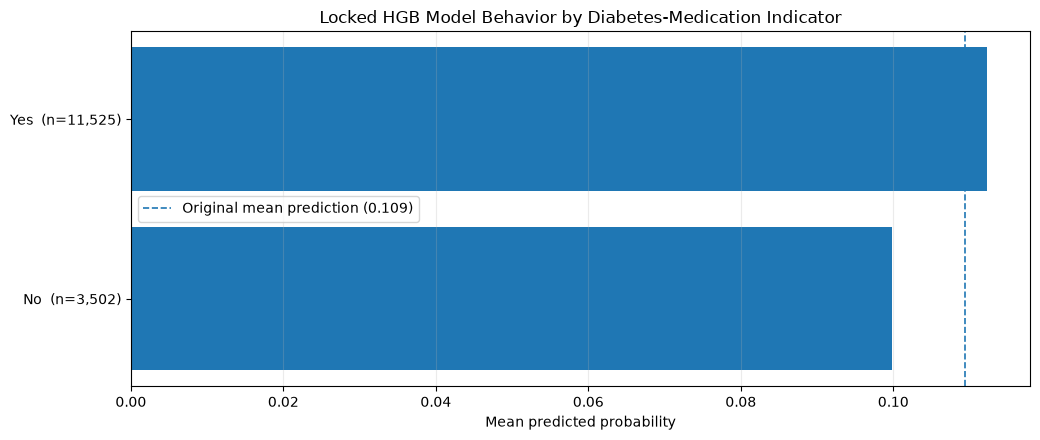

Saved: reports\figures\notebook08\categorical_profile_diabetesMed.png

✓ Four primary categorical figures generated.
✓ Diagnosis-family figure emphasizes the strongest support-stable categorical result.
✓ Age figure preserves natural age-band order.
✓ Low-support and unknown categories remain visibly flagged.
✓ Secondary categorical profiles remain available in tables.
✓ No additional predictions or model fitting performed.
✓ Held-out test dataset remains unloaded.


In [29]:
# M8F.6 — Generate selected support-aware categorical figures

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

NOTEBOOK08_FIGURE_DIR = Path("reports/figures/notebook08")

NOTEBOOK08_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


PRIMARY_CATEGORICAL_FIGURE_FEATURES = [
    "diag_1_family",
    "age",
    "medical_specialty",
    "diabetesMed",
]


assert set(PRIMARY_CATEGORICAL_FIGURE_FEATURES).issubset(
    set(categorical_profile_results_df["source_feature"])
)


# ----------------------------------------------------------
# Label helper
# ----------------------------------------------------------


def build_support_label(
    category,
    validation_count,
    low_support_flag=False,
    unknown_category_flag=False,
):
    """
    Build a category label retaining empirical-support warnings.
    """

    flags = []

    if low_support_flag:
        flags.append("LOW SUPPORT")

    if unknown_category_flag:
        flags.append("UNKNOWN")

    suffix = ""

    if flags:
        suffix = " | " + ", ".join(flags)

    return f"{category}  " f"(n={validation_count:,}{suffix})"


# ----------------------------------------------------------
# Generic horizontal categorical profile plot
# ----------------------------------------------------------


def plot_categorical_profile(
    feature,
    title,
    filename,
    sort_by_probability=True,
):

    plot_df = categorical_profile_results_df.loc[
        categorical_profile_results_df["source_feature"] == feature
    ].copy()

    if sort_by_probability:

        plot_df = plot_df.sort_values(
            "mean_predicted_probability",
            ascending=True,
        ).reset_index(drop=True)

    plot_df["display_label"] = [
        build_support_label(
            category=row.category,
            validation_count=row.validation_count,
            low_support_flag=row.low_support_flag,
            unknown_category_flag=row.unknown_category_flag,
        )
        for row in plot_df.itertuples()
    ]

    fig_height = max(
        4.5,
        0.48 * len(plot_df) + 1.8,
    )

    fig, ax = plt.subplots(figsize=(10.5, fig_height))

    y_position = np.arange(len(plot_df))

    ax.barh(
        y_position,
        plot_df["mean_predicted_probability"],
    )

    ax.axvline(
        CATEGORICAL_BASELINE_MEAN_PROBABILITY,
        linestyle="--",
        linewidth=1.2,
        label=(
            "Original mean prediction " f"({CATEGORICAL_BASELINE_MEAN_PROBABILITY:.3f})"
        ),
    )

    ax.set_yticks(y_position)

    ax.set_yticklabels(plot_df["display_label"])

    ax.set_xlabel("Mean predicted probability")

    ax.set_ylabel("")

    ax.set_title(title)

    ax.legend(loc="best")

    ax.grid(
        axis="x",
        alpha=0.25,
    )

    fig.tight_layout()

    output_path = NOTEBOOK08_FIGURE_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print(f"Saved: {output_path}")


# ----------------------------------------------------------
# 1. Primary diagnosis family
# ----------------------------------------------------------

plot_categorical_profile(
    feature="diag_1_family",
    title=("Locked HGB Model Behavior by " "Primary Diagnosis Family"),
    filename=("categorical_profile_diag_1_family.png"),
)


# ----------------------------------------------------------
# 2. Age
#
# Preserve natural age ordering rather than sorting by
# predicted probability.
# ----------------------------------------------------------

AGE_CATEGORY_ORDER = [
    "[0-10)",
    "[10-20)",
    "[20-30)",
    "[30-40)",
    "[40-50)",
    "[50-60)",
    "[60-70)",
    "[70-80)",
    "[80-90)",
    "[90-100)",
]


age_plot_df = categorical_profile_results_df.loc[
    categorical_profile_results_df["source_feature"] == "age"
].copy()


age_plot_df["category"] = pd.Categorical(
    age_plot_df["category"],
    categories=AGE_CATEGORY_ORDER,
    ordered=True,
)


age_plot_df = age_plot_df.sort_values("category").reset_index(drop=True)


age_plot_df["display_label"] = [
    build_support_label(
        category=str(row.category),
        validation_count=row.validation_count,
        low_support_flag=row.low_support_flag,
        unknown_category_flag=row.unknown_category_flag,
    )
    for row in age_plot_df.itertuples()
]


fig, ax = plt.subplots(figsize=(10.5, 6.5))


x_position = np.arange(len(age_plot_df))


ax.plot(
    x_position,
    age_plot_df["mean_predicted_probability"],
    marker="o",
)


ax.axhline(
    CATEGORICAL_BASELINE_MEAN_PROBABILITY,
    linestyle="--",
    linewidth=1.2,
    label=(
        "Original mean prediction " f"({CATEGORICAL_BASELINE_MEAN_PROBABILITY:.3f})"
    ),
)


ax.set_xticks(x_position)

ax.set_xticklabels(
    age_plot_df["display_label"],
    rotation=45,
    ha="right",
)


ax.set_xlabel("Age band")

ax.set_ylabel("Mean predicted probability")


ax.set_title("Locked HGB Model Behavior by Age Band")


ax.grid(
    axis="y",
    alpha=0.25,
)


ax.legend(loc="best")


fig.tight_layout()


age_output_path = NOTEBOOK08_FIGURE_DIR / "categorical_profile_age.png"


fig.savefig(
    age_output_path,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


print(f"Saved: {age_output_path}")


# ----------------------------------------------------------
# 3. Medical specialty
# ----------------------------------------------------------

plot_categorical_profile(
    feature="medical_specialty",
    title=("Locked HGB Model Behavior by " "Medical Specialty"),
    filename=("categorical_profile_medical_specialty.png"),
)


# ----------------------------------------------------------
# 4. Diabetes medication indicator
# ----------------------------------------------------------

plot_categorical_profile(
    feature="diabetesMed",
    title=("Locked HGB Model Behavior by " "Diabetes-Medication Indicator"),
    filename=("categorical_profile_diabetesMed.png"),
)


print()

print("✓ Four primary categorical figures generated.")

print(
    "✓ Diagnosis-family figure emphasizes the strongest "
    "support-stable categorical result."
)

print("✓ Age figure preserves natural age-band order.")

print("✓ Low-support and unknown categories remain visibly flagged.")

print("✓ Secondary categorical profiles remain available in tables.")

print("✓ No additional predictions or model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

## M8G — Engineered vs. Source Feature Analysis

Feature engineering introduced deterministic representations intended to make clinically
and operationally meaningful structure easier for the model to use. Interpretability
results now allow those representations to be examined without retraining or changing
the locked model.

This section evaluates two distinct engineering strategies:

1. **Prior-utilization representations** — raw outpatient, emergency, and inpatient
   utilization counts were supplemented with a total-utilization feature and logarithmic
   transformations.

2. **Diagnosis-family representations** — raw ICD-9 diagnosis codes were converted into
   clinically broader diagnosis-family categories, while the original diagnosis-code
   fields were excluded from the final model.

The analysis uses already-completed individual and grouped permutation results together
with the model-behavior profiles. No features are removed, added, or retuned based on
these findings.

Interpretation follows several constraints:

- importance shared among correlated or deterministic representations is not additive;
- zero individual permutation importance does not prove that a feature is universally
  useless;
- grouped permutation is preferred when several predictors encode overlapping
  information;
- diagnosis-family predictors are interpreted as engineered model inputs rather than
  causal clinical factors;
- post-hoc interpretability results are not used to revise the locked development model.

The objective is therefore not to perform feature selection, but to determine what the
locked model appears to have gained from the project's feature-engineering strategy.

In [30]:
# M8G.1 — Prior-utilization engineered-vs-source representation audit

UTILIZATION_SOURCE_FEATURES = [
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
]

UTILIZATION_ENGINEERED_FEATURES = [
    "prior_utilization_total",
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
]

UTILIZATION_ALL_FEATURES = UTILIZATION_SOURCE_FEATURES + UTILIZATION_ENGINEERED_FEATURES


# ----------------------------------------------------------
# Contract checks
# ----------------------------------------------------------

assert set(UTILIZATION_ALL_FEATURES).issubset(
    set(permutation_importance_df["source_feature"])
)

assert set(UTILIZATION_SOURCE_FEATURES).isdisjoint(set(UTILIZATION_ENGINEERED_FEATURES))

assert len(UTILIZATION_ALL_FEATURES) == 8


# ----------------------------------------------------------
# Individual permutation evidence
# ----------------------------------------------------------

utilization_representation_df = permutation_importance_df.loc[
    permutation_importance_df["source_feature"].isin(UTILIZATION_ALL_FEATURES),
    [
        "source_feature",
        "feature_origin",
        "feature_family",
        "roc_auc_importance_mean",
        "roc_auc_importance_std",
        "ap_importance_mean",
    ],
].copy()


utilization_representation_df["representation_type"] = np.where(
    utilization_representation_df["source_feature"].isin(UTILIZATION_SOURCE_FEATURES),
    "source",
    "engineered",
)


# ----------------------------------------------------------
# Engineering relationship
# ----------------------------------------------------------

UTILIZATION_RELATIONSHIP_MAP = {
    "number_outpatient": "raw outpatient count",
    "number_emergency": "raw emergency count",
    "number_inpatient": "raw inpatient count",
    "prior_utilization_total": "sum of outpatient + emergency + inpatient",
    "log1p_number_outpatient": "log1p(number_outpatient)",
    "log1p_number_emergency": "log1p(number_emergency)",
    "log1p_number_inpatient": "log1p(number_inpatient)",
    "log1p_prior_utilization_total": "log1p(prior_utilization_total)",
}


utilization_representation_df["representation_definition"] = (
    utilization_representation_df["source_feature"].map(UTILIZATION_RELATIONSHIP_MAP)
)


assert utilization_representation_df["representation_definition"].notna().all()


# ----------------------------------------------------------
# Explicit ordering
# ----------------------------------------------------------

UTILIZATION_DISPLAY_ORDER = [
    "number_inpatient",
    "log1p_number_inpatient",
    "number_outpatient",
    "log1p_number_outpatient",
    "number_emergency",
    "log1p_number_emergency",
    "prior_utilization_total",
    "log1p_prior_utilization_total",
]


utilization_display_order_map = {
    feature: index for index, feature in enumerate(UTILIZATION_DISPLAY_ORDER)
}


utilization_representation_df["_order"] = utilization_representation_df[
    "source_feature"
].map(utilization_display_order_map)


utilization_representation_df = (
    utilization_representation_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Identify effectively zero individual importance
#
# This is a numerical reporting flag only.
# It is NOT a feature-selection rule.
# ----------------------------------------------------------

ZERO_IMPORTANCE_TOLERANCE = 1e-12


utilization_representation_df["roc_effectively_zero"] = (
    utilization_representation_df["roc_auc_importance_mean"].abs()
    <= ZERO_IMPORTANCE_TOLERANCE
)


utilization_representation_df["ap_effectively_zero"] = (
    utilization_representation_df["ap_importance_mean"].abs()
    <= ZERO_IMPORTANCE_TOLERANCE
)


# ----------------------------------------------------------
# Representation-level descriptive summary
#
# IMPORTANT:
# Sums are descriptive only because deterministic/correlated
# predictors share information and permutation importance
# is not additive.
# ----------------------------------------------------------

utilization_type_summary_df = utilization_representation_df.groupby(
    "representation_type",
    as_index=False,
).agg(
    features=(
        "source_feature",
        "count",
    ),
    individual_roc_importance_sum=(
        "roc_auc_importance_mean",
        "sum",
    ),
    maximum_individual_roc_importance=(
        "roc_auc_importance_mean",
        "max",
    ),
    individual_ap_importance_sum=(
        "ap_importance_mean",
        "sum",
    ),
    maximum_individual_ap_importance=(
        "ap_importance_mean",
        "max",
    ),
    roc_zero_features=(
        "roc_effectively_zero",
        "sum",
    ),
    ap_zero_features=(
        "ap_effectively_zero",
        "sum",
    ),
)


# ----------------------------------------------------------
# Retrieve grouped permutation evidence
# ----------------------------------------------------------


def find_grouped_importance_row(
    candidate_labels,
):
    """
    Return exactly one grouped-permutation row matching one
    of the expected labels.

    Matching is case-insensitive and whitespace-normalized.
    """

    normalized_candidates = {str(label).strip().lower() for label in candidate_labels}

    normalized_group_labels = (
        grouped_permutation_importance_df["group_name"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    matches = grouped_permutation_importance_df.loc[
        normalized_group_labels.isin(normalized_candidates)
    ].copy()

    if len(matches) != 1:

        raise ValueError(
            "Expected exactly one grouped permutation row "
            f"for {candidate_labels}, found {len(matches)}. "
            "Inspect grouped_permutation_importance_df['group_name']."
        )

    return matches.iloc[0]


# Candidate labels allow for minor naming differences from M8D.

# Exact grouped-permutation labels verified from M8D

grouped_utilization_specs = {
    "all_utilization_representations": [
        "Prior utilization — all representations",
    ],
    "raw_utilization_counts": [
        "Prior utilization — raw counts",
    ],
    "inpatient_raw_plus_log": [
        "Inpatient utilization — raw + log",
    ],
    "total_utilization_raw_plus_log": [
        "Total utilization — raw + log",
    ],
    "outpatient_raw_plus_log": [
        "Outpatient utilization — raw + log",
    ],
    "emergency_raw_plus_log": [
        "Emergency utilization — raw + log",
    ],
}


grouped_utilization_records = []


for analysis_name, candidate_labels in grouped_utilization_specs.items():

    row = find_grouped_importance_row(candidate_labels)

    grouped_utilization_records.append(
        {
            "analysis_name": analysis_name,
            "group_name": row["group_name"],
            "roc_auc_importance_mean": float(row["roc_auc_importance_mean"]),
            "roc_auc_importance_std": float(row["roc_auc_importance_std"]),
            "ap_importance_mean": float(row["ap_importance_mean"]),
        }
    )


utilization_grouped_evidence_df = pd.DataFrame(grouped_utilization_records)


# ----------------------------------------------------------
# Key reconciliation metrics
# ----------------------------------------------------------

inpatient_raw_roc = float(
    utilization_representation_df.loc[
        utilization_representation_df["source_feature"] == "number_inpatient",
        "roc_auc_importance_mean",
    ].iloc[0]
)


total_raw_roc = float(
    utilization_representation_df.loc[
        utilization_representation_df["source_feature"] == "prior_utilization_total",
        "roc_auc_importance_mean",
    ].iloc[0]
)


all_log_features = [
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
]


log_feature_audit_df = utilization_representation_df.loc[
    utilization_representation_df["source_feature"].isin(all_log_features)
].copy()


all_log_roc_zero = bool(log_feature_audit_df["roc_effectively_zero"].all())


all_log_ap_zero = bool(log_feature_audit_df["ap_effectively_zero"].all())


all_util_group_roc = float(
    utilization_grouped_evidence_df.loc[
        utilization_grouped_evidence_df["analysis_name"]
        == "all_utilization_representations",
        "roc_auc_importance_mean",
    ].iloc[0]
)


raw_util_group_roc = float(
    utilization_grouped_evidence_df.loc[
        utilization_grouped_evidence_df["analysis_name"] == "raw_utilization_counts",
        "roc_auc_importance_mean",
    ].iloc[0]
)


inpatient_pair_group_roc = float(
    utilization_grouped_evidence_df.loc[
        utilization_grouped_evidence_df["analysis_name"] == "inpatient_raw_plus_log",
        "roc_auc_importance_mean",
    ].iloc[0]
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert len(utilization_representation_df) == 8

assert utilization_representation_df["source_feature"].nunique() == 8

assert len(utilization_grouped_evidence_df) == len(grouped_utilization_specs)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("PRIOR-UTILIZATION REPRESENTATION AUDIT")

print("=" * 140)

print(
    utilization_representation_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("SOURCE VS ENGINEERED REPRESENTATION SUMMARY")

print("-" * 140)

print(
    utilization_type_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("GROUPED PERMUTATION EVIDENCE")

print("-" * 140)

print(
    utilization_grouped_evidence_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("RECONCILIATION CHECKPOINTS")

print("-" * 140)

print(f"Raw inpatient individual ROC importance:        " f"{inpatient_raw_roc:.6f}")

print(
    f"Inpatient raw+log grouped ROC importance:       "
    f"{inpatient_pair_group_roc:.6f}"
)

print(f"Raw total-utilization individual ROC importance:" f" {total_raw_roc:.6f}")

print(f"Raw utilization-count group ROC importance:     " f"{raw_util_group_roc:.6f}")

print(f"All utilization representations group ROC:      " f"{all_util_group_roc:.6f}")

print(f"All four log1p features ROC effectively zero:   " f"{all_log_roc_zero}")

print(f"All four log1p features AP effectively zero:    " f"{all_log_ap_zero}")


print()

print("✓ Three raw utilization counts reconciled with five engineered representations.")

print("✓ Individual permutation evidence compared with grouped permutation evidence.")

print(
    "✓ Importance sums retained only as descriptive diagnostics, not additive attribution."
)

print("✓ Zero-importance flags are reporting diagnostics, not feature-selection rules.")

print("✓ No features removed or modified.")

print("✓ No additional model predictions or model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

PRIOR-UTILIZATION REPRESENTATION AUDIT
               source_feature feature_origin    feature_family  roc_auc_importance_mean  roc_auc_importance_std  ap_importance_mean representation_type                 representation_definition  roc_effectively_zero  ap_effectively_zero
             number_inpatient         source Prior utilization                 0.049161                0.001396            0.050338              source                       raw inpatient count                 False                False
       log1p_number_inpatient     engineered Prior utilization                 0.000000                0.000000            0.000000          engineered                   log1p(number_inpatient)                  True                 True
            number_outpatient         source Prior utilization                 0.001301                0.000514            0.001911              source                      raw outpatient count                 False                False
      log1p_n

### M8G.2 — Diagnosis-Family Engineering Audit

Diagnosis engineering differs fundamentally from the prior-utilization transformations.

The original `diag_1`, `diag_2`, and `diag_3` fields contain high-cardinality ICD-9
diagnosis codes. During feature engineering, these raw diagnosis fields were excluded
from the final model and replaced by three broader diagnosis-family predictors:

- `diag_1_family`;
- `diag_2_family`;
- `diag_3_family`.

Because the raw diagnosis codes are not present in the locked model, Notebook 08 cannot
estimate a within-model raw-code-versus-family importance contrast. Demonstrating that
the family representation improved predictive performance would require fitting a
separate counterfactual model using the raw diagnosis codes, which is outside the
interpretability boundary and would constitute a new model-development experiment.

The appropriate post-hoc questions are therefore narrower:

1. whether the engineered diagnosis-family predictors carry measurable predictive
   dependence in the locked model;
2. how that dependence is distributed across primary, secondary, and tertiary diagnosis
   positions;
3. whether jointly perturbing all diagnosis-family information produces a larger
   performance deterioration than perturbing individual family features;
4. whether category-level model behavior remains meaningful after accounting for
   empirical support.

Permutation importance and the previously completed support-aware categorical profiles
are used for this audit. Importance values are not treated as additive because the three
diagnosis positions can contain correlated or overlapping clinical information.

The analysis evaluates how the locked model uses the engineered representation. It does
not establish that diagnosis-family engineering outperforms raw ICD-9 coding, and it
does not imply that diagnosis categories cause readmission.

In [31]:
# M8G.2 — Diagnosis-family engineering audit

DIAGNOSIS_SOURCE_FIELDS = [
    "diag_1",
    "diag_2",
    "diag_3",
]

DIAGNOSIS_ENGINEERED_FEATURES = [
    "diag_1_family",
    "diag_2_family",
    "diag_3_family",
]


# ----------------------------------------------------------
# Contract audit
# ----------------------------------------------------------

diagnosis_contract_records = []


for raw_feature, engineered_feature in zip(
    DIAGNOSIS_SOURCE_FIELDS,
    DIAGNOSIS_ENGINEERED_FEATURES,
):

    diagnosis_contract_records.append(
        {
            "diagnosis_position": raw_feature.replace(
                "diag_",
                "",
            ),
            "raw_source_field": raw_feature,
            "engineered_model_feature": engineered_feature,
            "raw_field_in_original_44": raw_feature
            in feature_registry["model_features"],
            "raw_field_in_final_48": raw_feature in PERSISTED_MODEL_FEATURE_ORDER,
            "engineered_field_in_original_44": engineered_feature
            in feature_registry["model_features"],
            "engineered_field_in_final_48": engineered_feature
            in PERSISTED_MODEL_FEATURE_ORDER,
            "raw_field_explicitly_excluded": raw_feature in PRIMARY_MODEL_EXCLUSIONS,
        }
    )


diagnosis_contract_audit_df = pd.DataFrame(diagnosis_contract_records)


# Raw diagnosis codes should exist in the original
# model-feature contract before deterministic engineering,
# but should not survive into the final 48-feature model.

assert diagnosis_contract_audit_df["raw_field_in_original_44"].all()

assert (~diagnosis_contract_audit_df["raw_field_in_final_48"]).all()

assert (~diagnosis_contract_audit_df["engineered_field_in_original_44"]).all()

assert diagnosis_contract_audit_df["engineered_field_in_final_48"].all()

assert diagnosis_contract_audit_df["raw_field_explicitly_excluded"].all()


# ----------------------------------------------------------
# Individual diagnosis-family permutation evidence
# ----------------------------------------------------------

diagnosis_individual_importance_df = permutation_importance_df.loc[
    permutation_importance_df["source_feature"].isin(DIAGNOSIS_ENGINEERED_FEATURES),
    [
        "source_feature",
        "feature_origin",
        "feature_family",
        "roc_auc_importance_mean",
        "roc_auc_importance_std",
        "ap_importance_mean",
    ],
].copy()


assert len(diagnosis_individual_importance_df) == 3


assert (diagnosis_individual_importance_df["feature_origin"] == "engineered").all()


# Attach diagnosis position.

DIAGNOSIS_POSITION_MAP = {
    "diag_1_family": "primary",
    "diag_2_family": "secondary",
    "diag_3_family": "tertiary",
}


diagnosis_individual_importance_df["diagnosis_position"] = (
    diagnosis_individual_importance_df["source_feature"].map(DIAGNOSIS_POSITION_MAP)
)


# Rank separately by both discrimination metrics.

diagnosis_individual_importance_df["roc_rank_within_diagnosis"] = (
    diagnosis_individual_importance_df["roc_auc_importance_mean"]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)


diagnosis_individual_importance_df["ap_rank_within_diagnosis"] = (
    diagnosis_individual_importance_df["ap_importance_mean"]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)


diagnosis_individual_importance_df = diagnosis_individual_importance_df.sort_values(
    "roc_rank_within_diagnosis"
).reset_index(drop=True)


# ----------------------------------------------------------
# Retrieve grouped diagnosis-family evidence
# ----------------------------------------------------------

DIAGNOSIS_GROUP_LABELS = [
    "Family — Diagnosis family",
    "All diagnosis-family information",
]


diagnosis_grouped_importance_df = grouped_permutation_importance_df.loc[
    grouped_permutation_importance_df["group_name"].isin(DIAGNOSIS_GROUP_LABELS)
].copy()


assert len(diagnosis_grouped_importance_df) == 2


# Preserve explicit order.

diagnosis_group_order = {
    "Family — Diagnosis family": 0,
    "All diagnosis-family information": 1,
}


diagnosis_grouped_importance_df["_order"] = diagnosis_grouped_importance_df[
    "group_name"
].map(diagnosis_group_order)


diagnosis_grouped_importance_df = (
    diagnosis_grouped_importance_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Descriptive concentration diagnostics
#
# These are NOT additive attribution estimates.
# ----------------------------------------------------------

diagnosis_individual_roc_sum = float(
    diagnosis_individual_importance_df["roc_auc_importance_mean"].sum()
)


diagnosis_individual_ap_sum = float(
    diagnosis_individual_importance_df["ap_importance_mean"].sum()
)


primary_diag_roc = float(
    diagnosis_individual_importance_df.loc[
        diagnosis_individual_importance_df["source_feature"] == "diag_1_family",
        "roc_auc_importance_mean",
    ].iloc[0]
)


secondary_diag_roc = float(
    diagnosis_individual_importance_df.loc[
        diagnosis_individual_importance_df["source_feature"] == "diag_2_family",
        "roc_auc_importance_mean",
    ].iloc[0]
)


tertiary_diag_roc = float(
    diagnosis_individual_importance_df.loc[
        diagnosis_individual_importance_df["source_feature"] == "diag_3_family",
        "roc_auc_importance_mean",
    ].iloc[0]
)


primary_share_of_individual_roc_sum = primary_diag_roc / diagnosis_individual_roc_sum


# ----------------------------------------------------------
# Support-aware profile evidence for diag_1 and diag_2
#
# diag_3 was not selected for categorical profiling,
# so no post-hoc profile is fabricated here.
# ----------------------------------------------------------

diagnosis_profile_support_df = categorical_support_diagnostics_df.loc[
    categorical_support_diagnostics_df["source_feature"].isin(
        [
            "diag_1_family",
            "diag_2_family",
        ]
    )
].copy()


assert set(diagnosis_profile_support_df["source_feature"]) == {
    "diag_1_family",
    "diag_2_family",
}


diagnosis_profile_range_df = diagnosis_profile_support_df.loc[
    diagnosis_profile_support_df["minimum_support"].isin(
        [
            0,
            100,
            500,
        ]
    ),
    [
        "source_feature",
        "minimum_support",
        "categories_retained",
        "validation_coverage",
        "minimum_category",
        "minimum_probability",
        "minimum_category_count",
        "maximum_category",
        "maximum_probability",
        "maximum_category_count",
        "profile_probability_range",
    ],
].copy()


# ----------------------------------------------------------
# Support-sensitivity ratios
# ----------------------------------------------------------

diagnosis_support_sensitivity_records = []


for feature in [
    "diag_1_family",
    "diag_2_family",
]:

    feature_support = diagnosis_profile_range_df.loc[
        diagnosis_profile_range_df["source_feature"] == feature
    ].set_index("minimum_support")

    range_all = float(
        feature_support.loc[
            0,
            "profile_probability_range",
        ]
    )

    range_100 = float(
        feature_support.loc[
            100,
            "profile_probability_range",
        ]
    )

    range_500 = float(
        feature_support.loc[
            500,
            "profile_probability_range",
        ]
    )

    diagnosis_support_sensitivity_records.append(
        {
            "source_feature": feature,
            "range_all_profiled": range_all,
            "range_support_ge_100": range_100,
            "range_support_ge_500": range_500,
            "range_retained_ge_100": (
                range_100 / range_all if range_all != 0 else np.nan
            ),
            "range_retained_ge_500": (
                range_500 / range_all if range_all != 0 else np.nan
            ),
        }
    )


diagnosis_support_sensitivity_df = pd.DataFrame(diagnosis_support_sensitivity_records)


# ----------------------------------------------------------
# Combined diagnosis engineering summary
# ----------------------------------------------------------

diagnosis_engineering_summary_df = diagnosis_individual_importance_df[
    [
        "source_feature",
        "diagnosis_position",
        "roc_auc_importance_mean",
        "roc_auc_importance_std",
        "ap_importance_mean",
        "roc_rank_within_diagnosis",
        "ap_rank_within_diagnosis",
    ]
].merge(
    diagnosis_support_sensitivity_df,
    on="source_feature",
    how="left",
    validate="one_to_one",
)


# diag_3 was intentionally not category-profiled.
diagnosis_engineering_summary_df[
    "categorical_profile_available"
] = diagnosis_engineering_summary_df["source_feature"].isin(
    [
        "diag_1_family",
        "diag_2_family",
    ]
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert diagnosis_individual_roc_sum > 0

assert primary_diag_roc > secondary_diag_roc

assert primary_diag_roc > tertiary_diag_roc


# No raw-code counterfactual model should exist in this
# interpretability audit.

RAW_DIAGNOSIS_COUNTERFACTUAL_MODEL_FIT = False

assert RAW_DIAGNOSIS_COUNTERFACTUAL_MODEL_FIT is False


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("DIAGNOSIS-FAMILY ENGINEERING AUDIT")

print("=" * 145)


print("\nDIAGNOSIS TRANSFORMATION CONTRACT")

print("-" * 145)

print(diagnosis_contract_audit_df.to_string(index=False))


print("\nINDIVIDUAL DIAGNOSIS-FAMILY PERMUTATION EVIDENCE")

print("-" * 145)

print(
    diagnosis_individual_importance_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\nGROUPED DIAGNOSIS-FAMILY PERMUTATION EVIDENCE")

print("-" * 145)

print(
    diagnosis_grouped_importance_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\nSUPPORT-AWARE DIAGNOSIS PROFILE RANGES")

print("-" * 145)

print(
    diagnosis_profile_range_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\nSUPPORT-SENSITIVITY SUMMARY")

print("-" * 145)

print(
    diagnosis_support_sensitivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\nENGINEERED DIAGNOSIS SUMMARY")

print("-" * 145)

print(
    diagnosis_engineering_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print("\nRECONCILIATION CHECKPOINTS")

print("-" * 145)

print(
    f"Individual diagnosis-family ROC importance sum: "
    f"{diagnosis_individual_roc_sum:.6f}"
)

print(
    f"Individual diagnosis-family AP importance sum:  "
    f"{diagnosis_individual_ap_sum:.6f}"
)

print(f"Primary diagnosis-family ROC importance:        " f"{primary_diag_roc:.6f}")

print(f"Secondary diagnosis-family ROC importance:      " f"{secondary_diag_roc:.6f}")

print(f"Tertiary diagnosis-family ROC importance:       " f"{tertiary_diag_roc:.6f}")

print(
    f"Primary share of descriptive individual ROC sum:"
    f" {primary_share_of_individual_roc_sum:.3%}"
)


print()

print("✓ Raw diagnosis codes verified as excluded from the final model.")

print("✓ Three engineered diagnosis-family predictors verified in the locked model.")

print("✓ Individual and grouped permutation evidence reconciled.")

print("✓ Support sensitivity retained for previously profiled diagnosis families.")

print("✓ No categorical profile fabricated for diag_3_family.")

print("✓ No raw-code counterfactual model fitted.")

print("✓ No feature selection, retraining, or model modification performed.")

print("✓ Held-out test dataset remains unloaded.")

DIAGNOSIS-FAMILY ENGINEERING AUDIT

DIAGNOSIS TRANSFORMATION CONTRACT
-------------------------------------------------------------------------------------------------------------------------------------------------
diagnosis_position raw_source_field engineered_model_feature  raw_field_in_original_44  raw_field_in_final_48  engineered_field_in_original_44  engineered_field_in_final_48  raw_field_explicitly_excluded
                 1           diag_1            diag_1_family                      True                  False                            False                          True                           True
                 2           diag_2            diag_2_family                      True                  False                            False                          True                           True
                 3           diag_3            diag_3_family                      True                  False                            False                          True

### M8G.3 — Feature Engineering Synthesis

The feature-engineering audit is summarized across the two deterministic transformation
families used by the locked model: prior-utilization representations and diagnosis-family
representations.

The purpose of this synthesis is not to perform post-hoc feature selection. Instead, it
classifies what can and cannot be concluded from the completed interpretability evidence.

Three interpretation categories are used:

1. **Measured contribution in the locked model** — the engineered representation shows
   measurable permutation dependence or stable model-behavior evidence.

2. **Redundant or weak incremental dependence** — the engineered representation is
   present in the locked model but shows little or no measurable individual permutation
   dependence, typically because overlapping source features already encode similar
   information.

3. **No direct raw-versus-engineered counterfactual available** — the engineered
   representation is used by the locked model, but the corresponding raw feature is not
   present in the final model, so improvement over the raw representation cannot be
   established within Notebook 08.

These categories describe evidence from the fitted model only. They are not retrospective
instructions to remove features or rebuild the model after examining validation results.

In [32]:
# M8G.3 — Feature-engineering synthesis

feature_engineering_synthesis_records = []


# ----------------------------------------------------------
# Prior-utilization engineering
# ----------------------------------------------------------

# 1. Total utilization
total_util_row = utilization_representation_df.loc[
    utilization_representation_df["source_feature"] == "prior_utilization_total"
].iloc[0]


feature_engineering_synthesis_records.append(
    {
        "engineering_strategy": "Prior utilization",
        "engineered_feature": "prior_utilization_total",
        "source_relationship": "sum of outpatient + emergency + inpatient",
        "evidence_category": "measured contribution in locked model",
        "roc_auc_importance_mean": float(total_util_row["roc_auc_importance_mean"]),
        "ap_importance_mean": float(total_util_row["ap_importance_mean"]),
        "grouped_evidence": (
            "Total utilization — raw + log "
            f"ROC={float(utilization_grouped_evidence_df.loc[
                    utilization_grouped_evidence_df[
                        'analysis_name'
                    ] == 'total_utilization_raw_plus_log',
                    'roc_auc_importance_mean',
                ].iloc[0]):.6f}"
        ),
        "support_stability": "not applicable — numeric representation",
        "interpretation": (
            "The engineered total-utilization feature shows "
            "measurable individual permutation dependence and "
            "adds a compact summary of prior healthcare use."
        ),
        "counterfactual_limit": (
            "Deterministic overlap with component utilization "
            "counts prevents additive attribution."
        ),
    }
)


# 2–5. Log-transformed utilization features
for feature in [
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
]:

    feature_row = utilization_representation_df.loc[
        utilization_representation_df["source_feature"] == feature
    ].iloc[0]

    feature_engineering_synthesis_records.append(
        {
            "engineering_strategy": "Prior utilization",
            "engineered_feature": feature,
            "source_relationship": feature_row["representation_definition"],
            "evidence_category": "redundant or weak incremental dependence",
            "roc_auc_importance_mean": float(feature_row["roc_auc_importance_mean"]),
            "ap_importance_mean": float(feature_row["ap_importance_mean"]),
            "grouped_evidence": (
                "Paired raw+log groups did not show clear "
                "increment beyond the raw utilization variables."
            ),
            "support_stability": "not applicable — numeric representation",
            "interpretation": (
                "No measurable individual permutation dependence "
                "was observed for this log-transformed feature "
                "in the locked HGB model."
            ),
            "counterfactual_limit": (
                "Zero individual importance does not prove the "
                "feature is universally useless; correlated and "
                "deterministic representations can share signal."
            ),
        }
    )


# ----------------------------------------------------------
# Diagnosis-family engineering
# ----------------------------------------------------------

for feature in [
    "diag_1_family",
    "diag_2_family",
    "diag_3_family",
]:

    feature_row = diagnosis_engineering_summary_df.loc[
        diagnosis_engineering_summary_df["source_feature"] == feature
    ].iloc[0]

    if feature == "diag_1_family":

        evidence_category = "measured contribution in locked model"

        support_stability = "profile range retained 100% at ≥500 support"

        interpretation = (
            "Primary diagnosis family is the strongest "
            "engineered diagnosis representation and shows "
            "support-stable categorical model behavior."
        )

    elif feature == "diag_2_family":

        evidence_category = "measured contribution in locked model"

        support_stability = "profile range retained ~25.5% at ≥500 support"

        interpretation = (
            "Secondary diagnosis family contributes measurable "
            "predictive dependence, but its category-level "
            "profile is more support-sensitive."
        )

    else:

        evidence_category = "measured contribution in locked model"

        support_stability = "not category-profiled"

        interpretation = (
            "Tertiary diagnosis family contributes a smaller "
            "but positive permutation signal. No category-level "
            "profile was generated because it was not selected "
            "for primary categorical interpretation."
        )

    feature_engineering_synthesis_records.append(
        {
            "engineering_strategy": "Diagnosis family",
            "engineered_feature": feature,
            "source_relationship": (
                feature.replace("_family", "")
                + " ICD-9 code mapped to diagnosis family"
            ),
            "evidence_category": evidence_category,
            "roc_auc_importance_mean": float(feature_row["roc_auc_importance_mean"]),
            "ap_importance_mean": float(feature_row["ap_importance_mean"]),
            "grouped_evidence": (
                "Family — Diagnosis family "
                f"ROC={float(diagnosis_grouped_importance_df.loc[
                        diagnosis_grouped_importance_df[
                            'group_name'
                        ] == 'Family — Diagnosis family',
                        'roc_auc_importance_mean',
                    ].iloc[0]):.6f}"
            ),
            "support_stability": support_stability,
            "interpretation": interpretation,
            "counterfactual_limit": (
                "Raw ICD-9 fields are excluded from the final "
                "48-feature model, so Notebook 08 cannot establish "
                "that family encoding outperforms raw codes."
            ),
        }
    )


# ----------------------------------------------------------
# Build synthesis dataframe
# ----------------------------------------------------------

feature_engineering_synthesis_df = pd.DataFrame(feature_engineering_synthesis_records)


# ----------------------------------------------------------
# Add higher-level conclusion label
# ----------------------------------------------------------

feature_engineering_synthesis_df["portfolio_conclusion"] = np.select(
    [
        feature_engineering_synthesis_df["evidence_category"]
        == "measured contribution in locked model",
        feature_engineering_synthesis_df["evidence_category"]
        == "redundant or weak incremental dependence",
    ],
    [
        "retain as interpretable model signal",
        "retain in locked model; do not overstate incremental value",
    ],
    default=("interpret cautiously"),
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

EXPECTED_ENGINEERED_FEATURES = {
    "prior_utilization_total",
    "log1p_number_outpatient",
    "log1p_number_emergency",
    "log1p_number_inpatient",
    "log1p_prior_utilization_total",
    "diag_1_family",
    "diag_2_family",
    "diag_3_family",
}


assert (
    set(feature_engineering_synthesis_df["engineered_feature"])
    == EXPECTED_ENGINEERED_FEATURES
)


assert len(feature_engineering_synthesis_df) == 8


assert feature_engineering_synthesis_df["roc_auc_importance_mean"].notna().all()


assert feature_engineering_synthesis_df["ap_importance_mean"].notna().all()


# ----------------------------------------------------------
# Strategy-level summary
# ----------------------------------------------------------

feature_engineering_strategy_summary_df = feature_engineering_synthesis_df.groupby(
    "engineering_strategy",
    as_index=False,
).agg(
    engineered_features=(
        "engineered_feature",
        "count",
    ),
    measurable_contribution_features=(
        "evidence_category",
        lambda x: int((x == "measured contribution in locked model").sum()),
    ),
    redundant_or_weak_features=(
        "evidence_category",
        lambda x: int((x == "redundant or weak incremental dependence").sum()),
    ),
    descriptive_roc_importance_sum=(
        "roc_auc_importance_mean",
        "sum",
    ),
    descriptive_ap_importance_sum=(
        "ap_importance_mean",
        "sum",
    ),
)


# ----------------------------------------------------------
# Report
# ----------------------------------------------------------

print("FEATURE-ENGINEERING SYNTHESIS")

print("=" * 160)

print(
    feature_engineering_synthesis_df[
        [
            "engineering_strategy",
            "engineered_feature",
            "source_relationship",
            "evidence_category",
            "roc_auc_importance_mean",
            "ap_importance_mean",
            "support_stability",
            "portfolio_conclusion",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("ENGINEERING-STRATEGY SUMMARY")

print("-" * 160)

print(
    feature_engineering_strategy_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("INTERPRETATION NOTES")

print("-" * 160)


for row in feature_engineering_synthesis_df.itertuples(index=False):

    print()

    print(f"{row.engineered_feature}:")

    print(f"  Evidence:       " f"{row.evidence_category}")

    print(f"  Interpretation: " f"{row.interpretation}")

    print(f"  Limitation:     " f"{row.counterfactual_limit}")


print()

print("✓ All eight engineered predictors reconciled.")

print(
    "✓ Prior-utilization and diagnosis-family engineering "
    "evaluated under different valid evidence contracts."
)

print("✓ Zero individual importance not converted into " "post-hoc feature deletion.")

print(
    "✓ Diagnosis-family usefulness distinguished from " "unproven raw-code superiority."
)

print("✓ No retraining, feature selection, or model modification performed.")

print("✓ Held-out test dataset remains unloaded.")

FEATURE-ENGINEERING SYNTHESIS
engineering_strategy            engineered_feature                          source_relationship                        evidence_category  roc_auc_importance_mean  ap_importance_mean                             support_stability                                       portfolio_conclusion
   Prior utilization       prior_utilization_total    sum of outpatient + emergency + inpatient    measured contribution in locked model                 0.005011            0.007462       not applicable — numeric representation                       retain as interpretable model signal
   Prior utilization       log1p_number_outpatient                     log1p(number_outpatient) redundant or weak incremental dependence                 0.000000            0.000000       not applicable — numeric representation retain in locked model; do not overstate incremental value
   Prior utilization        log1p_number_emergency                      log1p(number_emergency) redundant or 

## M8H — Interpretation Stability and Evidence Triangulation

No single interpretability method provides a complete description of a predictive model.

Permutation importance measures how much predictive performance deteriorates when a
feature or feature group is disrupted. Partial-dependence and categorical perturbation
profiles describe how predicted probabilities change as model inputs are varied.
Support diagnostics indicate whether apparent model behavior depends heavily on sparse
regions of the validation data.

This section therefore triangulates the major findings across the completed
interpretability analyses rather than introducing another explanation algorithm.

A conclusion is treated as comparatively stronger when multiple independent diagnostics
support the same general interpretation. Disagreement between methods is retained rather
than resolved by choosing the more convenient result.

The triangulation is descriptive and validation-based. It does not convert predictive
associations into causal conclusions and does not replace the patient-aware robustness
analysis completed in Notebook 07.

### M8H.1 — Evidence Triangulation Across Interpretability Methods

The principal interpretability findings are now evaluated across multiple forms of
evidence rather than relying on a single importance statistic.

For each selected predictor or predictor concept, the triangulation considers:

- **individual permutation importance**, which measures predictive dependence;
- **grouped permutation evidence**, where a meaningful conceptual group exists;
- **directionality or categorical model behavior**, derived from coherent partial-
  dependence or categorical perturbation profiles;
- **support robustness**, describing whether the observed model behavior persists in
  sufficiently represented regions of the validation data;
- **representation caveats**, including deterministic redundancy, correlated predictors,
  sparse categories, or absence of a raw-feature counterfactual.

The resulting evidence classification refers only to convergence among interpretability
diagnostics. It is not a ranking of clinical importance and does not establish causality.

The classifications used here are:

- **high convergence** — multiple independent diagnostics point to the same substantive
  model-behavior conclusion with limited support concerns;
- **moderate convergence** — predictive dependence is measurable and model behavior is
  interpretable, but evidence is weaker, more nonlinear, or somewhat support-sensitive;
- **support-sensitive convergence** — measurable model dependence exists, but the
  apparent effect magnitude changes materially when sparse categories are removed;
- **limited / contextual evidence** — the signal is measurable but small, irregular,
  redundant, or difficult to interpret independently.

No new model fitting, feature selection, threshold selection, or held-out test evaluation
is performed in this section.

In [33]:
# M8H.1 — Evidence triangulation table
#
# Uses only interpretability results already produced in Notebook 08.
# No predictions, model fitting, threshold selection, or test access.

# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------


def get_individual_importance(feature_name):
    row = permutation_importance_df.loc[
        permutation_importance_df["source_feature"] == feature_name
    ]

    assert len(row) == 1, (
        f"Expected one permutation row for {feature_name!r}, " f"found {len(row)}."
    )

    row = row.iloc[0]

    return {
        "roc_auc_importance_mean": float(row["roc_auc_importance_mean"]),
        "roc_auc_importance_std": float(row["roc_auc_importance_std"]),
        "ap_importance_mean": float(row["ap_importance_mean"]),
    }


def get_group_importance(group_name):
    row = grouped_permutation_importance_df.loc[
        grouped_permutation_importance_df["group_name"] == group_name
    ]

    assert len(row) == 1, (
        f"Expected one grouped permutation row for {group_name!r}, "
        f"found {len(row)}."
    )

    row = row.iloc[0]

    return {
        "group_name": group_name,
        "group_roc_auc_importance_mean": float(row["roc_auc_importance_mean"]),
        "group_roc_auc_importance_std": float(row["roc_auc_importance_std"]),
        "group_ap_importance_mean": float(row["ap_importance_mean"]),
    }


def build_triangulation_record(
    concept,
    feature,
    evidence_domain,
    grouped_label,
    behavior_evidence,
    support_robustness,
    convergence_class,
    caveat,
):
    individual = get_individual_importance(feature)

    if grouped_label is not None:
        grouped = get_group_importance(grouped_label)
    else:
        grouped = {
            "group_name": None,
            "group_roc_auc_importance_mean": np.nan,
            "group_roc_auc_importance_std": np.nan,
            "group_ap_importance_mean": np.nan,
        }

    return {
        "concept": concept,
        "source_feature": feature,
        "evidence_domain": evidence_domain,
        "individual_roc_importance": individual["roc_auc_importance_mean"],
        "individual_roc_std": individual["roc_auc_importance_std"],
        "individual_ap_importance": individual["ap_importance_mean"],
        "grouped_context": grouped["group_name"],
        "grouped_roc_importance": grouped["group_roc_auc_importance_mean"],
        "grouped_ap_importance": grouped["group_ap_importance_mean"],
        "behavior_evidence": behavior_evidence,
        "support_robustness": support_robustness,
        "evidence_convergence": convergence_class,
        "principal_caveat": caveat,
    }


# ------------------------------------------------------------------
# Build the nine prespecified triangulation records
# ------------------------------------------------------------------

triangulation_records = []


# 1. Prior inpatient utilization
triangulation_records.append(
    build_triangulation_record(
        concept="Prior inpatient utilization",
        feature="number_inpatient",
        evidence_domain="Prior utilization",
        grouped_label="Inpatient utilization — raw + log",
        behavior_evidence=(
            "Coherent raw-input PDP was strictly increasing from "
            "0 to 5 prior inpatient encounters: mean predicted "
            "probability increased from 0.088177 to 0.245096 "
            "(range = 0.156919)."
        ),
        support_robustness=(
            "Primary PDP range restricted to the empirically supported "
            "0–5 region; counts declined in the upper tail but all six "
            "values remained observed."
        ),
        convergence_class="high convergence",
        caveat=(
            "Prior inpatient utilization is correlated with total and "
            "log-transformed utilization representations; permutation "
            "importance is therefore not additive."
        ),
    )
)


# 2. Total prior utilization
triangulation_records.append(
    build_triangulation_record(
        concept="Total prior utilization",
        feature="prior_utilization_total",
        evidence_domain="Prior utilization",
        grouped_label="Total utilization — raw + log",
        behavior_evidence=(
            "No independent PDP was produced because this feature is a "
            "deterministic sum of outpatient, emergency, and inpatient "
            "utilization. Independent perturbation would create "
            "internally inconsistent feature combinations."
        ),
        support_robustness=(
            "Interpretation relies on individual and grouped permutation "
            "evidence rather than an incoherent independent PDP."
        ),
        convergence_class="moderate convergence",
        caveat=(
            "Deterministic overlap with the component utilization counts "
            "prevents clean attribution of incremental information."
        ),
    )
)


# 3. Primary diagnosis family
triangulation_records.append(
    build_triangulation_record(
        concept="Primary diagnosis family",
        feature="diag_1_family",
        evidence_domain="Diagnosis family",
        grouped_label="Family — Diagnosis family",
        behavior_evidence=(
            "Categorical model probabilities ranged from 0.096266 "
            "(Respiratory) to 0.118172 "
            "(Endocrine, nutritional & metabolic), "
            "range = 0.021906."
        ),
        support_robustness=(
            "Profile range remained 0.021906 after requiring at least "
            "500 validation encounters per category; 88.25% of profiled "
            "validation observations remained represented."
        ),
        convergence_class="high convergence",
        caveat=(
            "Raw ICD-9 diagnosis codes were excluded from the final model, "
            "so this establishes use of the engineered family representation "
            "but not superiority over raw diagnosis codes."
        ),
    )
)


# 4. Secondary diagnosis family
triangulation_records.append(
    build_triangulation_record(
        concept="Secondary diagnosis family",
        feature="diag_2_family",
        evidence_domain="Diagnosis family",
        grouped_label="Family — Diagnosis family",
        behavior_evidence=(
            "Full categorical profile ranged from 0.099997 to 0.134265 "
            "(range = 0.034268), but the largest value occurred in a "
            "category with only 111 validation encounters."
        ),
        support_robustness=(
            "At ≥500 encounters per category, the profile range contracted "
            "to 0.008737 — about 25.5% of the unrestricted range."
        ),
        convergence_class="support-sensitive convergence",
        caveat=(
            "Some apparently large category differences are driven by "
            "less-supported diagnosis groups; raw-code superiority cannot "
            "be evaluated."
        ),
    )
)


# 5. Age
triangulation_records.append(
    build_triangulation_record(
        concept="Age",
        feature="age",
        evidence_domain="Demographics",
        grouped_label="Family — Demographics",
        behavior_evidence=(
            "Categorical profile was nonlinear. The unrestricted range "
            "was 0.052485, with the lowest estimate in [0-10), but that "
            "group contained only 28 validation encounters."
        ),
        support_robustness=(
            "Range decreased to approximately 0.021008 when restricted "
            "to categories with at least 500 encounters. Notebook 07 also "
            "identified substantial age-related subgroup heterogeneity."
        ),
        convergence_class="support-sensitive convergence",
        caveat=(
            "Age-related model behavior is predictive rather than causal; "
            "extreme category estimates are influenced by sparse age bands "
            "and may reflect correlated clinical/utilization patterns."
        ),
    )
)


# 6. Medical specialty
triangulation_records.append(
    build_triangulation_record(
        concept="Medical specialty",
        feature="medical_specialty",
        evidence_domain="Encounter characteristics",
        grouped_label="Family — Encounter characteristics",
        behavior_evidence=(
            "Profile among the prespecified categories ranged from "
            "0.092504 to 0.129679 (range = 0.037175)."
        ),
        support_robustness=(
            "When restricted to categories with at least 500 encounters, "
            "the range decreased to approximately 0.021905. The large "
            "'Unknown' category contained 7,545 validation encounters."
        ),
        convergence_class="moderate convergence",
        caveat=(
            "Specialty can encode referral patterns, missingness, hospital "
            "workflow, and case mix. The 'Unknown' category is not a "
            "coherent clinical specialty."
        ),
    )
)


# 7. Time in hospital
triangulation_records.append(
    build_triangulation_record(
        concept="Time in hospital",
        feature="time_in_hospital",
        evidence_domain="Encounter characteristics",
        grouped_label="Family — Encounter characteristics",
        behavior_evidence=(
            "Raw-input PDP increased from 0.094115 at 1 day to a maximum "
            "of 0.121166 at 8 days, remained elevated through 10 days, "
            "then dropped sharply at 11 days; overall range = 0.027051."
        ),
        support_robustness=(
            "All 1–14 day values were observed; 11–14 days were flagged "
            "as upper-tail values, so the late decline should be interpreted "
            "more cautiously than the central-range increase."
        ),
        convergence_class="moderate convergence",
        caveat=(
            "The nonlinear PDP describes the fitted model response and "
            "does not imply that extending or shortening a hospital stay "
            "would change readmission risk."
        ),
    )
)


# 8. Number of diagnoses
triangulation_records.append(
    build_triangulation_record(
        concept="Number of diagnoses",
        feature="number_diagnoses",
        evidence_domain="Clinical complexity",
        grouped_label="Family — Clinical complexity",
        behavior_evidence=(
            "Coherent raw-input PDP was non-decreasing over the primary "
            "1–9 diagnosis range, increasing from 0.091916 to 0.113366 "
            "(range = 0.021449)."
        ),
        support_robustness=(
            "Primary interpretation was restricted to observed values "
            "1–9. Although 9 diagnoses was percentile-tail flagged, it "
            "was very well supported with 7,267 validation encounters."
        ),
        convergence_class="high convergence",
        caveat=(
            "Diagnosis count is a coarse marker of documented complexity "
            "and may reflect coding intensity as well as patient condition."
        ),
    )
)


# 9. Diabetes medication indicator
triangulation_records.append(
    build_triangulation_record(
        concept="Diabetes medication indicator",
        feature="diabetesMed",
        evidence_domain="Medication management",
        grouped_label="Family — Medication management",
        behavior_evidence=(
            "Mean model probability was 0.112315 for diabetesMed='Yes' "
            "and 0.099853 for diabetesMed='No', a profile spread of "
            "0.012462."
        ),
        support_robustness=(
            "Both categories were well represented "
            "(Yes n=11,525; No n=3,502), so the profile is not driven "
            "by sparse category support."
        ),
        convergence_class="moderate convergence",
        caveat=(
            "Medication status is entangled with disease severity, care "
            "patterns, and treatment decisions; the difference is not a "
            "treatment-effect estimate."
        ),
    )
)


# ------------------------------------------------------------------
# Final dataframe
# ------------------------------------------------------------------

evidence_triangulation_df = pd.DataFrame(triangulation_records)


# Prespecified order
TRIANGULATION_ORDER = [
    "Prior inpatient utilization",
    "Total prior utilization",
    "Primary diagnosis family",
    "Secondary diagnosis family",
    "Age",
    "Medical specialty",
    "Time in hospital",
    "Number of diagnoses",
    "Diabetes medication indicator",
]


evidence_triangulation_df["_order"] = evidence_triangulation_df["concept"].map(
    {name: index for index, name in enumerate(TRIANGULATION_ORDER)}
)


evidence_triangulation_df = (
    evidence_triangulation_df.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)


# ------------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------------

assert len(evidence_triangulation_df) == 9


assert evidence_triangulation_df["concept"].tolist() == TRIANGULATION_ORDER


assert evidence_triangulation_df["individual_roc_importance"].notna().all()


assert evidence_triangulation_df["individual_ap_importance"].notna().all()


assert set(evidence_triangulation_df["evidence_convergence"]).issubset(
    {
        "high convergence",
        "moderate convergence",
        "support-sensitive convergence",
        "limited / contextual evidence",
    }
)


# ------------------------------------------------------------------
# Compact quantitative display
# ------------------------------------------------------------------

print("EVIDENCE TRIANGULATION — QUANTITATIVE SUMMARY")

print("=" * 155)


print(
    evidence_triangulation_df[
        [
            "concept",
            "source_feature",
            "evidence_domain",
            "individual_roc_importance",
            "individual_roc_std",
            "individual_ap_importance",
            "grouped_context",
            "grouped_roc_importance",
            "grouped_ap_importance",
            "evidence_convergence",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# ------------------------------------------------------------------
# Narrative evidence display
# ------------------------------------------------------------------

print()

print("EVIDENCE TRIANGULATION — INTERPRETIVE SUMMARY")

print("=" * 155)


for row in evidence_triangulation_df.itertuples(index=False):

    print()

    print(f"{row.concept}")

    print("-" * len(row.concept))

    print(
        f"Individual permutation: "
        f"ROC={row.individual_roc_importance:.6f}, "
        f"AP={row.individual_ap_importance:.6f}"
    )

    if pd.notna(row.grouped_context):
        print(
            f"Grouped context:        "
            f"{row.grouped_context} | "
            f"ROC={row.grouped_roc_importance:.6f}, "
            f"AP={row.grouped_ap_importance:.6f}"
        )

    else:
        print("Grouped context:        " "not applicable")

    print(f"Behavior evidence:      " f"{row.behavior_evidence}")

    print(f"Support robustness:     " f"{row.support_robustness}")

    print(f"Evidence convergence:   " f"{row.evidence_convergence}")

    print(f"Principal caveat:       " f"{row.principal_caveat}")


print()

print("✓ Nine prespecified interpretability findings triangulated.")

print(
    "✓ Individual permutation, grouped evidence, model behavior, "
    "and support robustness kept conceptually separate."
)

print(
    "✓ Evidence-convergence labels describe agreement among "
    "interpretability diagnostics, not clinical importance."
)

print("✓ Sparse-support and representation caveats retained explicitly.")

print("✓ No new predictions or model fitting performed.")

print("✓ No feature selection or threshold modification performed.")

print("✓ Held-out test dataset remains unloaded.")

EVIDENCE TRIANGULATION — QUANTITATIVE SUMMARY
                      concept          source_feature           evidence_domain  individual_roc_importance  individual_roc_std  individual_ap_importance                    grouped_context  grouped_roc_importance  grouped_ap_importance          evidence_convergence
  Prior inpatient utilization        number_inpatient         Prior utilization                   0.049161            0.001396                  0.050338  Inpatient utilization — raw + log                0.047723               0.049507              high convergence
      Total prior utilization prior_utilization_total         Prior utilization                   0.005011            0.001365                  0.007462      Total utilization — raw + log                0.005291               0.008391          moderate convergence
     Primary diagnosis family           diag_1_family          Diagnosis family                   0.011278            0.001628                  0.009883       

### M8H.2 — Convergence Audit and Magnitude Separation

The qualitative convergence labels in M8H.1 are now audited against the underlying
quantitative evidence.

This audit deliberately does **not** construct a composite interpretability score.
Permutation magnitude, functional shape, empirical support, grouped dependence, and
representation validity measure different properties and should not be collapsed into
a single number without a defensible weighting scheme.

Instead, the audit separates two questions:

1. **How strongly does the locked model depend on the individual predictor?**
2. **How consistently do multiple interpretability diagnostics support the stated
   model-behavior conclusion?**

A predictor may therefore have high evidence convergence while having only modest
individual predictive importance. Conversely, a predictor may show a large apparent
profile range but receive a more cautious interpretation when that range is driven by
sparse categories.

For additional context, individual permutation importance is expressed both in its
original ROC-AUC units and relative to the strongest individual predictor in the
prespecified triangulation set. This relative magnitude is descriptive only and is
not an additive share of model performance.

In [34]:
# M8H.2 — Convergence audit and magnitude separation
#
# No model predictions, fitting, or test access.
# This cell audits the evidence table already produced in M8H.1.

convergence_audit_df = evidence_triangulation_df[
    [
        "concept",
        "source_feature",
        "evidence_domain",
        "individual_roc_importance",
        "individual_roc_std",
        "individual_ap_importance",
        "grouped_roc_importance",
        "grouped_ap_importance",
        "evidence_convergence",
        "support_robustness",
        "principal_caveat",
    ]
].copy()


# ----------------------------------------------------------
# Descriptive signal-to-variation diagnostic
#
# This is NOT a statistical significance test.
# ----------------------------------------------------------

convergence_audit_df["roc_importance_to_repeat_sd"] = np.where(
    convergence_audit_df["individual_roc_std"] > 0,
    convergence_audit_df["individual_roc_importance"]
    / convergence_audit_df["individual_roc_std"],
    np.nan,
)


# ----------------------------------------------------------
# Relative magnitude within the nine prespecified findings
#
# Strongest selected individual predictor = 1.0.
# Not an additive contribution or percentage of model performance.
# ----------------------------------------------------------

maximum_selected_roc_importance = float(
    convergence_audit_df["individual_roc_importance"].max()
)


convergence_audit_df["relative_individual_roc_magnitude"] = (
    convergence_audit_df["individual_roc_importance"] / maximum_selected_roc_importance
)


# ----------------------------------------------------------
# Descriptive magnitude bands
#
# These bands are intentionally based on relative magnitude
# within this prespecified set, not universal thresholds.
# They are communication aids, not inferential categories.
# ----------------------------------------------------------


def classify_relative_magnitude(value):

    if value >= 0.50:
        return "dominant within selected set"

    if value >= 0.20:
        return "substantial within selected set"

    if value >= 0.075:
        return "modest within selected set"

    return "small within selected set"


convergence_audit_df["individual_magnitude_context"] = convergence_audit_df[
    "relative_individual_roc_magnitude"
].apply(classify_relative_magnitude)


# ----------------------------------------------------------
# Explicit support interpretation
#
# This is manually tied to the already completed support
# diagnostics. It does not recompute profiles.
# ----------------------------------------------------------

SUPPORT_CLASSIFICATION = {
    "Prior inpatient utilization": "supported primary range",
    "Total prior utilization": "structural / deterministic",
    "Primary diagnosis family": "support-stable",
    "Secondary diagnosis family": "support-sensitive",
    "Age": "support-sensitive",
    "Medical specialty": "partially support-sensitive",
    "Time in hospital": "central range stronger than upper tail",
    "Number of diagnoses": "supported primary range",
    "Diabetes medication indicator": "well supported",
}


convergence_audit_df["support_classification"] = convergence_audit_df["concept"].map(
    SUPPORT_CLASSIFICATION
)


assert convergence_audit_df["support_classification"].notna().all()


# ----------------------------------------------------------
# Agreement audit
#
# This describes WHY each qualitative convergence label
# is defensible. It does not calculate the label.
# ----------------------------------------------------------

CONVERGENCE_RATIONALE = {
    "Prior inpatient utilization": (
        "Strong individual permutation dependence, similar paired "
        "raw+log grouped dependence, large coherent PDP range, and "
        "strictly increasing behavior over the supported primary range."
    ),
    "Total prior utilization": (
        "Individual and paired grouped permutation evidence agree, "
        "but no independent PDP is valid because the feature is "
        "deterministically derived from component utilization counts."
    ),
    "Primary diagnosis family": (
        "Strongest diagnosis-family individual importance, positive "
        "joint diagnosis-family dependence, and categorical profile "
        "range unchanged after a ≥500-support restriction."
    ),
    "Secondary diagnosis family": (
        "Positive individual and grouped diagnosis evidence is present, "
        "but the categorical profile range contracts substantially "
        "after sparse categories are removed."
    ),
    "Age": (
        "Individual and demographic-family dependence is measurable, "
        "but the unrestricted categorical range is materially affected "
        "by sparse age groups."
    ),
    "Medical specialty": (
        "Individual dependence and encounter-family dependence are "
        "measurable, while the categorical profile narrows under "
        "stronger support restrictions and contains a large Unknown group."
    ),
    "Time in hospital": (
        "Substantial individual permutation dependence and a clear "
        "nonlinear PDP agree, but the late-stay decline occurs in the "
        "upper-tail portion of the observed distribution."
    ),
    "Number of diagnoses": (
        "Individual importance is modest, but the clinical-complexity "
        "family is important and the coherent PDP is orderly and "
        "non-decreasing over a well-supported primary range."
    ),
    "Diabetes medication indicator": (
        "Individual and medication-management grouped dependence are "
        "both positive, and the two-category profile is well supported, "
        "although overall predictive magnitude is small."
    ),
}


convergence_audit_df["convergence_rationale"] = convergence_audit_df["concept"].map(
    CONVERGENCE_RATIONALE
)


assert convergence_audit_df["convergence_rationale"].notna().all()


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert len(convergence_audit_df) == 9


assert convergence_audit_df["individual_roc_importance"].notna().all()


assert (
    convergence_audit_df["relative_individual_roc_magnitude"]
    .between(
        0,
        1,
        inclusive="both",
    )
    .all()
)


assert np.isclose(
    convergence_audit_df["relative_individual_roc_magnitude"].max(),
    1.0,
)


# Confirm that convergence and magnitude remain separate.
assert {
    "evidence_convergence",
    "individual_magnitude_context",
}.issubset(convergence_audit_df.columns)


# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("CONVERGENCE AUDIT — MAGNITUDE AND AGREEMENT")

print("=" * 170)


print(
    convergence_audit_df[
        [
            "concept",
            "individual_roc_importance",
            "individual_roc_std",
            "roc_importance_to_repeat_sd",
            "relative_individual_roc_magnitude",
            "individual_magnitude_context",
            "evidence_convergence",
            "support_classification",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


print()

print("CONVERGENCE RATIONALE")

print("=" * 170)


for row in convergence_audit_df.itertuples(index=False):

    print()

    print(row.concept)

    print("-" * len(row.concept))

    print(f"Magnitude context: " f"{row.individual_magnitude_context}")

    print(f"Evidence convergence: " f"{row.evidence_convergence}")

    print(f"Support classification: " f"{row.support_classification}")

    print(f"Rationale: " f"{row.convergence_rationale}")


print()

print("AUDIT CHECKPOINTS")

print("-" * 170)

print(
    f"Strongest selected individual ROC importance: "
    f"{maximum_selected_roc_importance:.6f}"
)

print("✓ Predictive magnitude kept separate from evidence convergence.")

print("✓ Relative magnitude is contextual to the nine prespecified findings.")

print(
    "✓ Importance-to-repeat-SD ratio retained only as a descriptive "
    "stability diagnostic, not a significance statistic."
)

print(
    "✓ Support sensitivity explicitly incorporated without creating "
    "a composite interpretability score."
)

print(
    "✓ No qualitative convergence label generated from an arbitrary "
    "weighted scoring formula."
)

print("✓ No new model predictions or model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

CONVERGENCE AUDIT — MAGNITUDE AND AGREEMENT
                      concept  individual_roc_importance  individual_roc_std  roc_importance_to_repeat_sd  relative_individual_roc_magnitude    individual_magnitude_context          evidence_convergence                 support_classification
  Prior inpatient utilization                   0.049161            0.001396                    35.214211                           1.000000    dominant within selected set              high convergence                supported primary range
      Total prior utilization                   0.005011            0.001365                     3.671950                           0.101937      modest within selected set          moderate convergence             structural / deterministic
     Primary diagnosis family                   0.011278            0.001628                     6.926554                           0.229415 substantial within selected set              high convergence                         sup

## M8I — Responsible Interpretability Conclusions and Limitations

The completed interpretability analysis describes relationships learned by the locked
HistGradientBoosting development model. It does not identify causal effects, treatment
effects, clinical interventions, or mechanisms of readmission.

The strongest interpretation is associated with prior inpatient utilization. This
predictor had the largest individual permutation importance among the prespecified
findings, belonged to the strongest grouped feature family, and showed a large,
strictly increasing model-probability relationship across the primary supported range.

Other findings were more moderate. Time in hospital and primary diagnosis family showed
meaningful predictive dependence supported by complementary model-behavior diagnostics.
Number of diagnoses showed an orderly non-decreasing model relationship despite more
modest individual importance. Total prior utilization contributed additional measurable
signal, although deterministic overlap with its component utilization variables prevents
clean additive attribution.

Several categorical findings require stronger qualification. Secondary diagnosis family
and age exhibited larger unrestricted probability-profile ranges that contracted when
sparse categories were removed. Medical specialty also showed support sensitivity and
contains a large `Unknown` category that may encode missingness, workflow, referral
patterns, or case mix rather than a coherent clinical construct.

The four logarithmic utilization transformations showed no measurable individual
permutation dependence in the locked HGB model. This is interpreted as redundancy or
weak incremental dependence within this fitted representation, not evidence that such
transformations are universally useless.

Diagnosis-family features provided measurable predictive signal, especially
`diag_1_family`. However, the raw ICD-9 diagnosis fields were intentionally excluded from
the final model, so Notebook 08 cannot establish that family-level encoding outperforms
raw diagnosis codes.

These conclusions are therefore statements about the fitted prediction function and the
validation distribution. They should not be interpreted as evidence that changing a
patient's hospital stay, diagnosis count, medication status, age-related characteristics,
or utilization history would alter future readmission risk.

In [35]:
# M8I.1 — Responsible interpretation conclusions
#
# Consolidates completed interpretability evidence.
# No new prediction, fitting, or test access.

responsible_interpretation_records = [
    {
        "finding": "Prior inpatient utilization",
        "evidence_summary": (
            "Largest individual ROC permutation importance "
            "(0.049161), strong grouped utilization dependence, "
            "and strictly increasing coherent PDP from 0–5 "
            "prior inpatient encounters."
        ),
        "interpretation_status": "strongest convergent predictive relationship",
        "allowed_interpretation": (
            "The locked model assigns materially higher estimated "
            "30-day readmission probability as prior inpatient "
            "utilization increases over the primary supported range."
        ),
        "prohibited_overinterpretation": (
            "Prior hospitalization is not established as a causal "
            "mechanism or intervention target."
        ),
    },
    {
        "finding": "Time in hospital",
        "evidence_summary": (
            "Substantial individual permutation dependence and "
            "nonlinear PDP with increasing estimates through the "
            "central range and a late upper-tail decline."
        ),
        "interpretation_status": "meaningful but nonlinear predictive relationship",
        "allowed_interpretation": (
            "The model uses length of stay as meaningful predictive "
            "information, with a nonlinear fitted response."
        ),
        "prohibited_overinterpretation": (
            "Changing length of stay is not shown to change " "readmission probability."
        ),
    },
    {
        "finding": "Primary diagnosis family",
        "evidence_summary": (
            "Strongest diagnosis-family permutation signal and "
            "support-stable categorical profile even after requiring "
            "≥500 validation encounters per category."
        ),
        "interpretation_status": "support-stable engineered diagnosis signal",
        "allowed_interpretation": (
            "The locked model uses broad primary diagnosis family "
            "as meaningful predictive information."
        ),
        "prohibited_overinterpretation": (
            "The analysis does not show that diagnosis-family "
            "encoding is superior to raw ICD-9 codes or that "
            "diagnosis category causes readmission."
        ),
    },
    {
        "finding": "Number of diagnoses",
        "evidence_summary": (
            "Modest individual importance, positive clinical-complexity "
            "group dependence, and orderly non-decreasing PDP over "
            "the supported 1–9 range."
        ),
        "interpretation_status": "highly coherent but moderate-magnitude relationship",
        "allowed_interpretation": (
            "The fitted model associates a larger documented diagnosis "
            "count with higher estimated readmission probability over "
            "the supported primary range."
        ),
        "prohibited_overinterpretation": (
            "Diagnosis count is not a pure measure of disease severity "
            "and may reflect documentation or coding intensity."
        ),
    },
    {
        "finding": "Total prior utilization",
        "evidence_summary": (
            "Measurable individual and grouped permutation dependence "
            "for the engineered utilization total."
        ),
        "interpretation_status": "useful engineered aggregate with redundancy",
        "allowed_interpretation": (
            "The engineered total-utilization variable contains "
            "predictive information used by the locked model."
        ),
        "prohibited_overinterpretation": (
            "Its contribution cannot be cleanly separated from "
            "inpatient, outpatient, and emergency counts because "
            "the variables are deterministically related."
        ),
    },
    {
        "finding": "Age",
        "evidence_summary": (
            "Measurable individual and demographic-family dependence, "
            "but categorical profile range decreased substantially "
            "after sparse age groups were removed."
        ),
        "interpretation_status": "support-sensitive demographic model behavior",
        "allowed_interpretation": (
            "The fitted model behaves differently across age bands."
        ),
        "prohibited_overinterpretation": (
            "These differences are not causal age effects and may "
            "reflect correlated clinical and utilization characteristics."
        ),
    },
    {
        "finding": "Secondary diagnosis family",
        "evidence_summary": (
            "Positive permutation dependence, but profile range "
            "contracted from 0.034268 to 0.008737 under a ≥500 "
            "encounter support restriction."
        ),
        "interpretation_status": "support-sensitive diagnosis signal",
        "allowed_interpretation": (
            "Secondary diagnosis family contributes predictive "
            "information to the locked model."
        ),
        "prohibited_overinterpretation": (
            "Large differences among less-supported categories should "
            "not be treated as stable clinical effects."
        ),
    },
    {
        "finding": "Medical specialty",
        "evidence_summary": (
            "Moderate individual dependence and heterogeneous categorical "
            "profile that narrowed under stronger support restrictions."
        ),
        "interpretation_status": "contextual encounter-level signal",
        "allowed_interpretation": (
            "Medical-specialty information contributes to the fitted "
            "prediction function."
        ),
        "prohibited_overinterpretation": (
            "Specialty may proxy hospital workflow, referral patterns, "
            "case mix, or missingness; `Unknown` is not a clinical specialty."
        ),
    },
    {
        "finding": "Diabetes medication indicator",
        "evidence_summary": (
            "Small positive permutation dependence with a well-supported "
            "two-category probability profile."
        ),
        "interpretation_status": "small but well-supported predictive signal",
        "allowed_interpretation": (
            "Medication-status information contributes modestly to "
            "the fitted prediction function."
        ),
        "prohibited_overinterpretation": (
            "This is not evidence of a medication treatment effect."
        ),
    },
    {
        "finding": "Log-transformed utilization features",
        "evidence_summary": (
            "All four log1p utilization features showed zero measurable "
            "individual ROC and AP permutation importance."
        ),
        "interpretation_status": "redundant or weak incremental dependence",
        "allowed_interpretation": (
            "The locked HGB model showed no measurable individual "
            "dependence on these log-transformed representations "
            "within the validation distribution."
        ),
        "prohibited_overinterpretation": (
            "Zero permutation importance does not imply that the "
            "transformations are universally useless in other models "
            "or datasets."
        ),
    },
]


responsible_interpretation_df = pd.DataFrame(responsible_interpretation_records)


assert len(responsible_interpretation_df) == 10


assert (
    responsible_interpretation_df[
        [
            "finding",
            "evidence_summary",
            "interpretation_status",
            "allowed_interpretation",
            "prohibited_overinterpretation",
        ]
    ]
    .notna()
    .all()
    .all()
)


print("RESPONSIBLE INTERPRETATION SUMMARY")

print("=" * 170)


for row in responsible_interpretation_df.itertuples(index=False):

    print()

    print(row.finding)

    print("-" * len(row.finding))

    print(f"Evidence:     " f"{row.evidence_summary}")

    print(f"Status:       " f"{row.interpretation_status}")

    print(f"Supported:    " f"{row.allowed_interpretation}")

    print(f"Do not infer: " f"{row.prohibited_overinterpretation}")


print()

print("✓ Predictive interpretation kept separate from causal interpretation.")

print("✓ Sparse-support categorical findings explicitly qualified.")

print("✓ Deterministic and correlated feature redundancy explicitly qualified.")

print(
    "✓ Engineered diagnosis usefulness not converted into an unsupported "
    "raw-code superiority claim."
)

print("✓ Medication associations not interpreted as treatment effects.")

print("✓ No post-hoc feature deletion or model redevelopment performed.")

print("✓ Held-out test dataset remains unloaded.")

RESPONSIBLE INTERPRETATION SUMMARY

Prior inpatient utilization
---------------------------
Evidence:     Largest individual ROC permutation importance (0.049161), strong grouped utilization dependence, and strictly increasing coherent PDP from 0–5 prior inpatient encounters.
Status:       strongest convergent predictive relationship
Supported:    The locked model assigns materially higher estimated 30-day readmission probability as prior inpatient utilization increases over the primary supported range.
Do not infer: Prior hospitalization is not established as a causal mechanism or intervention target.

Time in hospital
----------------
Evidence:     Substantial individual permutation dependence and nonlinear PDP with increasing estimates through the central range and a late upper-tail decline.
Status:       meaningful but nonlinear predictive relationship
Supported:    The model uses length of stay as meaningful predictive information, with a nonlinear fitted response.
Do not infer: C

### M8I.2 — Notebook-Level Interpretability Limitations

The interpretability results in this notebook are subject to limitations that arise from
the dataset, the validation design, the fitted-model structure, and the explanation
methods themselves.

These limitations do not invalidate the analysis. They define the scope within which the
results should be interpreted.

Key limitations include:

- the analysis is performed on the development-validation system rather than a newly
  untouched final test set;
- the source data represent hospital encounters from 1999–2008 and may not reflect
  contemporary care pathways, coding practices, medication use, or population mix;
- patient grouping is available, but hospital/site identifiers are not used for
  hierarchical or site-level transportability analysis;
- permutation importance can distribute, mask, or dilute signal across correlated and
  deterministically related predictors;
- partial-dependence and categorical perturbation profiles describe model behavior under
  synthetic input changes and are not equivalent to feasible clinical interventions;
- categorical profile differences are model-response differences, not observed subgroup
  event rates or causal subgroup effects;
- no local SHAP explanation layer was added because SHAP was not installed in the
  validated environment and the notebook did not alter dependencies solely for
  interpretability;
- no causal identification strategy is present;
- no temporal validation is possible without a reliable encounter-year or timestamp
  contract suitable for chronological splitting;
- no counterfactual model using raw ICD-9 codes was fitted, so diagnosis-family encoding
  cannot be claimed to outperform raw diagnosis representations;
- no post-deployment drift, recalibration, or external validation analysis is performed.

The notebook therefore supports interpretation of the locked model's predictive behavior
within the available development data. It does not establish causal effects, external
transportability, deployment readiness, or contemporary clinical validity.

In [36]:
# M8I.2 — Notebook-level interpretability limitations
#
# Documentation-only synthesis.
# No prediction, fitting, thresholding, or test access.

interpretability_limitation_records = [
    {
        "limitation_domain": "Evaluation boundary",
        "limitation": "Development-validation interpretation",
        "what_is_supported": (
            "Interpretability conclusions describe the locked model "
            "on the development-validation distribution."
        ),
        "what_is_not_supported": (
            "A claim that these explanation patterns have been "
            "independently confirmed on a fresh untouched final test set."
        ),
        "practical_implication": (
            "Treat Notebook 08 as model-behavior analysis, not as a "
            "new independent generalization study."
        ),
    },
    {
        "limitation_domain": "Data vintage",
        "limitation": "Historical 1999–2008 hospital data",
        "what_is_supported": (
            "The model explains predictive relationships learned from "
            "the historical UCI diabetes hospital dataset."
        ),
        "what_is_not_supported": (
            "Direct assumptions that the same relationships or effect "
            "magnitudes apply to present-day clinical practice."
        ),
        "practical_implication": (
            "Contemporary deployment would require newer data and "
            "external validation."
        ),
    },
    {
        "limitation_domain": "Transportability",
        "limitation": "No hospital-level external validation",
        "what_is_supported": (
            "Patient-aware validation limits same-patient overlap across "
            "evaluation folds."
        ),
        "what_is_not_supported": (
            "Evidence that the model transports consistently across "
            "specific hospitals, health systems, or geographic settings."
        ),
        "practical_implication": ("Site-level generalization remains untested."),
    },
    {
        "limitation_domain": "Feature dependence",
        "limitation": "Correlated and deterministic predictors",
        "what_is_supported": (
            "Permutation analysis identifies features or groups whose "
            "disruption changes model performance."
        ),
        "what_is_not_supported": (
            "Clean additive attribution of predictive contribution when "
            "features encode overlapping information."
        ),
        "practical_implication": (
            "Grouped permutation and representation-aware interpretation "
            "should be preferred over summing individual importances."
        ),
    },
    {
        "limitation_domain": "PDP / perturbation",
        "limitation": "Synthetic feature perturbation",
        "what_is_supported": (
            "PDP and categorical profiles describe how the fitted model "
            "responds when selected inputs are varied."
        ),
        "what_is_not_supported": (
            "Evidence that those changes represent feasible or causal "
            "clinical interventions."
        ),
        "practical_implication": (
            "Interpret curves as properties of the prediction function, "
            "not treatment-response curves."
        ),
    },
    {
        "limitation_domain": "Categorical interpretation",
        "limitation": "Profile differences are model responses",
        "what_is_supported": (
            "The model produces different average predictions across "
            "specific perturbed categorical values."
        ),
        "what_is_not_supported": (
            "Observed outcome-rate differences, causal subgroup effects, "
            "or evidence of biological mechanisms."
        ),
        "practical_implication": (
            "Category profiles require support checks and contextual " "interpretation."
        ),
    },
    {
        "limitation_domain": "Local explanations",
        "limitation": "No SHAP/local explanation layer",
        "what_is_supported": (
            "Global and semi-global interpretation through permutation, "
            "grouped importance, PDP, and categorical profiles."
        ),
        "what_is_not_supported": (
            "Patient-specific additive attribution from a local SHAP " "framework."
        ),
        "practical_implication": (
            "Notebook 08 focuses on global model behavior rather than "
            "individual encounter explanations."
        ),
    },
    {
        "limitation_domain": "Causal inference",
        "limitation": "No causal identification design",
        "what_is_supported": ("Predictive associations learned by the locked model."),
        "what_is_not_supported": (
            "Causal effects, intervention effects, treatment effects, "
            "or mechanism claims."
        ),
        "practical_implication": (
            "No clinical intervention recommendation should be derived "
            "from these explanation results alone."
        ),
    },
    {
        "limitation_domain": "Temporal validation",
        "limitation": "No chronological holdout analysis",
        "what_is_supported": (
            "Patient-aware grouped validation across the available "
            "development dataset."
        ),
        "what_is_not_supported": (
            "Evidence of model stability across historical time periods "
            "or future temporal drift."
        ),
        "practical_implication": ("Temporal robustness remains untested."),
    },
    {
        "limitation_domain": "Diagnosis engineering",
        "limitation": "No raw-ICD counterfactual model",
        "what_is_supported": (
            "Diagnosis-family features are used by the locked model and "
            "carry measurable predictive dependence."
        ),
        "what_is_not_supported": (
            "A claim that diagnosis-family encoding performs better than "
            "raw ICD-9 diagnosis codes."
        ),
        "practical_implication": (
            "Diagnosis-family engineering can be interpreted within the "
            "locked pipeline but not ranked against an unbuilt raw-code model."
        ),
    },
    {
        "limitation_domain": "Deployment",
        "limitation": "No production drift or recalibration analysis",
        "what_is_supported": (
            "Interpretation of the current locked development model."
        ),
        "what_is_not_supported": (
            "Evidence that feature behavior, calibration, prevalence, or "
            "performance would remain stable after deployment."
        ),
        "practical_implication": (
            "A production system would require drift monitoring, "
            "recalibration checks, and periodic revalidation."
        ),
    },
]


interpretability_limitations_df = pd.DataFrame(interpretability_limitation_records)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

EXPECTED_LIMITATION_DOMAINS = {
    "Evaluation boundary",
    "Data vintage",
    "Transportability",
    "Feature dependence",
    "PDP / perturbation",
    "Categorical interpretation",
    "Local explanations",
    "Causal inference",
    "Temporal validation",
    "Diagnosis engineering",
    "Deployment",
}


assert (
    set(interpretability_limitations_df["limitation_domain"])
    == EXPECTED_LIMITATION_DOMAINS
)


assert len(interpretability_limitations_df) == 11


assert (
    interpretability_limitations_df[
        [
            "limitation_domain",
            "limitation",
            "what_is_supported",
            "what_is_not_supported",
            "practical_implication",
        ]
    ]
    .notna()
    .all()
    .all()
)


# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("NOTEBOOK-LEVEL INTERPRETABILITY LIMITATIONS")

print("=" * 175)


for row in interpretability_limitations_df.itertuples(index=False):

    print()

    print(f"{row.limitation_domain} — {row.limitation}")

    print("-" * (len(row.limitation_domain) + len(row.limitation) + 3))

    print(f"Supported:      " f"{row.what_is_supported}")

    print(f"Not supported:  " f"{row.what_is_not_supported}")

    print(f"Implication:    " f"{row.practical_implication}")


print()

print("LIMITATION AUDIT CHECKPOINTS")

print("-" * 175)

print(
    "✓ Development-validation interpretation distinguished from "
    "independent final evaluation."
)

print("✓ Historical-data limitations documented.")

print(
    "✓ Patient-aware validation distinguished from hospital-level " "transportability."
)

print("✓ Correlated-feature limitations documented.")

print(
    "✓ PDP and categorical perturbations explicitly separated from "
    "causal intervention effects."
)

print(
    "✓ Absence of SHAP/local explanations documented rather than "
    "silently replaced with an ad hoc local method."
)

print("✓ No causal, temporal, raw-ICD superiority, or deployment " "claims introduced.")

print("✓ No new predictions or model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

NOTEBOOK-LEVEL INTERPRETABILITY LIMITATIONS

Evaluation boundary — Development-validation interpretation
-----------------------------------------------------------
Supported:      Interpretability conclusions describe the locked model on the development-validation distribution.
Not supported:  A claim that these explanation patterns have been independently confirmed on a fresh untouched final test set.
Implication:    Treat Notebook 08 as model-behavior analysis, not as a new independent generalization study.

Data vintage — Historical 1999–2008 hospital data
-------------------------------------------------
Supported:      The model explains predictive relationships learned from the historical UCI diabetes hospital dataset.
Not supported:  Direct assumptions that the same relationships or effect magnitudes apply to present-day clinical practice.
Implication:    Contemporary deployment would require newer data and external validation.

Transportability — No hospital-level external val

## M8J — Employer-Facing Interpretability Summary

The locked HistGradientBoosting model was interpreted using repeated permutation
importance, grouped permutation importance, coherent raw-input partial-dependence
analysis, categorical perturbation profiles, empirical-support diagnostics, and
feature-engineering reconciliation.

The analysis was designed to explain the fitted prediction function rather than improve
model performance. No hyperparameters, features, decision thresholds, or preprocessing
rules were changed in response to the interpretability results, and the held-out test
dataset was not used.

### Key Findings

**1. Prior inpatient utilization was the clearest model driver.**

`number_inpatient` produced the largest individual permutation effect among the
prespecified findings (mean ROC-AUC decrease = 0.0492; AP decrease = 0.0503).
Its coherent partial-dependence profile was strictly increasing across the primary
supported range: average predicted probability increased from approximately 8.8% at
zero prior inpatient encounters to 24.5% at five.

**2. Utilization engineering contained both useful and redundant representations.**

The engineered `prior_utilization_total` retained measurable predictive dependence
(ROC-AUC permutation decrease = 0.0050), while all four `log1p` utilization features
showed zero measurable individual permutation dependence in the locked HGB model.
Because these predictors are deterministically related, their importances are not
interpreted additively and no features were removed post hoc.

**3. Primary diagnosis family provided a stable engineered clinical signal.**

`diag_1_family` was the strongest diagnosis-family predictor
(ROC-AUC permutation decrease = 0.0113). Its categorical probability range remained
0.0219 even after restricting interpretation to diagnosis categories represented by
at least 500 validation encounters. The analysis establishes that the model uses the
engineered diagnosis-family representation, but it does not establish superiority over
raw ICD-9 codes.

**4. Time in hospital showed meaningful but nonlinear model behavior.**

`time_in_hospital` had the second-largest individual ROC permutation effect among the
prespecified findings (0.0137). Average model probability generally increased through
the central length-of-stay range, peaked around eight days, and declined in the
upper-tail region. The late decline is interpreted cautiously because those stays are
less common.

**5. Number of diagnoses showed a coherent complexity relationship despite moderate
individual importance.**

The partial-dependence profile for `number_diagnoses` was non-decreasing across the
supported 1–9 range, increasing from approximately 9.2% to 11.3% average predicted
probability. Its individual importance was modest, illustrating why agreement among
interpretability methods should be distinguished from raw importance magnitude.

**6. Some categorical patterns were materially support-sensitive.**

The apparent probability range for `diag_2_family` decreased from 0.0343 to 0.0087
after requiring at least 500 encounters per category. Age showed a similar sensitivity
to sparse groups, while medical-specialty differences also narrowed under stronger
support restrictions. These checks prevented sparse-category extremes from being
presented as stable model behavior.

**7. Predictive explanation was kept separate from causal or clinical interpretation.**

All findings describe relationships learned by the fitted model. They do not establish
that prior hospitalization, length of stay, diagnosis burden, medication status,
demographic characteristics, or diagnosis categories cause readmission or represent
effective intervention targets.

### Overall Interpretation

The model relies most clearly on prior healthcare utilization—especially previous
inpatient encounters—with additional information contributed by encounter
characteristics, diagnosis families, and measures of clinical complexity.

The interpretability results also demonstrate why model explanation requires more than
ranking feature importances. Correlated representations, nonlinear response shapes,
sparse categorical support, and engineered-feature dependencies materially affect how
individual model signals should be interpreted.

In [37]:
# M8J.1 — Employer-facing key findings
#
# Documentation/synthesis only.
# No predictions, fitting, threshold selection, or test access.

employer_facing_findings = [
    {
        "priority": 1,
        "finding": "Prior inpatient utilization",
        "headline": (
            "Strongest and most consistently supported predictive "
            "relationship in the interpretability analysis."
        ),
        "quantitative_evidence": (
            "Individual permutation: ROC -0.049161, AP -0.050338; "
            "coherent PDP: 0.088177 at 0 prior inpatient encounters "
            "to 0.245096 at 5."
        ),
        "interpretation": (
            "The locked model assigns progressively higher estimated "
            "readmission probability as prior inpatient utilization "
            "increases across the primary supported range."
        ),
        "caveat": (
            "Predictive association only; correlated utilization "
            "representations prevent additive attribution."
        ),
    },
    {
        "priority": 2,
        "finding": "Primary diagnosis family",
        "headline": (
            "Strongest engineered diagnosis representation with "
            "support-stable categorical behavior."
        ),
        "quantitative_evidence": (
            "Individual permutation: ROC -0.011278, AP -0.009883; "
            "profile range 0.021906 retained at ≥500 encounters/category."
        ),
        "interpretation": (
            "Broad primary diagnosis family provides meaningful "
            "information to the locked prediction function."
        ),
        "caveat": (
            "No raw-ICD counterfactual model was fitted, so superiority "
            "over raw diagnosis codes is not established."
        ),
    },
    {
        "priority": 3,
        "finding": "Time in hospital",
        "headline": (
            "Substantial individual predictive dependence with "
            "nonlinear model behavior."
        ),
        "quantitative_evidence": (
            "Individual permutation: ROC -0.013746, AP -0.006102; "
            "PDP range 0.027051 with maximum average prediction "
            "around 8 days."
        ),
        "interpretation": (
            "Length of stay contributes meaningful predictive "
            "information, with a nonlinear fitted response."
        ),
        "caveat": (
            "Upper-tail decline requires caution and is not evidence "
            "that changing length of stay changes readmission risk."
        ),
    },
    {
        "priority": 4,
        "finding": "Number of diagnoses",
        "headline": (
            "Moderate individual magnitude but highly coherent "
            "model-behavior evidence."
        ),
        "quantitative_evidence": (
            "Individual permutation: ROC -0.003982; "
            "PDP increased from 0.091916 to 0.113366 "
            "over the supported 1–9 range."
        ),
        "interpretation": (
            "The model associates greater documented diagnostic "
            "complexity with higher estimated readmission probability."
        ),
        "caveat": (
            "Diagnosis count may reflect coding/documentation intensity "
            "as well as clinical complexity."
        ),
    },
    {
        "priority": 5,
        "finding": "Feature-engineering audit",
        "headline": (
            "Engineered features showed heterogeneous value rather "
            "than uniformly improving interpretation."
        ),
        "quantitative_evidence": (
            "prior_utilization_total ROC importance = 0.005011; "
            "four log1p utilization features had zero measurable "
            "individual ROC and AP permutation importance."
        ),
        "interpretation": (
            "The engineered utilization total contributes measurable "
            "signal, while the log transformations appear redundant "
            "within this locked HGB representation."
        ),
        "caveat": (
            "Zero individual importance does not imply universal "
            "uselessness in other algorithms or datasets."
        ),
    },
    {
        "priority": 6,
        "finding": "Support-sensitive categorical behavior",
        "headline": (
            "Empirical-support checks materially changed the "
            "interpretation of several categorical effects."
        ),
        "quantitative_evidence": (
            "diag_2_family profile range contracted from 0.034268 "
            "to 0.008737 at ≥500 encounters/category; age and "
            "medical specialty also showed support sensitivity."
        ),
        "interpretation": (
            "Sparse-category extremes should not be presented as "
            "equally stable model behavior."
        ),
        "caveat": (
            "Categorical perturbation profiles are fitted-model "
            "responses, not subgroup causal effects."
        ),
    },
    {
        "priority": 7,
        "finding": "Responsible interpretation",
        "headline": (
            "Predictive dependence, model behavior, support, and "
            "causal claims were kept explicitly separate."
        ),
        "quantitative_evidence": (
            "Nine prespecified findings triangulated across individual "
            "importance, grouped importance, model behavior, and support."
        ),
        "interpretation": (
            "Interpretability conclusions were based on converging "
            "evidence rather than a single feature-importance ranking."
        ),
        "caveat": (
            "Development-validation interpretation does not establish "
            "external validity, deployment readiness, or causal effects."
        ),
    },
]


employer_facing_findings_df = (
    pd.DataFrame(employer_facing_findings)
    .sort_values("priority")
    .reset_index(drop=True)
)


# ----------------------------------------------------------
# Integrity
# ----------------------------------------------------------

assert len(employer_facing_findings_df) == 7


assert employer_facing_findings_df["priority"].tolist() == list(range(1, 8))


assert (
    employer_facing_findings_df[
        [
            "finding",
            "headline",
            "quantitative_evidence",
            "interpretation",
            "caveat",
        ]
    ]
    .notna()
    .all()
    .all()
)


# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("EMPLOYER-FACING INTERPRETABILITY SUMMARY")

print("=" * 165)


for row in employer_facing_findings_df.itertuples(index=False):

    print()

    print(f"{row.priority}. {row.finding}")

    print("-" * (len(row.finding) + len(str(row.priority)) + 2))

    print(f"Headline:       {row.headline}")

    print(f"Evidence:       {row.quantitative_evidence}")

    print(f"Interpretation: {row.interpretation}")

    print(f"Caveat:         {row.caveat}")


print()

print("✓ Seven portfolio-facing findings synthesized from completed analyses.")

print("✓ Quantitative evidence retained alongside every headline conclusion.")

print("✓ Caveats retained rather than removed for presentation.")

print("✓ No additional modeling or post-hoc feature selection performed.")

print("✓ Held-out test dataset remains unloaded.")

EMPLOYER-FACING INTERPRETABILITY SUMMARY

1. Prior inpatient utilization
------------------------------
Headline:       Strongest and most consistently supported predictive relationship in the interpretability analysis.
Evidence:       Individual permutation: ROC -0.049161, AP -0.050338; coherent PDP: 0.088177 at 0 prior inpatient encounters to 0.245096 at 5.
Interpretation: The locked model assigns progressively higher estimated readmission probability as prior inpatient utilization increases across the primary supported range.
Caveat:         Predictive association only; correlated utilization representations prevent additive attribution.

2. Primary diagnosis family
---------------------------
Headline:       Strongest engineered diagnosis representation with support-stable categorical behavior.
Evidence:       Individual permutation: ROC -0.011278, AP -0.009883; profile range 0.021906 retained at ≥500 encounters/category.
Interpretation: Broad primary diagnosis family provides mean

## M8K — Artifact Inventory and Export Preparation

The substantive interpretability analysis is complete.

Before exporting Notebook 08 results, the notebook now audits the analytical objects
created during the workflow. This ensures that persisted artifacts correspond to
results that were actually computed and validated in the current notebook rather than
being reconstructed from memory or manually recreated during export.

The export stage will preserve:

- transformed-feature lineage and feature taxonomy;
- individual repeated permutation importance;
- grouped and composite permutation importance;
- coherent numeric partial-dependence results;
- categorical model-behavior profiles and support diagnostics;
- engineered-versus-source feature analysis;
- evidence triangulation and convergence auditing;
- responsible interpretation conclusions and limitations;
- employer-facing findings;
- selected presentation-quality figures;
- reproducibility and interpretability metadata.

No additional modeling, prediction, feature selection, or held-out test evaluation is
introduced during artifact export.

In [38]:
# M8K.1 — Notebook 08 object inventory
#
# Inventory only.
# Does not modify, recompute, or export analytical results.

candidate_objects = [
    # Feature lineage / taxonomy
    "transformed_feature_lineage_df",
    "feature_taxonomy_df",
    # Individual permutation importance
    "permutation_importance_df",
    "permutation_repeats_df",
    # Grouped permutation importance
    "grouped_permutation_importance_df",
    "grouped_permutation_repeats_df",
    # Numeric directionality
    "pdp_results_df",
    "pdp_shape_summary_df",
    # Categorical behavior
    "categorical_profiles_df",
    "categorical_profile_results_df",
    "categorical_support_diagnostics_df",
    # Feature-engineering analysis
    "utilization_representation_df",
    "utilization_grouped_evidence_df",
    "diagnosis_engineering_summary_df",
    "diagnosis_support_sensitivity_df",
    "feature_engineering_synthesis_df",
    # Evidence triangulation
    "evidence_triangulation_df",
    "convergence_audit_df",
    # Responsible interpretation
    "responsible_interpretation_df",
    "interpretability_limitations_df",
    # Employer-facing synthesis
    "employer_facing_findings_df",
]


inventory_records = []

for object_name in candidate_objects:

    if object_name in globals():

        obj = globals()[object_name]

        if isinstance(obj, pd.DataFrame):

            inventory_records.append(
                {
                    "object_name": object_name,
                    "exists": True,
                    "object_type": "DataFrame",
                    "rows": len(obj),
                    "columns": len(obj.columns),
                    "column_names": " | ".join(map(str, obj.columns)),
                }
            )

        else:

            inventory_records.append(
                {
                    "object_name": object_name,
                    "exists": True,
                    "object_type": type(obj).__name__,
                    "rows": np.nan,
                    "columns": np.nan,
                    "column_names": "",
                }
            )

    else:

        inventory_records.append(
            {
                "object_name": object_name,
                "exists": False,
                "object_type": None,
                "rows": np.nan,
                "columns": np.nan,
                "column_names": "",
            }
        )


notebook08_object_inventory_df = pd.DataFrame(inventory_records)


print("NOTEBOOK 08 — ANALYTICAL OBJECT INVENTORY")

print("=" * 150)


for row in notebook08_object_inventory_df.itertuples(index=False):

    status = "FOUND" if row.exists else "NOT FOUND"

    print()

    print(f"{status:9} | {row.object_name}")

    if row.exists:

        print(f"          Type: {row.object_type}")

        if row.object_type == "DataFrame":

            print(
                f"          Shape: "
                f"{int(row.rows):,} rows × "
                f"{int(row.columns):,} columns"
            )

            print(f"          Columns: " f"{row.column_names}")


print()

print("SUMMARY")

print("-" * 150)

print(f"Candidate objects checked: " f"{len(notebook08_object_inventory_df)}")

print(f"Found: " f"{int(notebook08_object_inventory_df['exists'].sum())}")

print(f"Not found: " f"{int((~notebook08_object_inventory_df['exists']).sum())}")


print()

print("✓ Inventory only — no analytical objects modified.")

print("✓ No predictions or model fitting performed.")

print("✓ No files exported yet.")

print("✓ Held-out test dataset remains unloaded.")

NOTEBOOK 08 — ANALYTICAL OBJECT INVENTORY

NOT FOUND | transformed_feature_lineage_df

NOT FOUND | feature_taxonomy_df

FOUND     | permutation_importance_df
          Type: DataFrame
          Shape: 48 rows × 17 columns
          Columns: source_feature | roc_auc_importance_mean | roc_auc_importance_std | roc_auc_importance_min | roc_auc_importance_max | roc_auc_positive_fraction | ap_importance_mean | ap_importance_std | ap_importance_min | ap_importance_max | ap_positive_fraction | source_type | feature_origin | feature_family | transformed_columns | roc_auc_rank | ap_rank

FOUND     | permutation_repeats_df
          Type: DataFrame
          Shape: 480 rows × 6 columns
          Columns: source_feature | repeat | permuted_roc_auc | roc_auc_decrease | permuted_average_precision | average_precision_decrease

FOUND     | grouped_permutation_importance_df
          Type: DataFrame
          Shape: 18 rows × 15 columns
          Columns: group_name | group_type | feature_count | roc_a

In [39]:
# M8K.2 — Resolve live M8C lineage / taxonomy object names
#
# Namespace inspection only.
# No modeling, prediction, recomputation, or file export.

SEARCH_TERMS = [
    "lineage",
    "taxonomy",
    "feature",
    "transformed",
    "family",
]


possible_m8c_objects = []


# Freeze the namespace before iterating so Jupyter cannot
# change dictionary size during the loop.
global_items_snapshot = list(globals().items())


for object_name, obj in global_items_snapshot:

    if not isinstance(obj, pd.DataFrame):
        continue

    object_name_lower = object_name.lower()

    if any(term in object_name_lower for term in SEARCH_TERMS):

        possible_m8c_objects.append(
            {
                "object_name": object_name,
                "rows": len(obj),
                "columns": len(obj.columns),
                "column_names": " | ".join(map(str, obj.columns)),
            }
        )


possible_m8c_objects_df = pd.DataFrame(possible_m8c_objects)


if not possible_m8c_objects_df.empty:

    possible_m8c_objects_df = possible_m8c_objects_df.sort_values(
        "object_name"
    ).reset_index(drop=True)


print("POSSIBLE NOTEBOOK 08 M8C OBJECTS")

print("=" * 160)


if possible_m8c_objects_df.empty:

    print("No matching DataFrame objects found.")

else:

    for row in possible_m8c_objects_df.itertuples(index=False):

        print()

        print(row.object_name)

        print("-" * len(row.object_name))

        print(f"Shape: " f"{row.rows:,} rows × " f"{row.columns:,} columns")

        print(f"Columns: " f"{row.column_names}")


print()

print(f"Matching DataFrames found: " f"{len(possible_m8c_objects_df)}")

print()

print("✓ Namespace inspection only.")

print("✓ No analytical objects modified.")

print("✓ No predictions or model fitting performed.")

print("✓ No files exported.")

print("✓ Held-out test dataset remains unloaded.")

POSSIBLE NOTEBOOK 08 M8C OBJECTS

family_concentration_df
-----------------------
Shape: 8 rows × 22 columns
Columns: feature_family | feature_count | individual_roc_sum | individual_ap_sum | individual_roc_mean | individual_ap_mean | positive_roc_features | positive_ap_features | stable_positive_roc_features | stable_positive_ap_features | top_individual_feature | top_individual_roc_importance | top_individual_ap_importance | grouped_roc_importance | grouped_roc_std | grouped_ap_importance | grouped_ap_std | top_feature_share_of_positive_roc_sum | grouped_minus_individual_sum_roc | grouped_minus_top_feature_roc | grouped_minus_individual_sum_ap | grouped_roc_rank

family_grouped_importance_df
----------------------------
Shape: 8 rows × 5 columns
Columns: feature_family | grouped_roc_importance | grouped_roc_std | grouped_ap_importance | grouped_ap_std

family_individual_summary_df
----------------------------
Shape: 8 rows × 10 columns
Columns: feature_family | feature_count | indivi

### M8K.3 — Persist Interpretability Artifacts

The completed Notebook 08 analytical objects are now persisted as reproducible artifacts.

Exports are based only on objects already created and validated in this notebook.
No analytical results are recomputed during persistence.

The artifact set preserves:

- transformed-feature lineage and model-level feature taxonomy;
- individual and grouped permutation importance, including repeat-level results;
- conceptual-family concentration analysis;
- coherent numeric partial-dependence results;
- categorical model-behavior profiles and support diagnostics;
- engineered-versus-source representation analysis;
- evidence triangulation and convergence auditing;
- responsible interpretation and notebook-level limitations;
- employer-facing findings;
- interpretability metadata documenting the analysis boundary.

The held-out test dataset remains outside the Notebook 08 interpretability workflow.

In [40]:
# M8K.3 — Definitive Notebook 08 artifact export
#
# Persistence only.
# No model fitting, prediction, thresholding, or test access.

from pathlib import Path
import json
from datetime import datetime, timezone

# ------------------------------------------------------------------
# Output directories
# ------------------------------------------------------------------

REPORTS_DIR = Path("reports")
FIGURES_DIR = REPORTS_DIR / "figures" / "notebook08"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------
# Employer-facing export copy
#
# Replace potentially ambiguous strings such as
# "ROC -0.049161" with explicit "ROC-AUC decrease = ...".
#
# The live analytical evidence is unchanged.
# ------------------------------------------------------------------

employer_facing_findings_export_df = employer_facing_findings_df.copy()


EMPLOYER_EVIDENCE_REPLACEMENTS = {
    "Prior inpatient utilization": (
        "Individual permutation: ROC-AUC decrease = 0.049161, "
        "AP decrease = 0.050338; coherent PDP: "
        "0.088177 at 0 prior inpatient encounters to "
        "0.245096 at 5."
    ),
    "Primary diagnosis family": (
        "Individual permutation: ROC-AUC decrease = 0.011278, "
        "AP decrease = 0.009883; profile range = 0.021906 "
        "and remained 0.021906 at ≥500 encounters/category."
    ),
    "Time in hospital": (
        "Individual permutation: ROC-AUC decrease = 0.013746, "
        "AP decrease = 0.006102; PDP range = 0.027051 "
        "with maximum average prediction around 8 days."
    ),
    "Number of diagnoses": (
        "Individual permutation: ROC-AUC decrease = 0.003982; "
        "PDP increased from 0.091916 to 0.113366 over the "
        "supported 1–9 range."
    ),
    "Feature-engineering audit": (
        "prior_utilization_total ROC-AUC permutation decrease "
        "= 0.005011; four log1p utilization features had zero "
        "measurable individual ROC-AUC and AP permutation importance."
    ),
    "Support-sensitive categorical behavior": (
        "diag_2_family profile range contracted from 0.034268 "
        "to 0.008737 at ≥500 encounters/category; age and "
        "medical specialty also showed support sensitivity."
    ),
    "Responsible interpretation": (
        "Nine prespecified findings were triangulated across "
        "individual importance, grouped importance, model behavior, "
        "and empirical support."
    ),
}


for finding, evidence_text in EMPLOYER_EVIDENCE_REPLACEMENTS.items():

    mask = employer_facing_findings_export_df["finding"] == finding

    assert mask.sum() == 1, (
        f"Expected exactly one employer-facing row for "
        f"{finding!r}; found {mask.sum()}."
    )

    employer_facing_findings_export_df.loc[mask, "quantitative_evidence"] = (
        evidence_text
    )


# ------------------------------------------------------------------
# Definitive CSV export manifest
# ------------------------------------------------------------------

NOTEBOOK08_EXPORT_MANIFEST = {
    # M8C — feature structure
    "notebook08_feature_lineage.csv": feature_lineage_df,
    "notebook08_source_taxonomy.csv": source_taxonomy_df,
    "notebook08_feature_family_summary.csv": family_summary_df,
    # M8D — permutation importance
    "notebook08_permutation_importance.csv": permutation_importance_df,
    "notebook08_permutation_repeats.csv": permutation_repeats_df,
    "notebook08_grouped_permutation_importance.csv": grouped_permutation_importance_df,
    "notebook08_grouped_permutation_repeats.csv": grouped_permutation_repeats_df,
    "notebook08_family_concentration.csv": family_concentration_df,
    # M8E — numeric directionality
    "notebook08_pdp_results.csv": pdp_results_df,
    "notebook08_pdp_shape_summary.csv": pdp_shape_summary_df,
    # M8F — categorical behavior
    "notebook08_categorical_profiles.csv": categorical_profile_results_df,
    "notebook08_categorical_support_diagnostics.csv": categorical_support_diagnostics_df,
    # M8G — engineered vs source analysis
    "notebook08_utilization_representation.csv": utilization_representation_df,
    "notebook08_utilization_grouped_evidence.csv": utilization_grouped_evidence_df,
    "notebook08_diagnosis_engineering_summary.csv": diagnosis_engineering_summary_df,
    "notebook08_diagnosis_support_sensitivity.csv": diagnosis_support_sensitivity_df,
    "notebook08_feature_engineering_strategy_summary.csv": feature_engineering_strategy_summary_df,
    "notebook08_feature_engineering_synthesis.csv": feature_engineering_synthesis_df,
    # M8H — triangulation
    "notebook08_evidence_triangulation.csv": evidence_triangulation_df,
    "notebook08_convergence_audit.csv": convergence_audit_df,
    # M8I — responsible interpretation
    "notebook08_responsible_interpretation.csv": responsible_interpretation_df,
    "notebook08_interpretability_limitations.csv": interpretability_limitations_df,
    # M8J — portfolio summary
    "notebook08_employer_facing_findings.csv": employer_facing_findings_export_df,
}


# ------------------------------------------------------------------
# Validate manifest before writing anything
# ------------------------------------------------------------------

assert len(NOTEBOOK08_EXPORT_MANIFEST) == 23


for filename, dataframe in NOTEBOOK08_EXPORT_MANIFEST.items():

    assert filename.endswith(".csv")

    assert isinstance(dataframe, pd.DataFrame)

    assert len(dataframe) > 0, f"{filename} is unexpectedly empty."


# ------------------------------------------------------------------
# Export CSV artifacts
# ------------------------------------------------------------------

export_records = []


for filename, dataframe in NOTEBOOK08_EXPORT_MANIFEST.items():

    output_path = REPORTS_DIR / filename

    dataframe.to_csv(output_path, index=False)

    export_records.append(
        {
            "filename": filename,
            "path": str(output_path),
            "rows": len(dataframe),
            "columns": len(dataframe.columns),
            "bytes": output_path.stat().st_size,
        }
    )


notebook08_export_audit_df = pd.DataFrame(export_records)


# ------------------------------------------------------------------
# Interpretability metadata
# ------------------------------------------------------------------

notebook08_interpretability_metadata = {
    "notebook": "08_model_interpretability.ipynb",
    "analysis_status": "completed_interpretability_analysis",
    "model_family": "HistGradientBoostingClassifier",
    "model_status": "locked_development_model",
    "locked_hyperparameters": {
        "learning_rate": 0.03,
        "max_iter": 400,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 40,
        "l2_regularization": 2.0,
    },
    "random_state": 42,
    "interpretability_dataset": "development validation partition",
    "validation_encounters": 15027,
    "validation_target_prevalence": 0.110202,
    "raw_predictor_count": 44,
    "engineered_predictor_count_before_exclusions": 52,
    "final_model_predictor_count": 48,
    "numeric_predictor_count": 13,
    "categorical_predictor_count": 35,
    "transformed_predictor_count": 213,
    "engineered_feature_count": 8,
    "conceptual_feature_family_count": 8,
    "rare_category_minimum_count": 100,
    "primary_exclusions": [
        "diag_1",
        "diag_2",
        "diag_3",
        "discharge_disposition_description",
    ],
    "interpretability_methods": [
        "repeated model-input permutation importance",
        "grouped permutation importance",
        "representation-aware permutation analysis",
        "coherent raw-input partial dependence",
        "categorical perturbation profiles",
        "empirical support diagnostics",
        "feature-engineering reconciliation",
        "evidence triangulation",
        "responsible interpretation audit",
    ],
    "permutation_repeats_per_feature": 10,
    "individual_permutation_feature_count": 48,
    "individual_permutation_evaluations": 480,
    "grouped_permutation_group_count": 18,
    "grouped_permutation_evaluations": 180,
    "numeric_pdp_feature_count": 7,
    "numeric_pdp_grid_evaluations": 80,
    "categorical_profile_feature_count": 6,
    "categorical_profile_evaluations": 65,
    "triangulated_finding_count": 9,
    "employer_facing_finding_count": 7,
    "strongest_individual_permutation_feature": "number_inpatient",
    "strongest_individual_roc_auc_decrease": 0.049161,
    "strongest_individual_ap_decrease": 0.050338,
    "primary_interpretability_conclusion": (
        "The locked model relies most clearly on prior healthcare "
        "utilization, particularly prior inpatient utilization, "
        "with additional predictive information from encounter "
        "characteristics, diagnosis families, and clinical complexity."
    ),
    "shap_used": False,
    "shap_reason": (
        "SHAP was not installed in the validated environment; "
        "dependencies were not changed solely to add a local "
        "explanation method."
    ),
    "local_explanations_performed": False,
    "causal_interpretation": False,
    "model_retrained_during_notebook": False,
    "features_selected_during_notebook": False,
    "hyperparameters_modified_during_notebook": False,
    "threshold_modified_during_notebook": False,
    "held_out_test_loaded": False,
    "held_out_test_used_for_interpretability": False,
    "independent_final_evaluation_claimed": False,
    "temporal_validation_performed": False,
    "raw_icd_counterfactual_model_fitted": False,
    "external_validation_performed": False,
    "deployment_readiness_claimed": False,
    "csv_artifact_count": len(NOTEBOOK08_EXPORT_MANIFEST),
    "figure_directory": str(FIGURES_DIR),
    "exported_at_utc": datetime.now(timezone.utc).isoformat(),
}


METADATA_PATH = REPORTS_DIR / "notebook08_interpretability_metadata.json"


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        notebook08_interpretability_metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ------------------------------------------------------------------
# Final persistence audit
# ------------------------------------------------------------------

expected_paths = [REPORTS_DIR / filename for filename in NOTEBOOK08_EXPORT_MANIFEST]


expected_paths.append(METADATA_PATH)


missing_paths = [str(path) for path in expected_paths if not path.exists()]


assert not missing_paths, "Missing exported artifacts:\n" + "\n".join(missing_paths)


assert len(notebook08_export_audit_df) == 23


assert (notebook08_export_audit_df["bytes"] > 0).all()


# ------------------------------------------------------------------
# Display
# ------------------------------------------------------------------

print("NOTEBOOK 08 — ARTIFACT EXPORT AUDIT")

print("=" * 150)


print(
    notebook08_export_audit_df[
        [
            "filename",
            "rows",
            "columns",
            "bytes",
        ]
    ].to_string(index=False)
)


print()

print("METADATA")

print("-" * 150)

print(f"Metadata file: " f"{METADATA_PATH}")

print(f"CSV artifacts: " f"{len(NOTEBOOK08_EXPORT_MANIFEST)}")

print(f"Total persisted artifacts in this cell: " f"{len(expected_paths)}")


print()

print("INTERPRETABILITY BOUNDARY")

print("-" * 150)

print("✓ Existing analytical objects persisted without recomputation.")

print(
    "✓ Employer-facing evidence wording made explicit as "
    "'ROC-AUC decrease' / 'AP decrease'."
)

print("✓ Feature lineage persisted at the 213 transformed-column level.")

print("✓ Model taxonomy persisted at the 48 predictor level.")

print("✓ Repeat-level and summary-level permutation evidence preserved.")

print("✓ Numeric and categorical model-behavior results preserved.")

print(
    "✓ Feature-engineering, triangulation, responsibility, and "
    "portfolio summaries preserved."
)

print("✓ No new model fitting or predictions performed.")

print("✓ No post-hoc feature selection performed.")

print("✓ Held-out test dataset remains unloaded.")

print("✓ Notebook 08 analytical artifact persistence complete.")

NOTEBOOK 08 — ARTIFACT EXPORT AUDIT
                                           filename  rows  columns  bytes
                     notebook08_feature_lineage.csv   213        6  20843
                     notebook08_source_taxonomy.csv    48        5   2815
              notebook08_feature_family_summary.csv     8        4    292
              notebook08_permutation_importance.csv    48       17  10305
                 notebook08_permutation_repeats.csv   480        6  44114
      notebook08_grouped_permutation_importance.csv    18       15   4519
         notebook08_grouped_permutation_repeats.csv   180        8  24652
                notebook08_family_concentration.csv     8       22   3256
                         notebook08_pdp_results.csv    80       11  14058
                   notebook08_pdp_shape_summary.csv     7       14   1470
                notebook08_categorical_profiles.csv    65       12  13081
     notebook08_categorical_support_diagnostics.csv    18       11   2673
  

## M8L — Final Visualizations and Portfolio Figure Selection

The analytical workflow is complete. This section reviews the figures already generated
during Notebook 08 and identifies the subset most useful for portfolio presentation.

Diagnostic figures and employer-facing figures serve different purposes. A notebook may
retain detailed diagnostic plots while the project README should emphasize a smaller
number of visuals that communicate the principal findings clearly.

No interpretability conclusions are changed during figure selection or presentation
polishing.

In [41]:
# M8L.1 — Notebook 08 figure inventory
#
# File-system inspection only.
# No modeling, prediction, or analytical recomputation.

from pathlib import Path

FIGURES_DIR = Path("reports/figures/notebook08")

assert FIGURES_DIR.exists(), f"Figure directory not found: {FIGURES_DIR}"


figure_paths = sorted(
    [
        path
        for path in FIGURES_DIR.iterdir()
        if path.is_file()
        and path.suffix.lower()
        in {
            ".png",
            ".jpg",
            ".jpeg",
            ".svg",
            ".pdf",
        }
    ]
)


figure_inventory_records = []


for path in figure_paths:

    figure_inventory_records.append(
        {
            "filename": path.name,
            "suffix": path.suffix.lower(),
            "bytes": path.stat().st_size,
            "kilobytes": path.stat().st_size / 1024,
        }
    )


notebook08_figure_inventory_df = pd.DataFrame(figure_inventory_records)


print("NOTEBOOK 08 — FIGURE INVENTORY")

print("=" * 125)


if notebook08_figure_inventory_df.empty:

    print("No figure files found.")

else:

    print(
        notebook08_figure_inventory_df.to_string(
            index=False,
            formatters={"kilobytes": lambda x: f"{x:,.1f}"},
        )
    )


print()

print("SUMMARY")

print("-" * 125)

print(f"Figure directory: " f"{FIGURES_DIR}")

print(f"Figure files found: " f"{len(notebook08_figure_inventory_df)}")

if not notebook08_figure_inventory_df.empty:

    print(
        f"Total figure size: "
        f"{notebook08_figure_inventory_df['kilobytes'].sum():,.1f} KB"
    )


print()

print("✓ Existing figures inventoried without modification.")

print("✓ No figures regenerated.")

print("✓ No analytical results recomputed.")

print("✓ No model fitting or predictions performed.")

print("✓ Held-out test dataset remains unloaded.")

NOTEBOOK 08 — FIGURE INVENTORY
                                 filename suffix  bytes kilobytes
              categorical_profile_age.png   .png 244983     239.2
      categorical_profile_diabetesMed.png   .png  80367      78.5
    categorical_profile_diag_1_family.png   .png 266134     259.9
categorical_profile_medical_specialty.png   .png 224758     219.5
               pdp_num_lab_procedures.png   .png 228696     223.3
                  pdp_num_medications.png   .png 223794     218.5
                   pdp_num_procedures.png   .png 189209     184.8
                 pdp_number_diagnoses.png   .png 182094     177.8
                 pdp_number_inpatient.png   .png 182005     177.7
                pdp_number_outpatient.png   .png 192412     187.9
                 pdp_time_in_hospital.png   .png 202873     198.1

SUMMARY
-----------------------------------------------------------------------------------------------------------------------------
Figure directory: reports\figures\notebook

### M8L.2 — Portfolio Summary Figures

The detailed diagnostic plots remain preserved in the Notebook 08 figure directory.

For portfolio presentation, two additional summary figures are created from the
already-computed permutation-importance tables:

1. individual model-level permutation importance;
2. grouped conceptual permutation importance.

These figures summarize completed analyses only. No new model predictions,
permutations, fitting, feature selection, or test evaluation are performed.

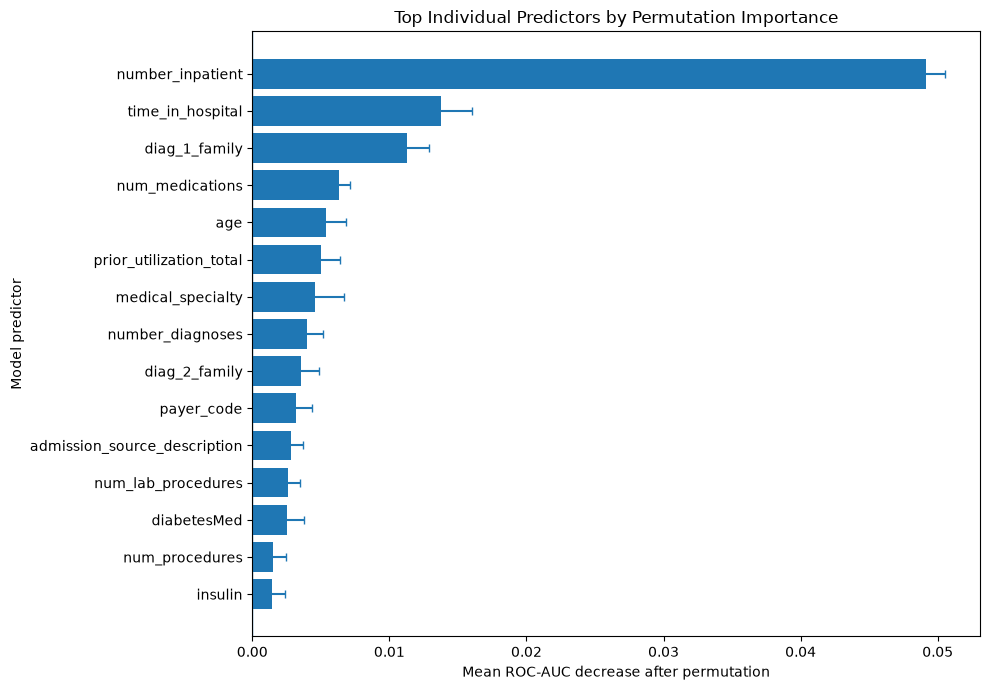

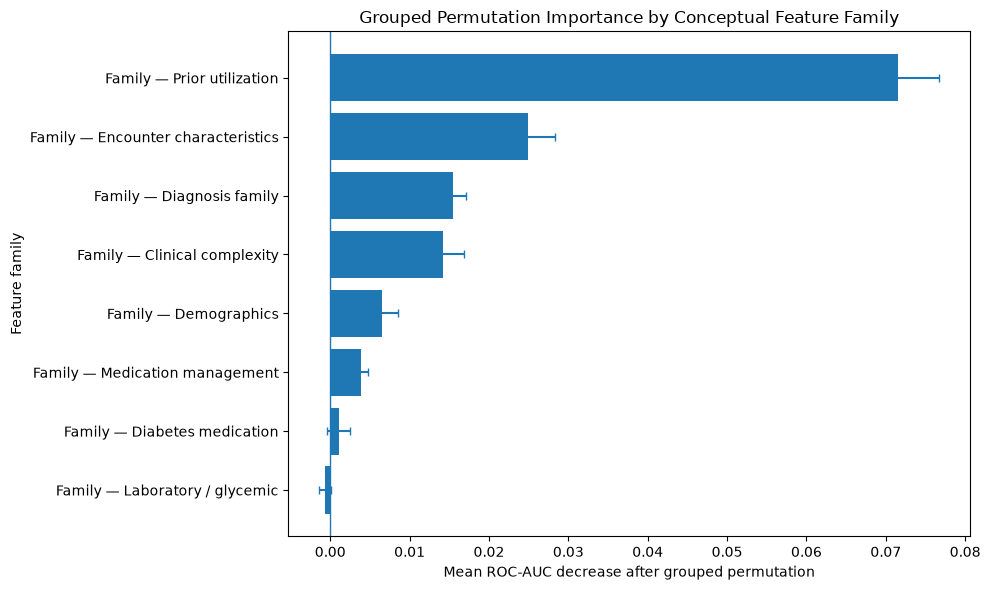

PORTFOLIO SUMMARY FIGURES
Created: reports\figures\notebook08\portfolio\global_individual_permutation_importance.png
Created: reports\figures\notebook08\portfolio\grouped_feature_family_permutation_importance.png

✓ Figures created only from existing permutation-summary DataFrames.
✓ No new permutation evaluations performed.
✓ No predictions or model fitting performed.
✓ Held-out test dataset remains unloaded.


In [42]:
# M8L.2 — Portfolio summary figures from existing results
#
# Visualization only.
# No new predictions, permutations, fitting, or test access.

from pathlib import Path
import matplotlib.pyplot as plt

PORTFOLIO_FIGURE_DIR = Path("reports/figures/notebook08/portfolio")

PORTFOLIO_FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ----------------------------------------------------------
# Figure 1 — Top individual permutation importance
# ----------------------------------------------------------

top_individual_plot_df = (
    permutation_importance_df.sort_values("roc_auc_importance_mean", ascending=False)
    .head(15)
    .sort_values("roc_auc_importance_mean", ascending=True)
    .copy()
)


fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_individual_plot_df["source_feature"],
    top_individual_plot_df["roc_auc_importance_mean"],
)

ax.errorbar(
    top_individual_plot_df["roc_auc_importance_mean"],
    top_individual_plot_df["source_feature"],
    xerr=top_individual_plot_df["roc_auc_importance_std"],
    fmt="none",
    capsize=3,
)

ax.set_title("Top Individual Predictors by Permutation Importance")

ax.set_xlabel("Mean ROC-AUC decrease after permutation")

ax.set_ylabel("Model predictor")

ax.axvline(0, linewidth=1)

fig.tight_layout()

individual_figure_path = (
    PORTFOLIO_FIGURE_DIR / "global_individual_permutation_importance.png"
)

fig.savefig(individual_figure_path, dpi=300, bbox_inches="tight")

plt.show()


# ----------------------------------------------------------
# Figure 2 — Grouped conceptual importance
# ----------------------------------------------------------

grouped_plot_df = (
    grouped_permutation_importance_df[
        grouped_permutation_importance_df["group_type"] == "conceptual_family"
    ]
    .sort_values("roc_auc_importance_mean", ascending=False)
    .sort_values("roc_auc_importance_mean", ascending=True)
    .copy()
)


fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(grouped_plot_df["group_name"], grouped_plot_df["roc_auc_importance_mean"])

ax.errorbar(
    grouped_plot_df["roc_auc_importance_mean"],
    grouped_plot_df["group_name"],
    xerr=grouped_plot_df["roc_auc_importance_std"],
    fmt="none",
    capsize=3,
)

ax.set_title("Grouped Permutation Importance by Conceptual Feature Family")

ax.set_xlabel("Mean ROC-AUC decrease after grouped permutation")

ax.set_ylabel("Feature family")

ax.axvline(0, linewidth=1)

fig.tight_layout()

grouped_figure_path = (
    PORTFOLIO_FIGURE_DIR / "grouped_feature_family_permutation_importance.png"
)

fig.savefig(grouped_figure_path, dpi=300, bbox_inches="tight")

plt.show()


# ----------------------------------------------------------
# Persistence audit
# ----------------------------------------------------------

assert individual_figure_path.exists()
assert grouped_figure_path.exists()

assert individual_figure_path.stat().st_size > 0
assert grouped_figure_path.stat().st_size > 0


print("PORTFOLIO SUMMARY FIGURES")

print("=" * 100)

print(f"Created: {individual_figure_path}")

print(f"Created: {grouped_figure_path}")

print()

print("✓ Figures created only from existing permutation-summary DataFrames.")

print("✓ No new permutation evaluations performed.")

print("✓ No predictions or model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

### M8L.3 — Portfolio Figure Manifest

A small subset of Notebook 08 figures is designated for portfolio presentation.

The selection emphasizes complementary evidence rather than the total number of plots:

- global predictor dependence;
- conceptual-family dependence;
- directionality of the strongest predictor;
- behavior of the strongest engineered categorical representation;
- nonlinear behavior of an important encounter characteristic.

All other Notebook 08 figures remain preserved as technical diagnostic artifacts.
Figure selection does not alter the model or analytical conclusions.

In [43]:
# M8L.3 — Persist portfolio figure selection
#
# Manifest creation only.
# No analytical recomputation.

from pathlib import Path
import pandas as pd

REPORTS_DIR = Path("reports")
FIGURES_DIR = Path("reports/figures/notebook08")
PORTFOLIO_DIR = FIGURES_DIR / "portfolio"


portfolio_figure_manifest_df = pd.DataFrame(
    [
        {
            "display_order": 1,
            "figure_role": "Global individual dependence",
            "filename": "global_individual_permutation_importance.png",
            "relative_path": "reports/figures/notebook08/portfolio/"
            "global_individual_permutation_importance.png",
            "primary_finding": "Prior inpatient utilization is the strongest "
            "individual predictive dependency in the locked model.",
            "recommended_use": "README headline interpretability figure",
            "principal_caveat": "Permutation importance measures predictive dependence, "
            "not causal effect.",
        },
        {
            "display_order": 2,
            "figure_role": "Conceptual-family dependence",
            "filename": "grouped_feature_family_permutation_importance.png",
            "relative_path": "reports/figures/notebook08/portfolio/"
            "grouped_feature_family_permutation_importance.png",
            "primary_finding": "Prior utilization is the dominant conceptual feature "
            "family, followed by encounter characteristics, diagnosis "
            "family, and clinical complexity.",
            "recommended_use": "README supporting global interpretability figure",
            "principal_caveat": "Grouped permutation effects are not additive across "
            "correlated feature families.",
        },
        {
            "display_order": 3,
            "figure_role": "Strongest numeric directionality",
            "filename": "pdp_number_inpatient.png",
            "relative_path": "reports/figures/notebook08/pdp_number_inpatient.png",
            "primary_finding": "Estimated readmission probability rises consistently "
            "across the supported range of prior inpatient encounters.",
            "recommended_use": "README directionality figure",
            "principal_caveat": "Partial dependence describes fitted-model behavior and "
            "does not represent an intervention effect.",
        },
        {
            "display_order": 4,
            "figure_role": "Engineered categorical behavior",
            "filename": "categorical_profile_diag_1_family.png",
            "relative_path": "reports/figures/notebook08/"
            "categorical_profile_diag_1_family.png",
            "primary_finding": "Primary diagnosis family provides the strongest engineered "
            "diagnosis-family signal and remains stable under stronger "
            "support requirements.",
            "recommended_use": "README feature-engineering interpretability figure",
            "principal_caveat": "No raw ICD-9 counterfactual model was fitted, so this does "
            "not establish superiority over raw diagnosis codes.",
        },
        {
            "display_order": 5,
            "figure_role": "Nonlinear encounter behavior",
            "filename": "pdp_time_in_hospital.png",
            "relative_path": "reports/figures/notebook08/pdp_time_in_hospital.png",
            "primary_finding": "Length of stay shows meaningful nonlinear model behavior, "
            "with increasing estimates through the central range and "
            "a decline in the upper range.",
            "recommended_use": "Technical README or interpretability section",
            "principal_caveat": "Upper-range behavior should not be interpreted as evidence "
            "that changing length of stay changes readmission risk.",
        },
    ]
)


# ----------------------------------------------------------
# Integrity checks
# ----------------------------------------------------------

assert len(portfolio_figure_manifest_df) == 5

assert portfolio_figure_manifest_df["display_order"].tolist() == [1, 2, 3, 4, 5]

assert portfolio_figure_manifest_df["relative_path"].nunique() == 5


for relative_path in portfolio_figure_manifest_df["relative_path"]:

    path = Path(relative_path)

    assert path.exists(), f"Selected portfolio figure not found: {path}"

    assert path.stat().st_size > 0


# ----------------------------------------------------------
# Export manifest
# ----------------------------------------------------------

PORTFOLIO_MANIFEST_PATH = REPORTS_DIR / "notebook08_portfolio_figure_manifest.csv"


portfolio_figure_manifest_df.to_csv(PORTFOLIO_MANIFEST_PATH, index=False)


assert PORTFOLIO_MANIFEST_PATH.exists()
assert PORTFOLIO_MANIFEST_PATH.stat().st_size > 0


# ----------------------------------------------------------
# Display
# ----------------------------------------------------------

print("NOTEBOOK 08 — PORTFOLIO FIGURE MANIFEST")

print("=" * 150)


for row in portfolio_figure_manifest_df.sort_values("display_order").itertuples(
    index=False
):

    print()

    print(f"{row.display_order}. " f"{row.figure_role}")

    print(f"   File: {row.relative_path}")

    print(f"   Finding: {row.primary_finding}")

    print(f"   Use: {row.recommended_use}")

    print(f"   Caveat: {row.principal_caveat}")


print()

print(f"Manifest saved: " f"{PORTFOLIO_MANIFEST_PATH}")

print()

print("✓ Five complementary portfolio figures selected.")

print("✓ All selected files exist and are non-empty.")

print("✓ Diagnostic figures remain preserved.")

print("✓ No analytical results recomputed.")

print("✓ No predictions or model fitting performed.")

print("✓ Held-out test dataset remains unloaded.")

NOTEBOOK 08 — PORTFOLIO FIGURE MANIFEST

1. Global individual dependence
   File: reports/figures/notebook08/portfolio/global_individual_permutation_importance.png
   Finding: Prior inpatient utilization is the strongest individual predictive dependency in the locked model.
   Use: README headline interpretability figure
   Caveat: Permutation importance measures predictive dependence, not causal effect.

2. Conceptual-family dependence
   File: reports/figures/notebook08/portfolio/grouped_feature_family_permutation_importance.png
   Finding: Prior utilization is the dominant conceptual feature family, followed by encounter characteristics, diagnosis family, and clinical complexity.
   Use: README supporting global interpretability figure
   Caveat: Grouped permutation effects are not additive across correlated feature families.

3. Strongest numeric directionality
   File: reports/figures/notebook08/pdp_number_inpatient.png
   Finding: Estimated readmission probability rises consisten

## M8M — Final Integrity and Closure Audit

Notebook 08 concludes with a reproducibility and analytical-boundary audit.

This audit verifies that:

- the locked development model and feature contracts remain unchanged;
- the completed interpretability results have been persisted;
- expected row counts from the major analyses reconcile with the notebook workflow;
- the selected portfolio figures exist;
- interpretability metadata records the intended methodological boundaries;
- no model retraining, hyperparameter modification, threshold modification, or post-hoc
  feature selection was introduced;
- the held-out test dataset remained outside the interpretability workflow.

This section performs integrity checks only. It does not recompute model predictions or
interpretability analyses.

In [44]:
# M8M.1 — Final Notebook 08 integrity and closure audit
#
# Audit only.
# No model fitting, prediction, permutation, PDP, or test access.

from pathlib import Path
import json
import pandas as pd

REPORTS_DIR = Path("reports")
FIGURES_DIR = Path("reports/figures/notebook08")

METADATA_PATH = REPORTS_DIR / "notebook08_interpretability_metadata.json"

PORTFOLIO_MANIFEST_PATH = REPORTS_DIR / "notebook08_portfolio_figure_manifest.csv"


# ----------------------------------------------------------
# 1. Core analytical contracts
# ----------------------------------------------------------

core_contract_checks = {
    "raw_predictor_count_44": len(feature_registry["model_features"]) == 44,
    "final_model_predictor_count_48": len(PERSISTED_MODEL_FEATURE_ORDER) == 48,
    "numeric_predictor_count_13": len(FINAL_NUMERIC_FEATURES) == 13,
    "categorical_predictor_count_35": len(FINAL_CATEGORICAL_FEATURES) == 35,
    "transformed_predictor_count_213": len(
        persisted_preprocessor.get_feature_names_out()
    )
    == 213,
    "hgb_input_count_213": persisted_hgb.n_features_in_ == 213,
    "feature_lineage_rows_213": len(feature_lineage_df) == 213,
    "source_taxonomy_rows_48": len(source_taxonomy_df) == 48,
    "conceptual_family_count_8": source_taxonomy_df["feature_family"].nunique() == 8,
}


# ----------------------------------------------------------
# 2. Major analytical result counts
# ----------------------------------------------------------

analysis_count_checks = {
    "individual_permutation_features_48": len(permutation_importance_df) == 48,
    "individual_permutation_runs_480": len(permutation_repeats_df) == 480,
    "grouped_permutation_groups_18": len(grouped_permutation_importance_df) == 18,
    "grouped_permutation_runs_180": len(grouped_permutation_repeats_df) == 180,
    "numeric_pdp_evaluations_80": len(pdp_results_df) == 80,
    "numeric_pdp_features_7": pdp_results_df["source_feature"].nunique() == 7,
    "categorical_profile_evaluations_65": len(categorical_profile_results_df) == 65,
    "categorical_profile_features_6": categorical_profile_results_df[
        "source_feature"
    ].nunique()
    == 6,
    "engineered_features_8": len(feature_engineering_synthesis_df) == 8,
    "triangulated_findings_9": len(evidence_triangulation_df) == 9,
    "responsible_findings_10": len(responsible_interpretation_df) == 10,
    "limitations_11": len(interpretability_limitations_df) == 11,
    "employer_findings_7": len(employer_facing_findings_export_df) == 7,
}


# ----------------------------------------------------------
# 3. Persisted analytical artifacts
# ----------------------------------------------------------

expected_csv_artifacts = [
    REPORTS_DIR / filename for filename in NOTEBOOK08_EXPORT_MANIFEST
]


artifact_checks = {
    "analytical_csv_count_23": len(expected_csv_artifacts) == 23,
    "all_analytical_csv_files_exist": all(
        path.exists() and path.stat().st_size > 0 for path in expected_csv_artifacts
    ),
    "metadata_json_exists": METADATA_PATH.exists() and METADATA_PATH.stat().st_size > 0,
    "portfolio_manifest_exists": PORTFOLIO_MANIFEST_PATH.exists()
    and PORTFOLIO_MANIFEST_PATH.stat().st_size > 0,
}


# ----------------------------------------------------------
# 4. Read persisted metadata for boundary verification
#
# Reading our Notebook 08 metadata is allowed.
# This does NOT read test.csv.
# ----------------------------------------------------------

with open(
    METADATA_PATH,
    "r",
    encoding="utf-8",
) as file:

    persisted_m8_metadata = json.load(file)


boundary_checks = {
    "model_status_locked": persisted_m8_metadata["model_status"]
    == "locked_development_model",
    "model_not_retrained": persisted_m8_metadata["model_retrained_during_notebook"]
    is False,
    "features_not_selected": persisted_m8_metadata["features_selected_during_notebook"]
    is False,
    "hyperparameters_not_modified": persisted_m8_metadata[
        "hyperparameters_modified_during_notebook"
    ]
    is False,
    "threshold_not_modified": persisted_m8_metadata[
        "threshold_modified_during_notebook"
    ]
    is False,
    "test_not_loaded": persisted_m8_metadata["held_out_test_loaded"] is False,
    "test_not_used_for_interpretability": persisted_m8_metadata[
        "held_out_test_used_for_interpretability"
    ]
    is False,
    "no_independent_final_claim": persisted_m8_metadata[
        "independent_final_evaluation_claimed"
    ]
    is False,
    "no_causal_interpretation": persisted_m8_metadata["causal_interpretation"] is False,
    "no_external_validation_claim": persisted_m8_metadata[
        "external_validation_performed"
    ]
    is False,
    "no_deployment_readiness_claim": persisted_m8_metadata[
        "deployment_readiness_claimed"
    ]
    is False,
}


# ----------------------------------------------------------
# 5. Portfolio figure verification
# ----------------------------------------------------------

persisted_portfolio_manifest_df = pd.read_csv(PORTFOLIO_MANIFEST_PATH)


selected_figure_paths = [
    Path(path) for path in persisted_portfolio_manifest_df["relative_path"]
]


all_figure_paths = sorted(
    [
        path
        for path in FIGURES_DIR.rglob("*")
        if path.is_file()
        and path.suffix.lower()
        in {
            ".png",
            ".jpg",
            ".jpeg",
            ".svg",
            ".pdf",
        }
    ]
)


figure_checks = {
    "portfolio_figures_selected_5": len(persisted_portfolio_manifest_df) == 5,
    "portfolio_paths_unique_5": persisted_portfolio_manifest_df[
        "relative_path"
    ].nunique()
    == 5,
    "all_selected_figures_exist": all(
        path.exists() and path.stat().st_size > 0 for path in selected_figure_paths
    ),
    # 11 original diagnostics + 2 portfolio summary figures
    "total_notebook08_figures_13": len(all_figure_paths) == 13,
}


# ----------------------------------------------------------
# 6. Strongest-finding consistency
# ----------------------------------------------------------

top_feature_row = permutation_importance_df.sort_values(
    "roc_auc_importance_mean", ascending=False
).iloc[0]


top_group_row = grouped_permutation_importance_df.sort_values(
    "roc_auc_importance_mean", ascending=False
).iloc[0]


finding_checks = {
    "top_individual_feature_number_inpatient": top_feature_row["source_feature"]
    == "number_inpatient",
    "top_individual_roc_decrease_matches": abs(
        float(top_feature_row["roc_auc_importance_mean"]) - 0.049161
    )
    < 1e-6,
    "top_group_prior_utilization": (
        "Prior utilization" in str(top_group_row["group_name"])
    ),
    "inpatient_pdp_strictly_increasing": (
        pdp_shape_summary_df.loc[
            pdp_shape_summary_df["source_feature"] == "number_inpatient",
            "shape_classification",
        ].iloc[0]
        == "strictly increasing"
    ),
}


# ----------------------------------------------------------
# 7. Consolidate audit
# ----------------------------------------------------------

audit_sections = {
    "Core contracts": core_contract_checks,
    "Analysis counts": analysis_count_checks,
    "Persisted artifacts": artifact_checks,
    "Interpretability boundary": boundary_checks,
    "Portfolio figures": figure_checks,
    "Finding consistency": finding_checks,
}


audit_records = []


for section, checks in audit_sections.items():

    for check_name, passed in checks.items():

        audit_records.append(
            {
                "section": section,
                "check": check_name,
                "passed": bool(passed),
            }
        )


notebook08_final_audit_df = pd.DataFrame(audit_records)


failed_checks_df = notebook08_final_audit_df.loc[
    ~notebook08_final_audit_df["passed"]
].copy()


# ----------------------------------------------------------
# 8. Display
# ----------------------------------------------------------

print("NOTEBOOK 08 — FINAL INTEGRITY AND CLOSURE AUDIT")

print("=" * 150)


for section in audit_sections:

    print()

    print(section.upper())

    print("-" * 150)

    section_rows = notebook08_final_audit_df.loc[
        notebook08_final_audit_df["section"] == section
    ]

    for row in section_rows.itertuples(index=False):

        symbol = "✓" if row.passed else "✗"

        print(f"{symbol} {row.check}")


print()

print("SUMMARY")

print("-" * 150)

print(f"Checks performed: " f"{len(notebook08_final_audit_df)}")

print(f"Checks passed: " f"{int(notebook08_final_audit_df['passed'].sum())}")

print(f"Checks failed: " f"{len(failed_checks_df)}")

print(f"Persisted analytical CSVs: " f"{len(expected_csv_artifacts)}")

print(f"Portfolio figures selected: " f"{len(persisted_portfolio_manifest_df)}")

print(f"Notebook 08 figure files: " f"{len(all_figure_paths)}")


# ----------------------------------------------------------
# 9. Hard-stop if anything failed
# ----------------------------------------------------------

if not failed_checks_df.empty:

    print()

    print("FAILED CHECKS")

    print("-" * 150)

    print(failed_checks_df.to_string(index=False))

    raise AssertionError(
        "Notebook 08 final integrity audit failed. "
        "Resolve failed checks before closure."
    )


print()

print("FINAL STATUS")

print("-" * 150)

print("✓ Locked 48 → 213 model-input contract preserved.")

print(
    "✓ Completed interpretability analyses reconcile with "
    "their expected result counts."
)

print("✓ Twenty-three canonical analytical CSV artifacts verified.")

print("✓ Interpretability metadata verified.")

print("✓ Five employer-facing portfolio figures verified.")

print("✓ Thirteen Notebook 08 figure files verified.")

print("✓ No model redevelopment introduced.")

print("✓ No causal, external-validation, or deployment-readiness " "claim introduced.")

print(
    "✓ Held-out test dataset remains outside the "
    "Notebook 08 interpretability workflow."
)

print()

print("NOTEBOOK 08 IS READY FOR CLEAN-KERNEL REPRODUCIBILITY TEST.")

NOTEBOOK 08 — FINAL INTEGRITY AND CLOSURE AUDIT

CORE CONTRACTS
------------------------------------------------------------------------------------------------------------------------------------------------------
✓ raw_predictor_count_44
✓ final_model_predictor_count_48
✓ numeric_predictor_count_13
✓ categorical_predictor_count_35
✓ transformed_predictor_count_213
✓ hgb_input_count_213
✓ feature_lineage_rows_213
✓ source_taxonomy_rows_48
✓ conceptual_family_count_8

ANALYSIS COUNTS
------------------------------------------------------------------------------------------------------------------------------------------------------
✓ individual_permutation_features_48
✓ individual_permutation_runs_480
✓ grouped_permutation_groups_18
✓ grouped_permutation_runs_180
✓ numeric_pdp_evaluations_80
✓ numeric_pdp_features_7
✓ categorical_profile_evaluations_65
✓ categorical_profile_features_6
✓ engineered_features_8
✓ triangulated_findings_9
✓ responsible_findings_10
✓ limitations_11
✓ employe